In [ ]:
import sys
!{sys.executable} -m pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.4 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import torch
from torch.utils.data import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

In [ ]:
path="/content/drive/MyDrive/dataset/all_chem_df.csv"

df=pd.read_csv(path)

df.head(5)

,image_name,tags,smiles,Col3
0,pics/0,dermatologic,CC(=O)NC1C(O)OC(CO)C(O)C1O,['dermatologic']
1,pics/1,antiinfective,CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...,['antiinfective']
2,pics/2,antiinfective,CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...,['antiinfective']
3,pics/3,antineoplastic,COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...,['antineoplastic']
4,pics/4,antiinfective respiratorysystem,CC(=O)N[C@@H](CS)C(=O)[O-],"['antiinfective', 'respiratorysystem']"


In [ ]:
print(df.shape)

print(df.columns)

df.info()

df.isnull().sum()

(8336, 4)
Index(['image_name', 'tags', 'smiles', 'Col3'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8336 entries, 0 to 8335
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_name  8336 non-null   object
 1   tags        8336 non-null   object
 2   smiles      8336 non-null   object
 3   Col3        8336 non-null   object
dtypes: object(4)
memory usage: 260.6+ KB


,0
image_name,0
tags,0
smiles,0
Col3,0


In [ ]:
df1=df[['smiles','tags']]

In [ ]:
df.head(3)

,image_name,tags,smiles,Col3
0,pics/0,dermatologic,CC(=O)NC1C(O)OC(CO)C(O)C1O,['dermatologic']
1,pics/1,antiinfective,CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...,['antiinfective']
2,pics/2,antiinfective,CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...,['antiinfective']


In [ ]:
df2=df[['smiles','Col3']]

df2=df.rename(columns={'Col3':'label'})

In [ ]:
print(df.head(2))


  image_name           tags  \
0     pics/0   dermatologic   
1     pics/1  antiinfective   

                                              smiles               Col3  
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   ['dermatologic']  
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...  ['antiinfective']  


In [ ]:
print(df1.head(2))




                                              smiles           tags
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   dermatologic
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...  antiinfective


In [ ]:
print(df2.head(2))


  image_name           tags  \
0     pics/0   dermatologic   
1     pics/1  antiinfective   

                                              smiles            label  
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   [dermatologic]  
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...  [antiinfective]  


In [ ]:
df2['label'] = df2['label'].apply(tuple)
df2.duplicated().sum()

np.int64(0)

In [ ]:
encoder=LabelEncoder()

df['label']=encoder.fit_transform(df2['label'])

print(df2.head())

  image_name                             tags  \
0     pics/0                     dermatologic   
1     pics/1                    antiinfective   
2     pics/2                    antiinfective   
3     pics/3                   antineoplastic   
4     pics/4  antiinfective respiratorysystem   

                                              smiles  \
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...   
2  CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...   
3  COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...   
4                         CC(=O)N[C@@H](CS)C(=O)[O-]   

                                label  
0                     (dermatologic,)  
1                    (antiinfective,)  
2                    (antiinfective,)  
3                   (antineoplastic,)  
4  (antiinfective, respiratorysystem)  


In [ ]:
df2["smiles"].str.len().max()
#df2["smiles"].str.len().min()

386

In [ ]:
encoder.classes_

array([('antiinfective',), ('antiinfective', 'antiinflammatory'),
       ('antiinfective', 'antineoplastic'),
       ('antiinfective', 'antineoplastic', 'antiinflammatory'),
       ('antiinfective', 'antineoplastic', 'cardio'),
       ('antiinfective', 'antineoplastic', 'hematologic', 'antiinflammatory'),
       ('antiinfective', 'antineoplastic', 'reproductivecontrol'),
       ('antiinfective', 'antineoplastic', 'reproductivecontrol', 'hematologic', 'cardio'),
       ('antiinfective', 'cardio'),
       ('antiinfective', 'cardio', 'antiinflammatory'),
       ('antiinfective', 'hematologic'),
       ('antiinfective', 'hematologic', 'antiinflammatory'),
       ('antiinfective', 'hematologic', 'cardio'),
       ('antiinfective', 'hematologic', 'respiratorysystem', 'cardio'),
       ('antiinfective', 'lipidregulating'),
       ('antiinfective', 'reproductivecontrol'),
       ('antiinfective', 'reproductivecontrol', 'lipidregulating', 'hematologic'),
       ('antiinfective', 'respiratorysys

In [ ]:
# df2['label'] = df2['label'].apply(ast.literal_eval)

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

labels = mlb.fit_transform(df2['label'])

In [ ]:
mlb.classes_

array(['antiinfective', 'antiinflammatory', 'antineoplastic', 'cardio',
       'cns', 'dermatologic', 'gastrointestinal', 'hematologic',
       'lipidregulating', 'reproductivecontrol', 'respiratorysystem',
       'urological'], dtype=object)

In [ ]:
labels

array([[0, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       ...,
       [1, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
labels[0]

array([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0])

In [ ]:
labels[1]

array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df, train_labels, test_labels = train_test_split(
    df2,
    labels,
    test_size=0.2,
    random_state=42
)

In [ ]:
import torch
import numpy as np

from torch.utils.data import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

In [ ]:
MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/501 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/166 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/9.43k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.21k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

In [ ]:
train_encodings = tokenizer(
    train_df["smiles"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = tokenizer(
    test_df["smiles"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

In [ ]:
class DrugDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.float
        )

        return item

    def __len__(self):
        return len(self.labels)

In [ ]:
train_dataset = DrugDataset(
    train_encodings,
    train_labels
)

test_dataset = DrugDataset(
    test_encodings,
    test_labels
)

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(

    MODEL_NAME,

    num_labels=len(mlb.classes_),

    problem_type="multi_label_classification"
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  179MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream t

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    # Convert logits to probabilities
    probabilities = 1 / (1 + np.exp(-logits))

    # Convert probabilities to 0/1
    predictions = (probabilities >= 0.5).astype(int)

    # Exact-match accuracy
    accuracy = accuracy_score(labels, predictions)

    # F1
    micro_f1 = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    precision = precision_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    jaccard = jaccard_score(
        labels,
        predictions,
        average="samples",
        zero_division=0
    )

    # Hamming score
    hamming = np.mean(labels == predictions)

    return {
        "accuracy": accuracy,
        "micro_f1": micro_f1,
        "macro_f1": macro_f1,
        "precision": precision,
        "recall": recall,
        "jaccard": jaccard,
        "hamming": hamming
    }

In [ ]:
training_args = TrainingArguments(

    output_dir="./results",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=50,

    weight_decay=0.05,

    lr_scheduler_type="cosine",

    warmup_ratio=0.1,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="micro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none"
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
from transformers import EarlyStoppingCallback

trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.345234,0.313854,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.900430
2,0.270135,0.267354,0.005396,0.008987,0.002530,0.900000,0.004516,0.005396,0.900829
3,0.256210,0.249262,0.200839,0.309231,0.080289,0.662273,0.201706,0.220424,0.910272
4,0.233814,0.232279,0.241607,0.369079,0.111625,0.753870,0.244355,0.265887,0.916817
5,0.215420,0.211549,0.309952,0.456647,0.174122,0.815484,0.317110,0.342476,0.924860
6,0.193848,0.194732,0.401079,0.554487,0.248090,0.767524,0.434019,0.455186,0.930556
7,0.171213,0.179187,0.468225,0.610305,0.320371,0.792468,0.496237,0.522032,0.936900
8,0.149831,0.171335,0.500600,0.640429,0.363109,0.789126,0.538886,0.560402,0.939748
9,0.119582,0.172199,0.506595,0.650252,0.383982,0.795356,0.549925,0.569994,0.941097
10,0.120596,0.161812,0.543165,0.677946,0.450015,0.809756,0.583041,0.604017,0.944844


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=17514, training_loss=0.08285036348372245, metrics={'train_runtime': 887.8388, 'train_samples_per_second': 375.519, 'train_steps_per_second': 23.484, 'total_flos': 9276226437832704.0, 'train_loss': 0.08285036348372245, 'epoch': 42.0})

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Get validation predictions
output = trainer.predict(test_dataset)

logits = output.predictions
labels = output.label_ids

# Sigmoid
probabilities = 1 / (1 + np.exp(-logits))

results = []

for threshold in np.arange(0.10, 0.91, 0.01):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    micro_f1 = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    results.append(
        [threshold, accuracy, micro_f1, macro_f1]
    )

results = np.array(results)

# Best accuracy
best_acc_idx = np.argmax(results[:, 1])

# Best Micro-F1
best_f1_idx = np.argmax(results[:, 2])

# Best Macro-F1
best_macro_idx = np.argmax(results[:, 3])

print("===================================")
print("BEST ACCURACY")
print("===================================")
print("Threshold :", results[best_acc_idx, 0])
print("Accuracy  :", results[best_acc_idx, 1])

print("\n===================================")
print("BEST MICRO-F1")
print("===================================")
print("Threshold :", results[best_f1_idx, 0])
print("Micro F1  :", results[best_f1_idx, 2])

print("\n===================================")
print("BEST MACRO-F1")
print("===================================")
print("Threshold :", results[best_macro_idx, 0])
print("Macro F1  :", results[best_macro_idx, 3])

BEST ACCURACY
Threshold : 0.5799999999999997
Accuracy  : 0.3858520900321543

BEST MICRO-F1
Threshold : 0.5699999999999997
Micro F1  : 0.5737158105403602

BEST MACRO-F1
Threshold : 0.5899999999999997
Macro F1  : 0.5602242605281357


In [ ]:
best_threshold = 0.5
best_accuracy = 0

for threshold in np.arange(0.10, 0.91, 0.01):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

print("Optimal Threshold :", best_threshold)
print("Best Accuracy     :", best_accuracy)
print("Accuracy (%)      :", best_accuracy * 100)

Optimal Threshold : 0.5799999999999997
Best Accuracy     : 0.3858520900321543
Accuracy (%)      : 38.58520900321543


In [ ]:
import numpy as np
import pandas as pd

# Replace with your actual training labels if necessary
y_train = np.array(train_dataset.labels)

label_counts = y_train.sum(axis=0)

label_distribution = pd.DataFrame({
    "Label": np.arange(len(label_counts)),
    "Positive_Count": label_counts,
    "Percentage": label_counts / len(y_train) * 100
})

print(label_distribution)

    Label  Positive_Count  Percentage
0       0            2111   35.031530
1       1             427    7.085961
2       2            1187   19.697975
3       3             912   15.134418
4       4            1104   18.320611
5       5             163    2.704945
6       6             354    5.874544
7       7             334    5.542649
8       8             147    2.439429
9       9             162    2.688350
10     10             203    3.368735
11     11              35    0.580816


In [ ]:
train_output = trainer.predict(train_dataset)

print("\n========== TRAINING RESULTS ==========")

for key, value in train_output.metrics.items():
    print(f"{key}: {value:.4f}")


========== TRAINING RESULTS ==========
test_loss: 0.1046
test_runtime: 4.1582
test_samples_per_second: 1449.1970
test_steps_per_second: 45.4530


In [ ]:
val_output = trainer.predict(test_dataset)

print("\n========== VALIDATION RESULTS ==========")

for key, value in val_output.metrics.items():
    print(f"{key}: {value:.4f}")


========== VALIDATION RESULTS ==========
test_loss: 0.2087
test_runtime: 0.4339
test_samples_per_second: 1433.5740
test_steps_per_second: 46.0960


['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']


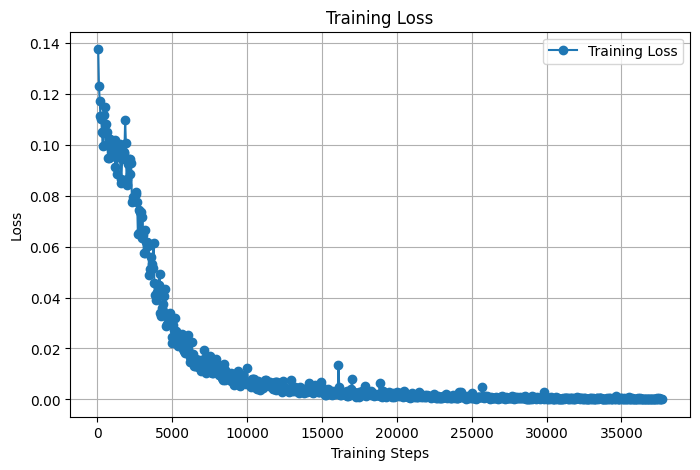

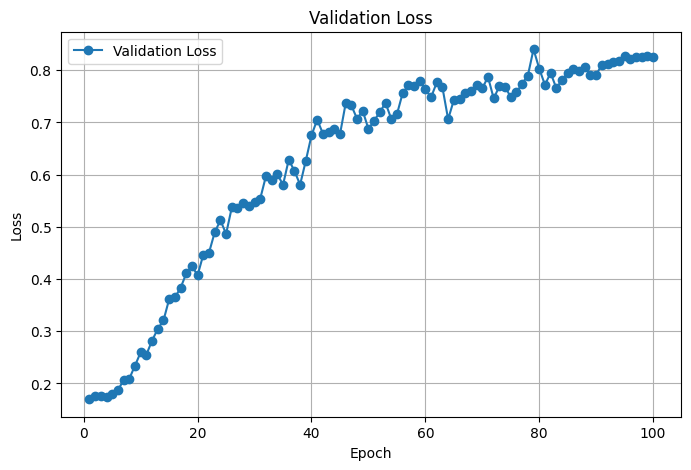

eval_accuracy was not found in trainer.state.log_history.
Make sure compute_metrics() returns 'accuracy'.
Final Training Loss   : 0.0003
Final Validation Loss : 0.8257


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# ---------------------------------------------------------
# 1. Extract training history from Hugging Face Trainer
# ---------------------------------------------------------

history = pd.DataFrame(trainer.state.log_history)

print(history.columns.tolist())

# ---------------------------------------------------------
# 2. Extract Training Loss
# ---------------------------------------------------------

train_loss = history[
    history["loss"].notna()
][["step", "loss"]].copy()

# ---------------------------------------------------------
# 3. Extract Validation/Test Loss and Accuracy
# ---------------------------------------------------------

eval_history = history[
    history["eval_loss"].notna()
].copy()

# Validation accuracy column
if "eval_accuracy" in eval_history.columns:
    eval_accuracy = eval_history["eval_accuracy"]
else:
    eval_accuracy = None

# ---------------------------------------------------------
# 4. Plot Training Loss
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    train_loss["step"],
    train_loss["loss"],
    marker="o",
    label="Training Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# 5. Plot Validation Loss
# ---------------------------------------------------------

if "eval_loss" in eval_history.columns:

    plt.figure(figsize=(8, 5))

    plt.plot(
        eval_history["epoch"],
        eval_history["eval_loss"],
        marker="o",
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

# ---------------------------------------------------------
# 6. Plot Validation Accuracy
# ---------------------------------------------------------

if "eval_accuracy" in eval_history.columns:

    plt.figure(figsize=(8, 5))

    plt.plot(
        eval_history["epoch"],
        eval_history["eval_accuracy"] * 100,
        marker="o",
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("Validation Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("eval_accuracy was not found in trainer.state.log_history.")
    print("Make sure compute_metrics() returns 'accuracy'.")

# ---------------------------------------------------------
# 7. Print Final Training Loss
# ---------------------------------------------------------

if len(train_loss) > 0:
    final_train_loss = train_loss.iloc[-1]["loss"]
    print(f"Final Training Loss   : {final_train_loss:.4f}")

# ---------------------------------------------------------
# 8. Print Final Validation Loss and Accuracy
# ---------------------------------------------------------

if len(eval_history) > 0:

    final_val_loss = eval_history.iloc[-1]["eval_loss"]

    print(f"Final Validation Loss : {final_val_loss:.4f}")

    if "eval_accuracy" in eval_history.columns:
        final_val_accuracy = eval_history.iloc[-1]["eval_accuracy"]

        print(
            f"Final Validation Accuracy : "
            f"{final_val_accuracy * 100:.2f}%"
        )

In [ ]:
model.save_pretrained(
    "/content/drive/MyDrive/ChemBERTa_Multilabel"
)

tokenizer.save_pretrained(
    "/content/drive/MyDrive/ChemBERTa_Multilabel"
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/ChemBERTa_Multilabel/tokenizer_config.json',
 '/content/drive/MyDrive/ChemBERTa_Multilabel/tokenizer.json')

In [ ]:
smiles = "CC(=O)NC1C(O)OC(CO)C(O)C1O"

inputs = tokenizer(
    smiles,
    return_tensors="pt",
    truncation=True,
    padding=True
).to(model.device)

outputs = model(**inputs)

probabilities = torch.sigmoid(outputs.logits)

predictions = (probabilities > 0.5).int().cpu().numpy()[0]

predicted_labels = mlb.inverse_transform(
    predictions.reshape(1, -1)
)

print(predicted_labels)

[('dermatologic',)]


In [ ]:
import numpy as np
import pandas as pd

y = np.array(train_dataset.labels)

# Number of labels per sample
labels_per_sample = y.sum(axis=1)

print("Average labels/sample:",
      labels_per_sample.mean())

print("Minimum labels/sample:",
      labels_per_sample.min())

print("Maximum labels/sample:",
      labels_per_sample.max())

# Most common label combinations
combination_counts = (
    pd.DataFrame(y)
    .astype(int)
    .astype(str)
    .agg("".join, axis=1)
    .value_counts()
)

print("\nMost common label combinations:")
print(combination_counts.head(20))

Average labels/sample: 1.1829634073185362
Minimum labels/sample: 1
Maximum labels/sample: 5

Most common label combinations:
100000000000    1930
001000000000     944
000010000000     927
000100000000     629
010000000000     310
101000000000     215
000000100000     208
000000010000     203
000000001000     130
000000000100     120
000100010000      97
000001000000      94
000110000000      83
000000000010      79
000010100000      67
100000100000      46
000010000010      40
100001000000      30
000100000010      29
010000000010      26
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

y_train = np.array(train_dataset.labels)

combination_ids = [
    "".join(map(str, row.astype(int)))
    for row in y_train
]

combination_counts = (
    pd.Series(combination_ids)
    .value_counts()
)

print(combination_counts.head(30))

100000000000    1930
001000000000     944
000010000000     927
000100000000     629
010000000000     310
101000000000     215
000000100000     208
000000010000     203
000000001000     130
000000000100     120
000100010000      97
000001000000      94
000110000000      83
000000000010      79
000010100000      67
100000100000      46
000010000010      40
100001000000      30
000100000010      29
010000000010      26
000000000001      26
001100000000      23
000110000010      21
100100000000      20
001001000000      20
010001000000      20
111000000000      18
001010000000      17
100010000000      16
000100000100      15
Name: count, dtype: int64


In [ ]:
label11_samples = y_train[:, 11].sum()

print("Label 11 positive samples:", label11_samples)

Label 11 positive samples: 44


In [ ]:
label11_indices = np.where(
    y_train[:, 11] == 1
)[0]

label11_combinations = [
    combination_ids[i]
    for i in label11_indices
]

print(
    pd.Series(label11_combinations).value_counts()
)

000000000001    26
000100000001    11
100000000001     7
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd
import torch

from transformers import (
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)

In [ ]:
# IMPORTANT:
# Use the original train_dataset.
# Do NOT use any oversampled/balanced dataset here.

y_train = np.array(train_dataset.labels)

n_samples = len(y_train)

positive = y_train.sum(axis=0)
negative = n_samples - positive

# BCE positive class weight
pos_weight = negative / (positive + 1e-8)

# Prevent extremely rare labels from dominating training
MAX_POS_WEIGHT = 30.0

pos_weight = np.minimum(
    pos_weight,
    MAX_POS_WEIGHT
)

pos_weight = torch.tensor(
    pos_weight,
    dtype=torch.float32
)

# Display weights
weight_table = pd.DataFrame({
    "Label": np.arange(len(positive)),
    "Positive": positive,
    "Negative": negative,
    "Percentage": positive / n_samples * 100,
    "Pos_Weight": pos_weight.numpy()
})

print(weight_table)

    Label  Positive  Negative  Percentage  Pos_Weight
0       0      2340      4328   35.092981    1.849573
1       1       483      6185    7.243551   12.805383
2       2      1315      5353   19.721056    4.070723
3       3       990      5678   14.847031    5.735353
4       4      1215      5453   18.221356    4.488066
5       5       186      6482    2.789442   30.000000
6       6       390      6278    5.848830   16.097435
7       7       353      6315    5.293941   17.889519
8       8       161      6507    2.414517   30.000000
9       9       186      6482    2.789442   30.000000
10     10       225      6443    3.374325   28.635555
11     11        44      6624    0.659868   30.000000


In [ ]:
class WeightedTrainer(Trainer):

    def __init__(
        self,
        *args,
        pos_weight=None,
        **kwargs
    ):
        super().__init__(*args, **kwargs)

        self.pos_weight = pos_weight

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        # Weighted Binary Cross Entropy
        loss_function = torch.nn.BCEWithLogitsLoss(
            pos_weight=self.pos_weight.to(
                logits.device
            )
        )

        loss = loss_function(
            logits,
            labels.float()
        )

        if return_outputs:
            return loss, outputs

        return loss

In [ ]:
training_args = TrainingArguments(

    output_dir="./weighted_cosine_results",

    # Evaluation
    eval_strategy="epoch",

    # Save model every epoch
    save_strategy="epoch",

    # Learning rate
    learning_rate=1e-5,

    # Batch size
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    # Maximum epochs
    num_train_epochs=30,

    # Regularization
    weight_decay=0.05,

    # Cosine learning-rate scheduler
    lr_scheduler_type="cosine",

    # Warm-up
    warmup_ratio=0.10,

    # Logging
    logging_steps=50,

    # Automatically restore best model
    load_best_model_at_end=True,

    # Select best model using Micro-F1
    metric_for_best_model="micro_f1",

    greater_is_better=True,

    # Keep only two checkpoints
    save_total_limit=2,

    # No external logging
    report_to="none"
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
trainer = WeightedTrainer(

    model=model,

    args=training_args,

    # ORIGINAL DATA ONLY
    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    # Class weights
    pos_weight=pos_weight,

    # Early stopping
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.063909,1.175985,0.667266,0.757531,0.642384,0.745746,0.769694,0.737330,0.950939
2,0.065520,1.186751,0.658873,0.751957,0.638624,0.733652,0.771199,0.733313,0.949341
3,0.068206,1.199163,0.667866,0.757884,0.645307,0.750246,0.765680,0.737260,0.951289
4,0.043731,1.287014,0.673861,0.760549,0.653679,0.756958,0.764175,0.739349,0.952088
5,0.043994,1.354675,0.662470,0.755567,0.649922,0.753493,0.757652,0.732634,0.951189
6,0.030330,1.332602,0.661871,0.755976,0.648452,0.750371,0.761666,0.730336,0.951039
7,0.030838,1.343369,0.663070,0.756489,0.649665,0.745614,0.767687,0.735232,0.950789
8,0.039137,1.397111,0.673861,0.757848,0.654662,0.752598,0.763171,0.737560,0.951439
9,0.025359,1.323719,0.660072,0.755666,0.649915,0.750247,0.761164,0.731884,0.950989


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
evaluation_results = trainer.evaluate()

print("\n===== FINAL VALIDATION RESULTS =====")

for key, value in evaluation_results.items():

    if isinstance(value, float):
        print(f"{key}: {value:.6f}")

    else:
        print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.025359,1.287014,9,0.673861,0.760549,0.653679,0.756958,0.764175,0.739349,0.952088



===== FINAL VALIDATION RESULTS =====
eval_loss: 1.287014
eval_accuracy: 0.673861
eval_micro_f1: 0.760549
eval_macro_f1: 0.653679
eval_precision: 0.756958
eval_recall: 0.764175
eval_jaccard: 0.739349
eval_hamming: 0.952088


In [ ]:
print(
    "Best checkpoint:",
    trainer.state.best_model_checkpoint
)

print(
    "Best Micro-F1:",
    trainer.state.best_metric
)

Best checkpoint: ./weighted_cosine_results/checkpoint-1668
Best Micro-F1: 0.7605493133583021


In [ ]:
prediction_output = trainer.predict(
    test_dataset
)

logits = prediction_output.predictions
labels = prediction_output.label_ids

# Sigmoid probabilities
probabilities = 1 / (
    1 + np.exp(-logits)
)

# Default threshold
threshold = 0.5

predictions = (
    probabilities >= threshold
).astype(int)

print("Logits shape:", logits.shape)
print("Labels shape:", labels.shape)
print("Predictions shape:", predictions.shape)

Logits shape: (1668, 12)
Labels shape: (1668, 12)
Predictions shape: (1668, 12)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score,
    hamming_loss
)

accuracy = accuracy_score(
    labels,
    predictions
)

micro_f1 = f1_score(
    labels,
    predictions,
    average="micro",
    zero_division=0
)

macro_f1 = f1_score(
    labels,
    predictions,
    average="macro",
    zero_division=0
)

precision = precision_score(
    labels,
    predictions,
    average="micro",
    zero_division=0
)

recall = recall_score(
    labels,
    predictions,
    average="micro",
    zero_division=0
)

jaccard = jaccard_score(
    labels,
    predictions,
    average="samples",
    zero_division=0
)

hamming = 1 - hamming_loss(
    labels,
    predictions
)

print("\n======================================")
print("FINAL RESULTS")
print("======================================")

print(f"Accuracy   : {accuracy:.4f}")
print(f"Micro F1   : {micro_f1:.4f}")
print(f"Macro F1   : {macro_f1:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"Jaccard    : {jaccard:.4f}")
print(f"Hamming    : {hamming:.4f}")


FINAL RESULTS
Accuracy   : 0.6739
Micro F1   : 0.7605
Macro F1   : 0.6537
Precision  : 0.7570
Recall     : 0.7642
Jaccard    : 0.7393
Hamming    : 0.9521


In [ ]:
per_label_f1 = f1_score(
    labels,
    predictions,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    labels,
    predictions,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    labels,
    predictions,
    average=None,
    zero_division=0
)

per_label_results = pd.DataFrame({

    "Label": np.arange(len(per_label_f1)),

    "Support":
        labels.sum(axis=0),

    "F1":
        per_label_f1,

    "Precision":
        per_label_precision,

    "Recall":
        per_label_recall
})

print(per_label_results)

    Label  Support        F1  Precision    Recall
0       0    583.0  0.858885   0.872566  0.845626
1       1    108.0  0.714932   0.699115  0.731481
2       2    327.0  0.784773   0.752809  0.819572
3       3    272.0  0.707566   0.797235  0.636029
4       4    313.0  0.757532   0.687500  0.843450
5       5     40.0  0.648649   0.705882  0.600000
6       6    100.0  0.593886   0.527132  0.680000
7       7    109.0  0.605128   0.686047  0.541284
8       8     42.0  0.775000   0.815789  0.738095
9       9     39.0  0.743590   0.743590  0.743590
10     10     56.0  0.654206   0.686275  0.625000
11     11      4.0  0.000000   0.000000  0.000000


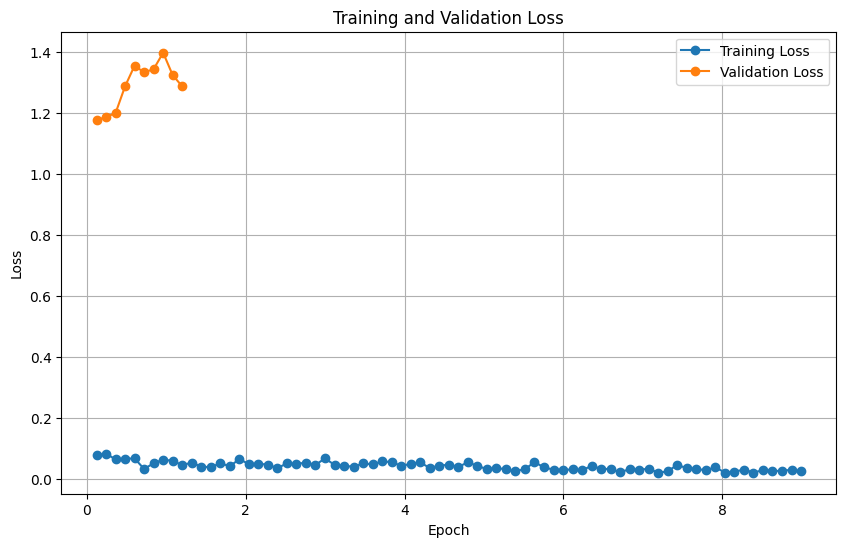

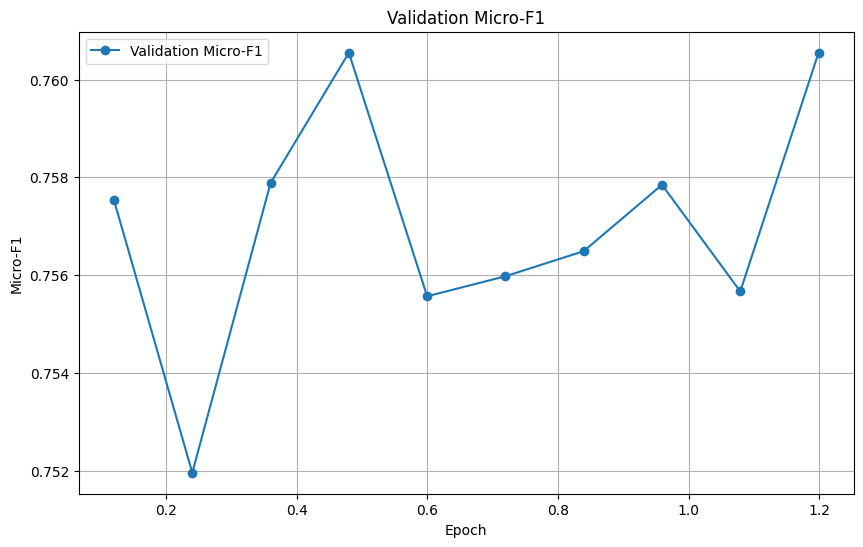

In [ ]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

epochs = []
train_losses = []
eval_losses = []
micro_f1_values = []

for item in history:

    if "epoch" in item:

        if "loss" in item:
            epochs.append(item["epoch"])
            train_losses.append(item["loss"])

        if "eval_loss" in item:
            eval_losses.append(item["eval_loss"])

        if "eval_micro_f1" in item:
            micro_f1_values.append(item["eval_micro_f1"])


# Training vs validation loss
plt.figure(figsize=(10, 6))

plt.plot(
    epochs[:len(train_losses)],
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs[:len(eval_losses)],
    eval_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Micro-F1
plt.figure(figsize=(10, 6))

plt.plot(
    epochs[:len(micro_f1_values)],
    micro_f1_values,
    marker="o",
    label="Validation Micro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Micro-F1")
plt.title("Validation Micro-F1")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="./baseline_bce_cosine",

    # Evaluation after every epoch
    eval_strategy="epoch",

    # Save checkpoint after every epoch
    save_strategy="epoch",

    # Learning rate
    learning_rate=1e-5,

    # Batch sizes
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    # Maximum epochs
    num_train_epochs=30,

    # Weight decay
    weight_decay=0.05,

    # Cosine learning-rate scheduler
    lr_scheduler_type="cosine",

    # Warm-up
    warmup_ratio=0.10,

    # Logging
    logging_steps=50,

    # Restore best model
    load_best_model_at_end=True,

    # Select best model using Micro-F1
    metric_for_best_model="micro_f1",

    greater_is_better=True,

    # Keep only best few checkpoints
    save_total_limit=2,

    # Disable external logging
    report_to="none"
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
from transformers import Trainer, EarlyStoppingCallback

trainer = Trainer(

    model=model,

    args=training_args,

    # IMPORTANT:
    # Use ORIGINAL training data
    train_dataset=train_dataset,

    # Validation/test dataset
    eval_dataset=test_dataset,

    # Your existing metric function
    compute_metrics=compute_metrics,

    # Early stopping
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.011657,0.186940,0.678657,0.769837,0.659664,0.808053,0.735073,0.730386,0.956235
2,0.007739,0.192190,0.669065,0.763560,0.648469,0.803324,0.727546,0.723321,0.955136
3,0.009534,0.201711,0.675659,0.767522,0.655294,0.811521,0.728048,0.726139,0.956085
4,0.008085,0.207877,0.673261,0.767890,0.649465,0.810479,0.729553,0.726938,0.956085
5,0.016486,0.206163,0.664269,0.767246,0.655368,0.807202,0.731059,0.721673,0.955835
6,0.011073,0.214763,0.661871,0.761202,0.651567,0.801777,0.724536,0.718375,0.954736


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
results = trainer.evaluate()

print("\n===== EXPERIMENT 1: BASELINE =====")

for key, value in results.items():

    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.011073,0.186940,6,0.678657,0.769837,0.659664,0.808053,0.735073,0.730386,0.956235



===== EXPERIMENT 1: BASELINE =====
eval_loss: 0.186940
eval_accuracy: 0.678657
eval_micro_f1: 0.769837
eval_macro_f1: 0.659664
eval_precision: 0.808053
eval_recall: 0.735073
eval_jaccard: 0.730386
eval_hamming: 0.956235


In [ ]:
print("\nBest checkpoint:")
print(trainer.state.best_model_checkpoint)

print("\nBest Micro-F1:")
print(trainer.state.best_metric)


Best checkpoint:
./baseline_bce_cosine/checkpoint-417

Best Micro-F1:
0.7698370993168681


In [ ]:
import numpy as np

prediction_output = trainer.predict(test_dataset)

logits = prediction_output.predictions
y_true = prediction_output.label_ids

# Sigmoid for multilabel classification
y_prob = 1 / (1 + np.exp(-logits))

# Standard threshold
threshold = 0.5

y_pred = (
    y_prob >= threshold
).astype(int)

print("Prediction shape:", y_pred.shape)
print("True label shape:", y_true.shape)

Prediction shape: (1668, 12)
True label shape: (1668, 12)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score,
    hamming_loss
)

accuracy = accuracy_score(
    y_true,
    y_pred
)

micro_f1 = f1_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

precision = precision_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

jaccard = jaccard_score(
    y_true,
    y_pred,
    average="samples",
    zero_division=0
)

hamming = 1 - hamming_loss(
    y_true,
    y_pred
)

print("\n========================================")
print("EXPERIMENT 1 — BASELINE RESULTS")
print("========================================")

print(f"Accuracy   : {accuracy:.6f}")
print(f"Micro-F1   : {micro_f1:.6f}")
print(f"Macro-F1   : {macro_f1:.6f}")
print(f"Precision  : {precision:.6f}")
print(f"Recall     : {recall:.6f}")
print(f"Jaccard    : {jaccard:.6f}")
print(f"Hamming    : {hamming:.6f}")


EXPERIMENT 1 — BASELINE RESULTS
Accuracy   : 0.678657
Micro-F1   : 0.769837
Macro-F1   : 0.659664
Precision  : 0.808053
Recall     : 0.735073
Jaccard    : 0.730386
Hamming    : 0.956235


In [ ]:
per_label_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

support = y_true.sum(axis=0)

per_label_results = pd.DataFrame({

    "Label": np.arange(len(per_label_f1)),

    "Support": support,

    "F1": per_label_f1,

    "Precision": per_label_precision,

    "Recall": per_label_recall
})

print(per_label_results)

    Label  Support        F1  Precision    Recall
0       0    583.0  0.855903   0.866432  0.845626
1       1    108.0  0.719626   0.726415  0.712963
2       2    327.0  0.800000   0.798780  0.801223
3       3    272.0  0.697769   0.778281  0.632353
4       4    313.0  0.771429   0.766562  0.776358
5       5     40.0  0.666667   0.793103  0.575000
6       6    100.0  0.681081   0.741176  0.630000
7       7    109.0  0.576471   0.803279  0.449541
8       8     42.0  0.767123   0.903226  0.666667
9       9     39.0  0.727273   0.888889  0.615385
10     10     56.0  0.652632   0.794872  0.553571
11     11      4.0  0.000000   0.000000  0.000000


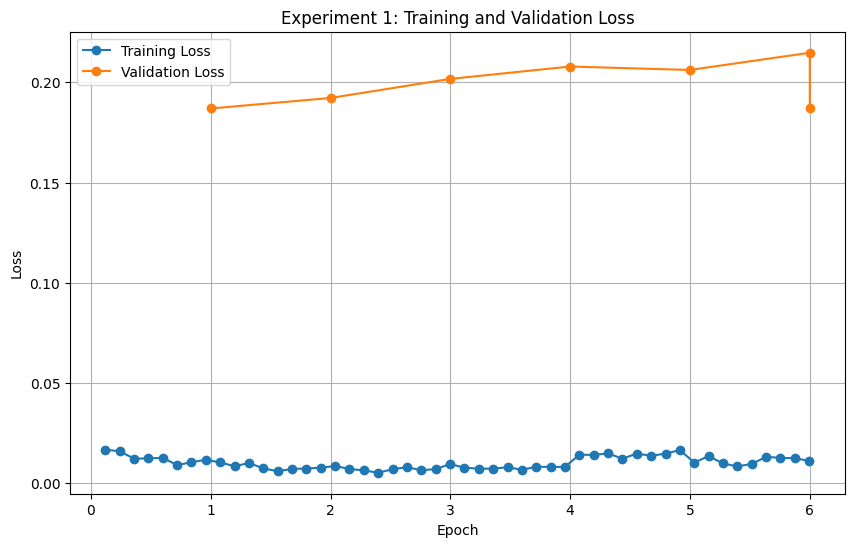

In [ ]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

train_epochs = []
train_loss = []

eval_epochs = []
eval_loss = []

eval_micro_f1 = []
eval_macro_f1 = []

for item in history:

    if "loss" in item and "epoch" in item:
        train_epochs.append(item["epoch"])
        train_loss.append(item["loss"])

    if "eval_loss" in item and "epoch" in item:
        eval_epochs.append(item["epoch"])
        eval_loss.append(item["eval_loss"])

    if "eval_micro_f1" in item:
        eval_micro_f1.append(item["eval_micro_f1"])

    if "eval_macro_f1" in item:
        eval_macro_f1.append(item["eval_macro_f1"])


# Loss graph
plt.figure(figsize=(10, 6))

plt.plot(
    train_epochs,
    train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_epochs,
    eval_loss,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Experiment 1: Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

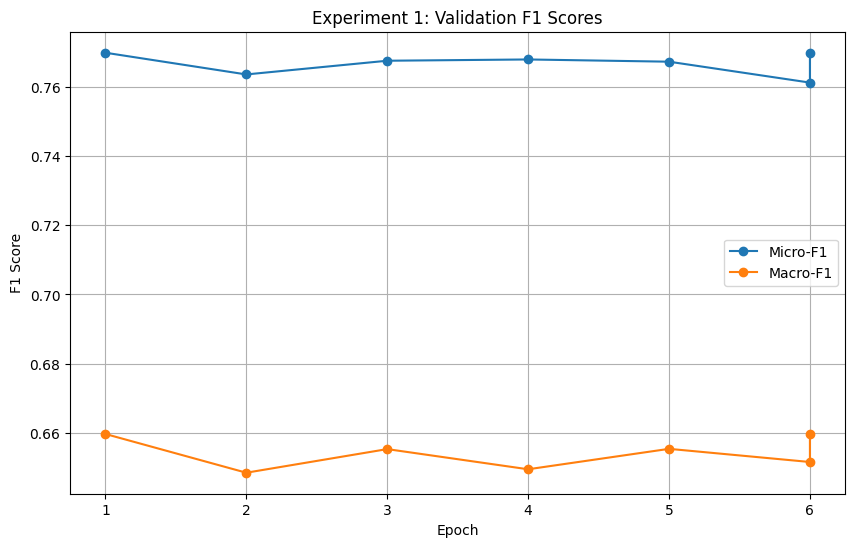

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    eval_epochs[:len(eval_micro_f1)],
    eval_micro_f1,
    marker="o",
    label="Micro-F1"
)

plt.plot(
    eval_epochs[:len(eval_macro_f1)],
    eval_macro_f1,
    marker="o",
    label="Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Experiment 1: Validation F1 Scores")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
pos_weight

tensor([ 1.8496, 12.8054,  4.0707,  5.7354,  4.4881, 30.0000, 16.0974, 17.8895,
        30.0000, 30.0000, 28.6356, 30.0000])

In [ ]:
WeightedTrainer

__main__.WeightedTrainer

In [ ]:
import numpy as np
import pandas as pd
import torch

# ORIGINAL training dataset
y_train = np.array(train_dataset.labels)

n_samples = len(y_train)

positive = y_train.sum(axis=0)
negative = n_samples - positive

# Positive class weights
pos_weight = negative / (positive + 1e-8)

# Cap extreme weights
MAX_POS_WEIGHT = 30.0

pos_weight = np.minimum(
    pos_weight,
    MAX_POS_WEIGHT
)

pos_weight = torch.tensor(
    pos_weight,
    dtype=torch.float32
)

weight_table = pd.DataFrame({
    "Label": np.arange(len(positive)),
    "Positive": positive,
    "Negative": negative,
    "Percentage": positive / n_samples * 100,
    "Weight": pos_weight.numpy()
})

print(weight_table)

    Label  Positive  Negative  Percentage     Weight
0       0      2340      4328   35.092981   1.849573
1       1       483      6185    7.243551  12.805383
2       2      1315      5353   19.721056   4.070723
3       3       990      5678   14.847031   5.735353
4       4      1215      5453   18.221356   4.488066
5       5       186      6482    2.789442  30.000000
6       6       390      6278    5.848830  16.097435
7       7       353      6315    5.293941  17.889519
8       8       161      6507    2.414517  30.000000
9       9       186      6482    2.789442  30.000000
10     10       225      6443    3.374325  28.635555
11     11        44      6624    0.659868  30.000000


In [ ]:
from transformers import Trainer

class WeightedTrainer(Trainer):

    def __init__(
        self,
        *args,
        pos_weight=None,
        **kwargs
    ):
        super().__init__(*args, **kwargs)

        self.pos_weight = pos_weight

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss_function = torch.nn.BCEWithLogitsLoss(
            pos_weight=self.pos_weight.to(logits.device)
        )

        loss = loss_function(
            logits,
            labels.float()
        )

        if return_outputs:
            return loss, outputs

        return loss

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="./experiment2_weighted_bce",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=30,

    weight_decay=0.05,

    # Cosine scheduler
    lr_scheduler_type="cosine",

    # Warmup
    warmup_ratio=0.10,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="micro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none"
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
from transformers import EarlyStoppingCallback

trainer = WeightedTrainer(

    model=model,

    args=training_args,

    # ORIGINAL DATA
    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    # Class weights
    pos_weight=pos_weight,

    # Early stopping
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.016608,1.297073,0.664868,0.756622,0.647099,0.753609,0.759659,0.732834,0.951339
2,0.019992,1.316410,0.665468,0.758448,0.646188,0.756743,0.760161,0.733603,0.951789
3,0.030310,1.391561,0.672062,0.762622,0.653418,0.763581,0.761666,0.738859,0.952788
4,0.019981,1.430189,0.665468,0.757921,0.651992,0.765881,0.750125,0.730306,0.952288
5,0.060791,1.442060,0.659472,0.758777,0.652842,0.763988,0.753638,0.728567,0.952288
6,0.027129,1.435295,0.653477,0.753428,0.639583,0.748761,0.758154,0.726369,0.950590
7,0.019374,1.429505,0.663669,0.757932,0.650566,0.754726,0.761164,0.732134,0.951589
8,0.035074,1.488025,0.678058,0.761976,0.659503,0.761785,0.762168,0.739279,0.952588


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
results = trainer.evaluate()

print("\n========================================")
print("EXPERIMENT 2 — WEIGHTED BCE")
print("========================================")

for key, value in results.items():

    if isinstance(value, float):
        print(f"{key}: {value:.6f}")

    else:
        print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.035074,1.391561,8,0.672062,0.762622,0.653418,0.763581,0.761666,0.738859,0.952788



EXPERIMENT 2 — WEIGHTED BCE
eval_loss: 1.391561
eval_accuracy: 0.672062
eval_micro_f1: 0.762622
eval_macro_f1: 0.653418
eval_precision: 0.763581
eval_recall: 0.761666
eval_jaccard: 0.738859
eval_hamming: 0.952788


In [ ]:
print("\nBest checkpoint:")
print(trainer.state.best_model_checkpoint)

print("\nBest Micro-F1:")
print(trainer.state.best_metric)


Best checkpoint:
./experiment2_weighted_bce/checkpoint-1251

Best Micro-F1:
0.7626224566691786


In [ ]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

prediction_output = trainer.predict(test_dataset)

logits = prediction_output.predictions
y_true = prediction_output.label_ids

probabilities = 1 / (
    1 + np.exp(-logits)
)

y_pred = (
    probabilities >= 0.5
).astype(int)

per_label_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

support = y_true.sum(axis=0)

per_label_results = pd.DataFrame({

    "Label": np.arange(len(per_label_f1)),

    "Support": support,

    "F1": per_label_f1,

    "Precision": per_label_precision,

    "Recall": per_label_recall
})

print(per_label_results)

    Label  Support        F1  Precision    Recall
0       0    583.0  0.854202   0.854202  0.854202
1       1    108.0  0.722222   0.722222  0.722222
2       2    327.0  0.782857   0.734584  0.837920
3       3    272.0  0.701349   0.736842  0.669118
4       4    313.0  0.756024   0.715100  0.801917
5       5     40.0  0.651163   0.608696  0.700000
6       6    100.0  0.674286   0.786667  0.590000
7       7    109.0  0.605405   0.736842  0.513761
8       8     42.0  0.746988   0.756098  0.738095
9       9     39.0  0.717949   0.717949  0.717949
10     10     56.0  0.628571   0.673469  0.589286
11     11      4.0  0.000000   0.000000  0.000000


In [ ]:
experiment2_results = {

    "Accuracy": results.get("eval_accuracy"),

    "Micro_F1": results.get("eval_micro_f1"),

    "Macro_F1": results.get("eval_macro_f1"),

    "Precision": results.get("eval_precision"),

    "Recall": results.get("eval_recall"),

    "Jaccard": results.get("eval_jaccard"),

    "Hamming": results.get("eval_hamming"),

    "Validation_Loss": results.get("eval_loss")
}

print("\nExperiment 2 Summary:")

for key, value in experiment2_results.items():
    print(f"{key}: {value:.6f}")


Experiment 2 Summary:
Accuracy: 0.672062
Micro_F1: 0.762622
Macro_F1: 0.653418
Precision: 0.763581
Recall: 0.761666
Jaccard: 0.738859
Hamming: 0.952788
Validation_Loss: 1.391561


In [ ]:
import numpy as np

y_train = np.array(train_dataset.labels)

combination_ids = np.array(
    ["".join(map(str, row.astype(int))) for row in y_train]
)

target_combinations = ["000000000001", "000100000001", "100000000001"]

for combo in target_combinations:

    indices = np.where(combination_ids == combo)[0]

    print(combo, "→", len(indices), "samples")

000000000001 → 26 samples
000100000001 → 11 samples
100000000001 → 7 samples


In [ ]:
oversample_factor = 3

extra_indices = []

for combo in target_combinations:

    indices = np.where(
        combination_ids == combo
    )[0]

    # Add two additional copies
    # Original = 1×
    # Additional = 2×
    # Final = 3×
    for _ in range(oversample_factor - 1):

        extra_indices.extend(
            indices.tolist()
        )

extra_indices = np.array(extra_indices)

print(
    "Additional samples:",
    len(extra_indices)
)

Additional samples: 88


In [ ]:
original_indices = np.arange(
    len(train_dataset)
)

new_indices = np.concatenate([
    original_indices,
    extra_indices
])

np.random.seed(42)

np.random.shuffle(
    new_indices
)

# Manually select encodings and labels using new_indices
balanced_train_encodings = {
    key: [train_encodings[key][i] for i in new_indices]
    for key in train_encodings
}

balanced_train_labels = [train_labels[i] for i in new_indices]

balanced_train_dataset = DrugDataset(
    balanced_train_encodings,
    balanced_train_labels
)

print(
    "Original training samples:",
    len(train_dataset)
)

print(
    "Oversampled training samples:",
    len(balanced_train_dataset)
)

Original training samples: 6668
Oversampled training samples: 6756


In [ ]:
from transformers import (
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)

In [ ]:
training_args = TrainingArguments(

    output_dir="./experiment3_oversampling",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=30,

    weight_decay=0.05,

    lr_scheduler_type="cosine",

    warmup_ratio=0.10,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="micro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none"
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
trainer = Trainer(

    model=model,

    args=training_args,

    # IMPORTANT:
    # Use oversampled dataset
    train_dataset=balanced_train_dataset,

    # Keep evaluation data unchanged
    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)


In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.009314,0.201173,0.676259,0.767937,0.659481,0.806291,0.733066,0.729516,0.955885
2,0.012100,0.200385,0.676259,0.770042,0.665535,0.811562,0.732564,0.727718,0.956435
3,0.013103,0.205195,0.673861,0.765768,0.654212,0.800328,0.734069,0.725939,0.955286
4,0.015252,0.205357,0.679856,0.769914,0.663659,0.802832,0.739589,0.733313,0.955985
5,0.010617,0.211216,0.675060,0.767036,0.649604,0.809816,0.728550,0.726339,0.955935
6,0.012018,0.218971,0.669664,0.760881,0.651063,0.796815,0.728048,0.721393,0.954436
7,0.009048,0.217632,0.669065,0.762738,0.649682,0.782884,0.743603,0.728537,0.953937


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
print(trainer.state.log_history)

[{'loss': 0.015363576412200928, 'grad_norm': 1.8545775413513184, 'learning_rate': 3.861308116627266e-07, 'epoch': 0.1182033096926714, 'step': 50}, {'loss': 0.016285579204559326, 'grad_norm': 1.9028440713882446, 'learning_rate': 7.801418439716313e-07, 'epoch': 0.2364066193853428, 'step': 100}, {'loss': 0.01177814245223999, 'grad_norm': 2.9425790309906006, 'learning_rate': 1.174152876280536e-06, 'epoch': 0.3546099290780142, 'step': 150}, {'loss': 0.012696412801742553, 'grad_norm': 0.23750901222229004, 'learning_rate': 1.5681639085894407e-06, 'epoch': 0.4728132387706856, 'step': 200}, {'loss': 0.010678138732910156, 'grad_norm': 0.40683624148368835, 'learning_rate': 1.9621749408983455e-06, 'epoch': 0.5910165484633569, 'step': 250}, {'loss': 0.011498627662658691, 'grad_norm': 0.4982388913631439, 'learning_rate': 2.35618597320725e-06, 'epoch': 0.7092198581560284, 'step': 300}, {'loss': 0.010692238807678223, 'grad_norm': 1.0633187294006348, 'learning_rate': 2.7501970055161548e-06, 'epoch': 0.

In [ ]:
results = trainer.evaluate()

print("\n===== EXPERIMENT 3 FINAL RESULTS =====")

for key, value in results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.009048,0.200385,7,0.676259,0.770042,0.665535,0.811562,0.732564,0.727718,0.956435



===== EXPERIMENT 3 FINAL RESULTS =====
eval_loss: 0.200385
eval_accuracy: 0.676259
eval_micro_f1: 0.770042
eval_macro_f1: 0.665535
eval_precision: 0.811562
eval_recall: 0.732564
eval_jaccard: 0.727718
eval_hamming: 0.956435


In [ ]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)
import numpy as np
import pandas as pd

prediction_output = trainer.predict(test_dataset)

logits = prediction_output.predictions
y_true = prediction_output.label_ids

# Sigmoid
probabilities = 1 / (1 + np.exp(-logits))

# Default threshold
y_pred = (probabilities >= 0.5).astype(int)

per_label_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

support = y_true.sum(axis=0)

per_label_results = pd.DataFrame({
    "Label": np.arange(len(per_label_f1)),
    "Support": support,
    "F1": per_label_f1,
    "Precision": per_label_precision,
    "Recall": per_label_recall
})

print(per_label_results.to_string(index=False))

 Label  Support       F1  Precision   Recall
     0    583.0 0.857391   0.869489 0.845626
     1    108.0 0.718182   0.705357 0.731481
     2    327.0 0.798107   0.824104 0.773700
     3    272.0 0.698795   0.769912 0.639706
     4    313.0 0.762951   0.750000 0.776358
     5     40.0 0.647059   0.785714 0.550000
     6    100.0 0.674157   0.769231 0.600000
     7    109.0 0.581818   0.857143 0.440367
     8     42.0 0.805556   0.966667 0.690476
     9     39.0 0.782609   0.900000 0.692308
    10     56.0 0.659794   0.780488 0.571429
    11      4.0 0.000000   0.000000 0.000000


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModel,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score,
    hamming_loss
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print(tokenizer)

RobertaTokenizer(name_or_path='seyonec/ChemBERTa-zinc-base-v1', vocab_size=767, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'cls_token': '<s>', 'mask_token': '<mask>'}, added_tokens_decoder={
	0: AddedToken("<s>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	1: AddedToken("<pad>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	2: AddedToken("</s>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	3: AddedToken("<unk>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	4: AddedToken("<mask>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})


In [ ]:
NUM_LABELS = 12

LABEL_COLUMNS = [
    f"label_{i}"
    for i in range(NUM_LABELS)
]

SMILES_COLUMN = "SMILES"

print(LABEL_COLUMNS)

['label_0', 'label_1', 'label_2', 'label_3', 'label_4', 'label_5', 'label_6', 'label_7', 'label_8', 'label_9', 'label_10', 'label_11']


In [ ]:
# Re-create labels to ensure it's the full set of multi-hot encoded labels
# from the MultiLabelBinarizer. This ensures 'labels' has 8336 entries.
labels = mlb.fit_transform(df2['label'])

# Rename the 'smiles' column in 'df' to match the global SMILES_COLUMN variable
# ('SMILES') to avoid a KeyError later when accessing df[SMILES_COLUMN].
if 'smiles' in df.columns and SMILES_COLUMN != 'smiles':
    df = df.rename(columns={'smiles': SMILES_COLUMN})

df["labels"] = labels.tolist()

df = df[
    [SMILES_COLUMN, "labels"]
].copy()

df = df.dropna(
    subset=[SMILES_COLUMN]
)

print(df.head())

                                              SMILES  \
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...   
2  CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...   
3  COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...   
4                         CC(=O)N[C@@H](CS)C(=O)[O-]   

                                 labels  
0  [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]  
1  [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]  
2  [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]  
3  [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]  
4  [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0]  


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Test :", len(test_df))

Train: 6668
Test : 1668


In [ ]:
train_dataset = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df,
    preserve_index=False
)

print(train_dataset)
print(test_dataset)

Dataset({
    features: ['SMILES', 'labels'],
    num_rows: 6668
})
Dataset({
    features: ['SMILES', 'labels'],
    num_rows: 1668
})


In [ ]:
MAX_LENGTH = 128

def tokenize_function(examples):

    tokenized = tokenizer(
        examples[SMILES_COLUMN],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )

    tokenized["labels"] = examples["labels"]

    return tokenized

In [ ]:
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=train_dataset.column_names
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=test_dataset.column_names
)

Map:   0%|          | 0/6668 [00:00<?, ? examples/s]

Map:   0%|          | 0/1668 [00:00<?, ? examples/s]

In [ ]:
train_dataset.set_format(
    type="torch"
)

test_dataset.set_format(
    type="torch"
)

print(train_dataset.column_names)

['labels', 'input_ids', 'attention_mask']


In [ ]:
train_dataset.reset_format()
test_dataset.reset_format()

In [ ]:
class ChemBERTaMultiLabel(nn.Module):

    def __init__(
        self,
        model_name,
        num_labels=12,
        dropout=0.20
    ):

        super().__init__()

        self.chemberta = AutoModel.from_pretrained(
            model_name
        )

        hidden_size = (
            self.chemberta.config.hidden_size
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_size,
                256
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                num_labels
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        labels=None
    ):

        outputs = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        token_embeddings = (
            outputs.last_hidden_state
        )

        # Attention-mask aware mean pooling
        mask = attention_mask.unsqueeze(
            -1
        ).float()

        pooled = (
            token_embeddings * mask
        ).sum(dim=1) / mask.sum(
            dim=1
        ).clamp(min=1e-9)

        pooled = self.dropout(
            pooled
        )

        logits = self.classifier(
            pooled
        )

        loss = None

        if labels is not None:

            loss_function = (
                nn.BCEWithLogitsLoss()
            )

            loss = loss_function(
                logits,
                labels.float()
            )

        return {
            "loss": loss,
            "logits": logits
        }

In [ ]:
model = ChemBERTaMultiLabel(
    model_name=MODEL_NAME,
    num_labels=NUM_LABELS,
    dropout=0.20
)

model = model.to(device)

print(
    "Number of labels:",
    NUM_LABELS
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Number of labels: 12


In [ ]:
def compute_metrics(eval_pred):

    logits = eval_pred.predictions
    labels = eval_pred.label_ids

    probabilities = 1 / (
        1 + np.exp(-logits)
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    micro_f1 = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    precision = precision_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    jaccard = jaccard_score(
        labels,
        predictions,
        average="samples",
        zero_division=0
    )

    hamming = 1 - hamming_loss(
        labels,
        predictions
    )

    return {

        "accuracy": accuracy,

        "micro_f1": micro_f1,

        "macro_f1": macro_f1,

        "precision": precision,

        "recall": recall,

        "jaccard": jaccard,

        "hamming": hamming
    }

In [ ]:
training_args = TrainingArguments(

    output_dir="./chemberta_final",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=100,

    weight_decay=0.05,

    lr_scheduler_type="cosine",

    warmup_ratio=0.10,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none",

    fp16=torch.cuda.is_available()
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
training_args = TrainingArguments(

    output_dir="./chemberta_final",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=100,

    weight_decay=0.05,

    lr_scheduler_type="cosine",

    warmup_ratio=0.10,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none",

    fp16=torch.cuda.is_available()
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
metric_for_best_model="macro_f1"

In [ ]:
trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.560692,0.486478,0.000600,0.003986,0.002033,0.285714,0.002007,0.001169,0.900130
2,0.301626,0.287352,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.900430
3,0.287735,0.274549,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.900430
4,0.266438,0.261854,0.091127,0.153010,0.038260,0.782407,0.084797,0.096223,0.906525
5,0.256412,0.250839,0.182854,0.291200,0.081286,0.717949,0.182639,0.200140,0.911471
6,0.247391,0.238368,0.253597,0.379765,0.106091,0.704762,0.259910,0.281025,0.915468
7,0.233876,0.226579,0.318345,0.445205,0.135235,0.701187,0.326141,0.352868,0.919065
8,0.213885,0.221412,0.361511,0.483301,0.152024,0.695570,0.370296,0.399780,0.921163
9,0.196285,0.211336,0.374101,0.508041,0.174000,0.734345,0.388359,0.414918,0.925110
10,0.198351,0.204792,0.401079,0.531392,0.183252,0.748405,0.411942,0.441297,0.927658


In [ ]:
final_results = trainer.evaluate()

print("\n==========================================")
print("FINAL CHEMBERTA RESULTS")
print("==========================================")

for key, value in final_results.items():

    if isinstance(value, float):

        print(
            f"{key}: {value:.6f}"
        )

    else:

        print(
            f"{key}: {value}"
        )

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.016237,0.256476,44,0.639688,0.734104,0.621935,0.770546,0.700953,0.693665,0.949440



FINAL CHEMBERTA RESULTS
eval_loss: 0.256476
eval_accuracy: 0.639688
eval_micro_f1: 0.734104
eval_macro_f1: 0.621935
eval_precision: 0.770546
eval_recall: 0.700953
eval_jaccard: 0.693665
eval_hamming: 0.949440


In [ ]:
prediction_output = trainer.predict(
    test_dataset
)

logits = prediction_output.predictions

y_true = prediction_output.label_ids

probabilities = 1 / (
    1 + np.exp(-logits)
)

y_pred = (
    probabilities >= 0.5
).astype(int)

print(
    "Logits:",
    logits.shape
)

print(
    "Predictions:",
    y_pred.shape
)

Logits: (1668, 12)
Predictions: (1668, 12)


In [ ]:
per_label_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

support = y_true.sum(
    axis=0
)

per_label_results = pd.DataFrame({

    "Label": np.arange(NUM_LABELS),

    "Support": support,

    "F1": per_label_f1,

    "Precision": per_label_precision,

    "Recall": per_label_recall
})

print(
    per_label_results.to_string(
        index=False
    )
)

 Label  Support       F1  Precision   Recall
     0      583 0.841367   0.860215 0.823328
     1      108 0.688372   0.691589 0.685185
     2      327 0.745342   0.757098 0.733945
     3      272 0.680608   0.704724 0.658088
     4      313 0.728732   0.732258 0.725240
     5       40 0.695652   0.827586 0.600000
     6      100 0.549708   0.661972 0.470000
     7      109 0.568047   0.800000 0.440367
     8       42 0.682927   0.700000 0.666667
     9       39 0.714286   0.806452 0.641026
    10       56 0.568182   0.781250 0.446429
    11        4 0.000000   0.000000 0.000000


In [ ]:
from sklearn.metrics import f1_score

def find_best_thresholds(
    y_true,
    probabilities
):

    thresholds = np.arange(
        0.10,
        0.91,
        0.05
    )

    best_thresholds = []

    for label in range(
        y_true.shape[1]
    ):

        best_f1 = -1

        best_threshold = 0.5

        for threshold in thresholds:

            pred = (
                probabilities[:, label]
                >= threshold
            ).astype(int)

            score = f1_score(
                y_true[:, label],
                pred,
                zero_division=0
            )

            if score > best_f1:

                best_f1 = score

                best_threshold = threshold

        best_thresholds.append(
            best_threshold
        )

    return np.array(
        best_thresholds
    )

In [ ]:
best_thresholds = find_best_thresholds(
    y_true,
    probabilities
)

print(
    "Optimized thresholds:"
)

for i, threshold in enumerate(
    best_thresholds
):

    print(
        f"Label {i}: {threshold:.2f}"
    )

Optimized thresholds:
Label 0: 0.55
Label 1: 0.75
Label 2: 0.20
Label 3: 0.60
Label 4: 0.15
Label 5: 0.50
Label 6: 0.25
Label 7: 0.15
Label 8: 0.80
Label 9: 0.70
Label 10: 0.50
Label 11: 0.10


In [ ]:
optimized_predictions = np.zeros_like(
    probabilities,
    dtype=int
)

for label in range(NUM_LABELS):

    optimized_predictions[:, label] = (
        probabilities[:, label]
        >= best_thresholds[label]
    ).astype(int)

In [ ]:
optimized_accuracy = accuracy_score(
    y_true,
    optimized_predictions
)

optimized_micro_f1 = f1_score(
    y_true,
    optimized_predictions,
    average="micro",
    zero_division=0
)

optimized_macro_f1 = f1_score(
    y_true,
    optimized_predictions,
    average="macro",
    zero_division=0
)

optimized_precision = precision_score(
    y_true,
    optimized_predictions,
    average="micro",
    zero_division=0
)

optimized_recall = recall_score(
    y_true,
    optimized_predictions,
    average="micro",
    zero_division=0
)

optimized_jaccard = jaccard_score(
    y_true,
    optimized_predictions,
    average="samples",
    zero_division=0
)

optimized_hamming = 1 - hamming_loss(
    y_true,
    optimized_predictions
)

print("\n==========================================")
print("OPTIMIZED THRESHOLD RESULTS")
print("==========================================")

print(
    f"Accuracy   : {optimized_accuracy:.6f}"
)

print(
    f"Micro-F1   : {optimized_micro_f1:.6f}"
)

print(
    f"Macro-F1   : {optimized_macro_f1:.6f}"
)

print(
    f"Precision  : {optimized_precision:.6f}"
)

print(
    f"Recall     : {optimized_recall:.6f}"
)

print(
    f"Jaccard    : {optimized_jaccard:.6f}"
)

print(
    f"Hamming    : {optimized_hamming:.6f}"
)


OPTIMIZED THRESHOLD RESULTS
Accuracy   : 0.642086
Micro-F1   : 0.740531
Macro-F1   : 0.635152
Precision  : 0.761123
Recall     : 0.721024
Jaccard    : 0.702558
Hamming    : 0.949690


In [ ]:
optimized_f1 = f1_score(
    y_true,
    optimized_predictions,
    average=None,
    zero_division=0
)

optimized_precision_label = precision_score(
    y_true,
    optimized_predictions,
    average=None,
    zero_division=0
)

optimized_recall_label = recall_score(
    y_true,
    optimized_predictions,
    average=None,
    zero_division=0
)

optimized_results = pd.DataFrame({

    "Label": np.arange(NUM_LABELS),

    "Support": y_true.sum(axis=0),

    "Threshold": best_thresholds,

    "F1": optimized_f1,

    "Precision": optimized_precision_label,

    "Recall": optimized_recall_label
})

print(
    optimized_results.to_string(
        index=False
    )
)

 Label  Support  Threshold       F1  Precision   Recall
     0      583       0.55 0.841828   0.863063 0.821612
     1      108       0.75 0.696517   0.752688 0.648148
     2      327       0.20 0.755882   0.728045 0.785933
     3      272       0.60 0.682171   0.721311 0.647059
     4      313       0.15 0.736842   0.696023 0.782748
     5       40       0.50 0.695652   0.827586 0.600000
     6      100       0.25 0.589474   0.622222 0.560000
     7      109       0.15 0.594595   0.723684 0.504587
     8       42       0.80 0.722222   0.866667 0.619048
     9       39       0.70 0.738462   0.923077 0.615385
    10       56       0.50 0.568182   0.781250 0.446429
    11        4       0.10 0.000000   0.000000 0.000000


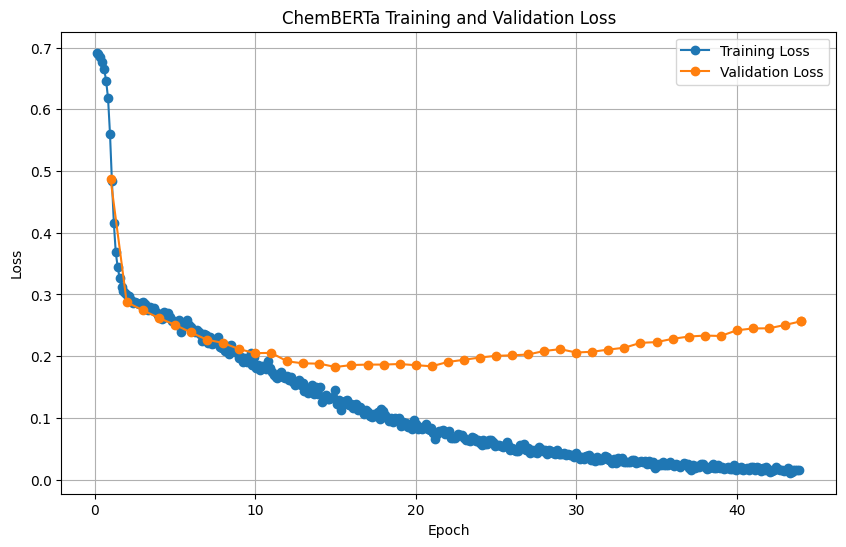

In [ ]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

train_epochs = []
train_losses = []

eval_epochs = []
eval_losses = []

for item in history:

    if (
        "loss" in item
        and "epoch" in item
    ):

        train_epochs.append(
            item["epoch"]
        )

        train_losses.append(
            item["loss"]
        )

    if (
        "eval_loss" in item
        and "epoch" in item
    ):

        eval_epochs.append(
            item["epoch"]
        )

        eval_losses.append(
            item["eval_loss"]
        )

plt.figure(figsize=(10, 6))

plt.plot(
    train_epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_epochs,
    eval_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ChemBERTa Training and Validation Loss"
)

plt.legend()

plt.grid(True)

plt.show()

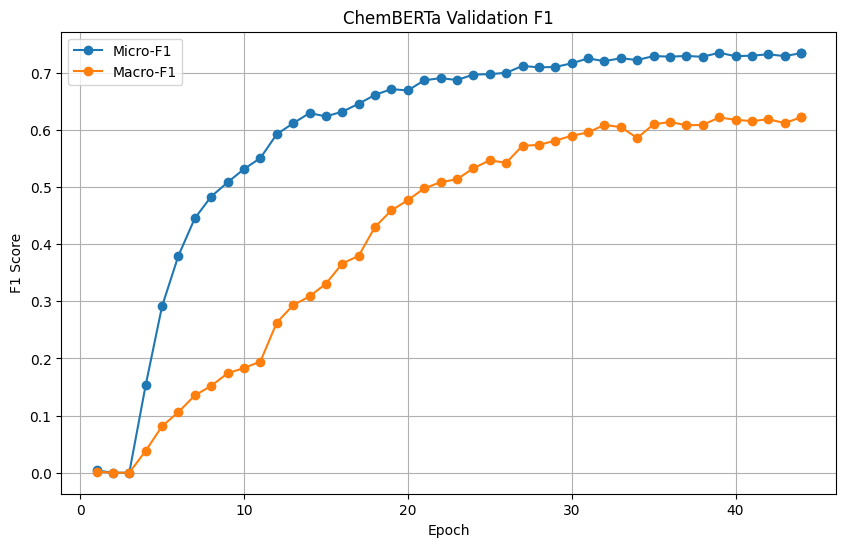

In [ ]:
eval_micro_f1 = []
eval_macro_f1 = []

f1_epochs = []

for item in history:

    if "eval_micro_f1" in item:

        f1_epochs.append(
            item["epoch"]
        )

        eval_micro_f1.append(
            item["eval_micro_f1"]
        )

        eval_macro_f1.append(
            item["eval_macro_f1"]
        )

plt.figure(figsize=(10, 6))

plt.plot(
    f1_epochs,
    eval_micro_f1,
    marker="o",
    label="Micro-F1"
)

plt.plot(
    f1_epochs,
    eval_macro_f1,
    marker="o",
    label="Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.title(
    "ChemBERTa Validation F1"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# Define train_df and test_df
# ============================================================

from sklearn.model_selection import train_test_split

# Create row indices
indices = np.arange(len(df))

# Split indices
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

# Create DataFrames
train_df = df.iloc[train_idx].copy().reset_index(drop=True)
test_df  = df.iloc[test_idx].copy().reset_index(drop=True)

# Reset labels according to the same indices
train_labels = labels[train_idx]
test_labels  = labels[test_idx]

print("Train DataFrame shape :", train_df.shape)
print("Test DataFrame shape  :", test_df.shape)

print("Train labels shape    :", train_labels.shape)
print("Test labels shape     :", test_labels.shape)

display(train_df.head())

Train DataFrame shape : (6668, 5)
Test DataFrame shape  : (1668, 5)
Train labels shape    : (6668, 12)
Test labels shape     : (1668, 12)


,image_name,tags,smiles,Col3,label
0,pics/6520,antiinfective antineoplastic,Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1,"['antiinfective', 'antineoplastic']",2
1,pics/2199,cns,C=CCN(CC=C)[C@@H](Cc1ccc(O)cc1)C(=O)NCC(=O)NCC...,['cns'],34
2,pics/2922,gastrointestinal antiinfective,CCCCCCCCCCCCCCCCCC(=O)[O-].CC[C@H]1OC(=O)[C@H]...,"['gastrointestinal', 'antiinfective']",68
3,pics/1321,antiinfective,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=C(COC...,['antiinfective'],0
4,pics/6831,cns,COC(=O)[C@H]1[C@@H](O)C[C@@H]2CC[C@H]1[NH+]2C,['cns'],34


In [ ]:
# Verify that dataframe and labels have the same number of samples

assert len(train_df) == len(train_labels)
assert len(test_df) == len(test_labels)

print("✓ Train data and labels are aligned")
print("✓ Test data and labels are aligned")

✓ Train data and labels are aligned
✓ Test data and labels are aligned


In [ ]:
print(train_df.columns.tolist())

['image_name', 'tags', 'smiles', 'Col3', 'label']


In [ ]:
display(
    train_df[
        ['image_name', 'tags', 'smiles', 'Col3']
    ].head(10)
)

,image_name,tags,smiles,Col3
0,pics/6520,antiinfective antineoplastic,Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1,"['antiinfective', 'antineoplastic']"
1,pics/2199,cns,C=CCN(CC=C)[C@@H](Cc1ccc(O)cc1)C(=O)NCC(=O)NCC...,['cns']
2,pics/2922,gastrointestinal antiinfective,CCCCCCCCCCCCCCCCCC(=O)[O-].CC[C@H]1OC(=O)[C@H]...,"['gastrointestinal', 'antiinfective']"
3,pics/1321,antiinfective,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=C(COC...,['antiinfective']
4,pics/6831,cns,COC(=O)[C@H]1[C@@H](O)C[C@@H]2CC[C@H]1[NH+]2C,['cns']
5,pics/8201,dermatologic antiinfective,CN(C)CCC[Si](C)(C)[O-].[Si+4].c1ccc2c(c1)-c1cc...,"['dermatologic', 'antiinfective']"
6,pics/1701,antiinfective,CCN(CC)CCNc1ccc(CO)c2sc3ccccc3c(=O)c12,['antiinfective']
7,pics/7218,cardio,CCCN=c1ccn(Cc2ccccc2)c2cc(Cl)ccc12,['cardio']
8,pics/4638,antiinfective,CCOC(=O)OC(C)OC(=O)[C@@H]1N2C(=O)C(NC(=O)[C@H]...,['antiinfective']
9,pics/6939,hematologic,CN1C2=CC(=O)/C(=N\NC(N)=O)C=C2CC1S(=O)(=O)[O-],['hematologic']


In [ ]:
MultiLabelBinarizer()

MultiLabelBinarizer()

In [ ]:
# ============================================================
# Calculate Class Weights for MULTI-LABEL Classification
# ============================================================

import numpy as np
import torch

# train_labels shape = (6668, 12)
y_train = train_labels

print("y_train shape:", y_train.shape)

# ------------------------------------------------------------
# Positive and negative samples for each label
# ------------------------------------------------------------

positive_counts = y_train.sum(axis=0)

negative_counts = len(y_train) - positive_counts

# Avoid division by zero
positive_counts = np.maximum(positive_counts, 1)

# pos_weight = Negative / Positive
pos_weight = negative_counts / positive_counts

# Convert to PyTorch tensor
pos_weight = torch.tensor(
    pos_weight,
    dtype=torch.float32
)

# Move to GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pos_weight = pos_weight.to(device)

# ------------------------------------------------------------
# Display class statistics
# ------------------------------------------------------------

print("\nClass Statistics")
print("-" * 60)

for i in range(len(positive_counts)):

    print(
        f"Label {i:2d} | "
        f"Positive: {int(positive_counts[i]):4d} | "
        f"Negative: {int(negative_counts[i]):4d} | "
        f"Weight: {pos_weight[i].item():.4f}"
    )

print("\nFinal pos_weight:")
print(pos_weight)

y_train shape: (6668, 12)

Class Statistics
------------------------------------------------------------
Label  0 | Positive: 2340 | Negative: 4328 | Weight: 1.8496
Label  1 | Positive:  483 | Negative: 6185 | Weight: 12.8054
Label  2 | Positive: 1315 | Negative: 5353 | Weight: 4.0707
Label  3 | Positive:  990 | Negative: 5678 | Weight: 5.7354
Label  4 | Positive: 1215 | Negative: 5453 | Weight: 4.4881
Label  5 | Positive:  186 | Negative: 6482 | Weight: 34.8495
Label  6 | Positive:  390 | Negative: 6278 | Weight: 16.0974
Label  7 | Positive:  353 | Negative: 6315 | Weight: 17.8895
Label  8 | Positive:  161 | Negative: 6507 | Weight: 40.4161
Label  9 | Positive:  186 | Negative: 6482 | Weight: 34.8495
Label 10 | Positive:  225 | Negative: 6443 | Weight: 28.6356
Label 11 | Positive:   44 | Negative: 6624 | Weight: 150.5455

Final pos_weight:
tensor([  1.8496,  12.8054,   4.0707,   5.7354,   4.4881,  34.8495,  16.0974,
         17.8895,  40.4161,  34.8495,  28.6356, 150.5455], device='cu

In [ ]:
display(train_df.head())

,image_name,tags,smiles,label
6520,pics/6520,antiinfective antineoplastic,Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1,"(antiinfective, antineoplastic)"
2199,pics/2199,cns,C=CCN(CC=C)[C@@H](Cc1ccc(O)cc1)C(=O)NCC(=O)NCC...,"(cns,)"
2922,pics/2922,gastrointestinal antiinfective,CCCCCCCCCCCCCCCCCC(=O)[O-].CC[C@H]1OC(=O)[C@H]...,"(gastrointestinal, antiinfective)"
1321,pics/1321,antiinfective,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=C(COC...,"(antiinfective,)"
6831,pics/6831,cns,COC(=O)[C@H]1[C@@H](O)C[C@@H]2CC[C@H]1[NH+]2C,"(cns,)"


In [ ]:
print('Currently defined variables:')
%whos

Currently defined variables:
Variable                             Type                   Data/Info
---------------------------------------------------------------------
AutoModelForSequenceClassification   type                   <class 'transformers.mode<...>rSequenceClassification'>
AutoTokenizer                        type                   <class 'transformers.mode<...>tion_auto.AutoTokenizer'>
DataLoader                           type                   <class 'torch.utils.data.dataloader.DataLoader'>
Dataset                              type                   <class 'torch.utils.data.dataset.Dataset'>
LabelEncoder                         type                   <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
MultiLabelBinarizer                  type                   <class 'sklearn.preproces<...>bel.MultiLabelBinarizer'>
Trainer                              type                   <class 'transformers.trainer.Trainer'>
TrainingArguments                    type               

In [ ]:
# ============================================================
# Multi-label Weighted Loss
# ============================================================

import torch.nn as nn

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Loss function:")
print(criterion)

Loss function:
BCEWithLogitsLoss()


In [ ]:
# ============================================================
# Label Distribution
# ============================================================

label_names = mlb.classes_

distribution = pd.DataFrame({
    "Label_ID": np.arange(len(label_names)),
    "Label": label_names,
    "Positive_Count": train_labels.sum(axis=0),
    "Negative_Count": len(train_labels) - train_labels.sum(axis=0),
    "Positive_Percentage":
        train_labels.mean(axis=0) * 100
})

display(distribution)

,Label_ID,Label,Positive_Count,Negative_Count,Positive_Percentage
0,0,antiinfective,2340,4328,35.092981
1,1,antiinflammatory,483,6185,7.243551
2,2,antineoplastic,1315,5353,19.721056
3,3,cardio,990,5678,14.847031
4,4,cns,1215,5453,18.221356
5,5,dermatologic,186,6482,2.789442
6,6,gastrointestinal,390,6278,5.848830
7,7,hematologic,353,6315,5.293941
8,8,lipidregulating,161,6507,2.414517
9,9,reproductivecontrol,186,6482,2.789442


In [ ]:
from torch.utils.data import WeightedRandomSampler, DataLoader

y_train = np.array(train_dataset["labels"])

class_counts = np.bincount(y_train)

class_weights = 1.0 / class_counts

sample_weights = class_weights[y_train]

sample_weights = torch.tensor(
    sample_weights,
    dtype=torch.double
)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=sampler
)

NameError: name 'train_dataset' is not defined

In [ ]:
# ============================================================
# Class imbalance weights
# ============================================================

import numpy as np
import torch

y_train = train_labels

positive_counts = y_train.sum(axis=0)
negative_counts = len(y_train) - positive_counts

pos_weight = (
    negative_counts /
    np.maximum(positive_counts, 1)
)

print("Class weights")
print("=" * 70)

for i, name in enumerate(mlb.classes_):

    print(
        f"{i:2d} | "
        f"{name:22s} | "
        f"Positive = {int(positive_counts[i]):4d} | "
        f"Negative = {int(negative_counts[i]):4d} | "
        f"Weight = {pos_weight[i]:8.3f}"
    )

Class weights
 0 | antiinfective          | Positive = 2340 | Negative = 4328 | Weight =    1.850
 1 | antiinflammatory       | Positive =  483 | Negative = 6185 | Weight =   12.805
 2 | antineoplastic         | Positive = 1315 | Negative = 5353 | Weight =    4.071
 3 | cardio                 | Positive =  990 | Negative = 5678 | Weight =    5.735
 4 | cns                    | Positive = 1215 | Negative = 5453 | Weight =    4.488
 5 | dermatologic           | Positive =  186 | Negative = 6482 | Weight =   34.849
 6 | gastrointestinal       | Positive =  390 | Negative = 6278 | Weight =   16.097
 7 | hematologic            | Positive =  353 | Negative = 6315 | Weight =   17.890
 8 | lipidregulating        | Positive =  161 | Negative = 6507 | Weight =   40.416
 9 | reproductivecontrol    | Positive =  186 | Negative = 6482 | Weight =   34.849
10 | respiratorysystem      | Positive =  225 | Negative = 6443 | Weight =   28.636
11 | urological             | Positive =   44 | Negative = 662

In [ ]:
MAX_WEIGHT = 30.0

pos_weight_clipped = np.clip(
    pos_weight,
    1.0,
    MAX_WEIGHT
)

pos_weight_clipped = torch.tensor(
    pos_weight_clipped,
    dtype=torch.float32
).to(device)

for i, name in enumerate(mlb.classes_):

    print(
        f"{i:2d} | "
        f"{name:22s} | "
        f"Weight = {pos_weight_clipped[i].item():.3f}"
    )

 0 | antiinfective          | Weight = 1.850
 1 | antiinflammatory       | Weight = 12.805
 2 | antineoplastic         | Weight = 4.071
 3 | cardio                 | Weight = 5.735
 4 | cns                    | Weight = 4.488
 5 | dermatologic           | Weight = 30.000
 6 | gastrointestinal       | Weight = 16.097
 7 | hematologic            | Weight = 17.890
 8 | lipidregulating        | Weight = 30.000
 9 | reproductivecontrol    | Weight = 30.000
10 | respiratorysystem      | Weight = 28.636
11 | urological             | Weight = 30.000


In [ ]:
import torch.nn as nn

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_clipped
)

print(criterion)

BCEWithLogitsLoss()


In [ ]:
# ============================================================
# Weighted Focal BCE Loss
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class WeightedFocalBCELoss(nn.Module):

    def __init__(
        self,
        pos_weight,
        gamma=2.0,
        reduction="mean"
    ):
        super().__init__()

        self.pos_weight = pos_weight
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):

        # Standard weighted BCE
        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets.float(),
            pos_weight=self.pos_weight,
            reduction="none"
        )

        # Probability of correct prediction
        probabilities = torch.sigmoid(logits)

        pt = torch.where(
            targets == 1,
            probabilities,
            1 - probabilities
        )

        focal_factor = (1 - pt) ** self.gamma

        loss = focal_factor * bce

        if self.reduction == "mean":
            return loss.mean()

        elif self.reduction == "sum":
            return loss.sum()

        return loss


criterion = WeightedFocalBCELoss(
    pos_weight=pos_weight_clipped,
    gamma=2.0
)

print("Weighted Focal BCE Loss ready.")

Weighted Focal BCE Loss ready.


In [ ]:
gamma=2.0

In [ ]:
num_labels = 12

In [ ]:
# ============================================================
# Cell 1: Load ChemBERTa
# ============================================================

import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

# Number of therapeutic labels
NUM_LABELS = 12

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ------------------------------------------------------------
# Tokenizer
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

# ------------------------------------------------------------
# ChemBERTa model
# ------------------------------------------------------------

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification",
    ignore_mismatched_sizes=True
)

model = model.to(device)

print("\nModel loaded successfully")
print("Number of labels:", NUM_LABELS)

Device: cuda


config.json:   0%|          | 0.00/501 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/166 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/9.43k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.21k [00:00<?, ?B/s]

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  179MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                         | Status     | 
----------------------------+------------+-
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream t


Model loaded successfully
Number of labels: 12


In [ ]:
# ============================================================
# Cell 2: Test ChemBERTa with One SMILES
# ============================================================

smiles = str(train_df.loc[0, "smiles"])

print("SMILES:")
print(smiles)

encoding = tokenizer(
    smiles,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

# Move tensors to GPU/CPU
input_ids = encoding["input_ids"].to(device)
attention_mask = encoding["attention_mask"].to(device)

print("\nInput IDs shape:", input_ids.shape)
print("Attention mask shape:", attention_mask.shape)

SMILES:
Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1

Input IDs shape: torch.Size([1, 38])
Attention mask shape: torch.Size([1, 38])


In [ ]:
# ============================================================
# Cell 3: Forward Pass
# ============================================================

model.eval()

with torch.no_grad():

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

logits = outputs.logits

print("Logits shape:", logits.shape)
print("Logits:")
print(logits)

Logits shape: torch.Size([1, 12])
Logits:
tensor([[ 0.1446,  0.3041, -0.3147,  0.2925, -0.2000,  0.2171, -0.1766,  0.3069,
         -0.0436,  0.3527,  0.5273, -0.1485]], device='cuda:0')


In [ ]:
# ============================================================
# Cell 4: Multilabel Probabilities
# ============================================================

probabilities = torch.sigmoid(logits)

print("Probabilities:")
print(probabilities)

print("\nShape:", probabilities.shape)

Probabilities:
tensor([[0.5361, 0.5754, 0.4220, 0.5726, 0.4502, 0.5541, 0.4560, 0.5761, 0.4891,
         0.5873, 0.6289, 0.4630]], device='cuda:0')

Shape: torch.Size([1, 12])


In [ ]:
for i, label in enumerate(mlb.classes_):

    print(
        f"{i:2d}  {label:25s}  "
        f"{probabilities[0, i].item():.4f}"
    )

 0  antiinfective              0.5361
 1  antiinflammatory           0.5754
 2  antineoplastic             0.4220
 3  cardio                     0.5726
 4  cns                        0.4502
 5  dermatologic               0.5541
 6  gastrointestinal           0.4560
 7  hematologic                0.5761
 8  lipidregulating            0.4891
 9  reproductivecontrol        0.5873
10  respiratorysystem          0.6289
11  urological                 0.4630


In [ ]:
# ============================================================
# Cell 5: True Labels vs Predictions
# ============================================================

true_labels = train_labels[0]

print("SMILES:")
print(smiles)

print("\nTrue labels:")
for i, label in enumerate(mlb.classes_):

    if true_labels[i] == 1:
        print("✓", label)

print("\nPredicted probabilities:")
for i, label in enumerate(mlb.classes_):

    print(
        f"{label:25s} : "
        f"{probabilities[0, i].item():.4f}"
    )

SMILES:
Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1

True labels:
✓ antiinfective
✓ antineoplastic

Predicted probabilities:
antiinfective             : 0.5361
antiinflammatory          : 0.5754
antineoplastic            : 0.4220
cardio                    : 0.5726
cns                       : 0.4502
dermatologic              : 0.5541
gastrointestinal          : 0.4560
hematologic               : 0.5761
lipidregulating           : 0.4891
reproductivecontrol       : 0.5873
respiratorysystem         : 0.6289
urological                : 0.4630


In [ ]:
!pip install iterative-stratification -q

In [ ]:
import numpy as np
from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

# ============================================================
# First split: Train 85% / Temporary 15%
# ============================================================

X = df.index.values
Y = labels

msss1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, temp_idx = next(
    msss1.split(X, Y)
)

# ============================================================
# Second split: Validation/Test
# ============================================================

temp_labels = Y[temp_idx]

msss2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative_idx, test_relative_idx = next(
    msss2.split(
        temp_idx,
        temp_labels
    )
)

val_idx = temp_idx[val_relative_idx]
test_idx = temp_idx[test_relative_idx]

# ============================================================
# Create DataFrames
# ============================================================

train_df = df.iloc[train_idx].reset_index(drop=True)

val_df = df.iloc[val_idx].reset_index(drop=True)

test_df = df.iloc[test_idx].reset_index(drop=True)

# ============================================================
# Create labels
# ============================================================

train_labels = labels[train_idx]

val_labels = labels[val_idx]

test_labels = labels[test_idx]

print("Train :", train_df.shape, train_labels.shape)
print("Val   :", val_df.shape, val_labels.shape)
print("Test  :", test_df.shape, test_labels.shape)

Train : (7090, 5) (7090, 12)
Val   : (624, 5) (624, 12)
Test  : (622, 5) (622, 12)


In [ ]:
def tokenize_dataframe(dataframe):

    return tokenizer(
        dataframe["smiles"].astype(str).tolist(),
        padding=True,
        truncation=True,
        max_length=128
    )


train_encodings = tokenize_dataframe(train_df)

val_encodings = tokenize_dataframe(val_df)

test_encodings = tokenize_dataframe(test_df)

print(
    "Training samples:",
    len(train_encodings["input_ids"])
)

print(
    "Validation samples:",
    len(val_encodings["input_ids"])
)

print(
    "Testing samples:",
    len(test_encodings["input_ids"])
)

Training samples: 7090
Validation samples: 624
Testing samples: 622


In [ ]:
# ============================================================
# STEP 1: Train / Validation Split
# ============================================================

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
import numpy as np

# Current training data
X_train_all = train_df.index.values
Y_train_all = train_labels

# 15% of training data -> validation
msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, val_idx = next(
    msss.split(X_train_all, Y_train_all)
)

# DataFrames
train_df_final = train_df.iloc[train_idx].reset_index(drop=True)
val_df = train_df.iloc[val_idx].reset_index(drop=True)

# Labels
train_labels_final = train_labels[train_idx]
val_labels = train_labels[val_idx]

print("Training:", train_df_final.shape)
print("Training labels:", train_labels_final.shape)

print("Validation:", val_df.shape)
print("Validation labels:", val_labels.shape)

print("Test:", test_df.shape)
print("Test labels:", test_labels.shape)

Training: (6026, 5)
Training labels: (6026, 12)
Validation: (1064, 5)
Validation labels: (1064, 12)
Test: (622, 5)
Test labels: (622, 12)


In [ ]:
# ============================================================
# STEP 2: Dataset Class
# ============================================================

import torch
from torch.utils.data import Dataset


class SMILESDataset(Dataset):

    def __init__(
        self,
        dataframe,
        labels,
        tokenizer,
        max_length=128
    ):

        self.smiles = dataframe["smiles"].astype(str).tolist()
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.smiles)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            self.smiles[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        item = {
            "input_ids":
                encoding["input_ids"].squeeze(0),

            "attention_mask":
                encoding["attention_mask"].squeeze(0),

            "labels":
                torch.tensor(
                    self.labels[idx],
                    dtype=torch.float
                )
        }

        return item

In [ ]:
# ============================================================
# STEP 3: Create PyTorch Datasets
# ============================================================

train_dataset = SMILESDataset(
    train_df_final,
    train_labels_final,
    tokenizer
)

val_dataset = SMILESDataset(
    val_df,
    val_labels,
    tokenizer
)

test_dataset = SMILESDataset(
    test_df,
    test_labels,
    tokenizer
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 6026
Validation samples: 1064
Test samples: 622


In [ ]:
# ============================================================
# STEP 4: Calculate pos_weight
# ============================================================

positive_counts = train_labels_final.sum(axis=0)

negative_counts = (
    len(train_labels_final) - positive_counts
)

pos_weight = (
    negative_counts /
    np.maximum(positive_counts, 1)
)

# Clip extremely large weights
pos_weight = np.clip(
    pos_weight,
    1.0,
    30.0
)

pos_weight = torch.tensor(
    pos_weight,
    dtype=torch.float32
).to(device)

print("Class weights:")
print(pos_weight)

Class weights:
tensor([ 1.8546, 13.1124,  4.0767,  5.6075,  4.4583, 30.0000, 16.0226, 17.0419,
        30.0000, 30.0000, 28.6847, 30.0000], device='cuda:0')


In [ ]:
# ============================================================
# STEP 5: Weighted Focal BCE
# ============================================================

import torch.nn as nn
import torch.nn.functional as F


class WeightedFocalBCELoss(nn.Module):

    def __init__(
        self,
        pos_weight,
        gamma=2.0
    ):

        super().__init__()

        self.pos_weight = pos_weight
        self.gamma = gamma

    def forward(self, logits, targets):

        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets.float(),
            pos_weight=self.pos_weight,
            reduction="none"
        )

        probabilities = torch.sigmoid(logits)

        pt = torch.where(
            targets == 1,
            probabilities,
            1 - probabilities
        )

        focal_factor = (
            1 - pt
        ) ** self.gamma

        loss = focal_factor * bce

        return loss.mean()


criterion = WeightedFocalBCELoss(
    pos_weight=pos_weight,
    gamma=2.0
)

print("Weighted Focal BCE ready.")

Weighted Focal BCE ready.


In [ ]:
# ============================================================
# STEP 6: Fresh ChemBERTa Model
# ============================================================

from transformers import AutoModelForSequenceClassification

MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

NUM_LABELS = 12

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification"
)

model = model.to(device)

print("Model loaded.")
print("Labels:", NUM_LABELS)

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                         | Status     | 
----------------------------+------------+-
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream t

Model loaded.
Labels: 12


In [ ]:
# ============================================================
# STEP 7: Custom Trainer
# ============================================================

from transformers import Trainer


class WeightedTrainer(Trainer):

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss = criterion(
            logits,
            labels
        )

        return (
            loss,
            outputs
        ) if return_outputs else loss

In [ ]:
# ============================================================
# STEP 8: Training Arguments
# ============================================================

from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="/content/chemberta_drug_results",

    num_train_epochs=100,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=32,

    learning_rate=2e-5,

    weight_decay=0.01,

    warmup_ratio=0.1,

    logging_steps=50,

    eval_strategy="epoch",

    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="eval_loss",

    greater_is_better=False,

    fp16=torch.cuda.is_available(),

    report_to="none",

    save_total_limit=2
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
evaluation_strategy="epoch"

In [ ]:
# ============================================================
# STEP 9: Train
# ============================================================

trainer = WeightedTrainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=val_dataset
)

trainer.train()

Epoch,Training Loss,Validation Loss
1,0.099668,0.169693
2,0.102254,0.176544
3,0.095716,0.176578
4,0.100283,0.174871
5,0.109779,0.179659
6,0.092996,0.187654
7,0.080833,0.205679
8,0.071755,0.209102
9,0.060236,0.234065
10,0.061490,0.259764


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=37700, training_loss=0.012960693872279293, metrics={'train_runtime': 1394.92, 'train_samples_per_second': 431.996, 'train_steps_per_second': 27.027, 'total_flos': 1.99597725149184e+16, 'train_loss': 0.012960693872279293, 'epoch': 100.0})

In [ ]:
# ============================================================
# STEP 10: Validation Predictions
# ============================================================

val_output = trainer.predict(
    val_dataset
)

val_logits = val_output.predictions

val_probabilities = torch.sigmoid(
    torch.tensor(val_logits)
).numpy()

print(
    "Validation probability shape:",
    val_probabilities.shape
)

Validation probability shape: (1064, 12)


In [ ]:
# ============================================================
# STEP 11: Optimize Thresholds
# ============================================================

from sklearn.metrics import f1_score

thresholds = np.arange(
    0.05,
    0.96,
    0.01
)

best_thresholds = np.zeros(NUM_LABELS)

best_f1 = np.zeros(NUM_LABELS)

for label in range(NUM_LABELS):

    best_score = 0
    best_threshold = 0.5

    for threshold in thresholds:

        pred = (
            val_probabilities[:, label]
            >= threshold
        ).astype(int)

        score = f1_score(
            val_labels[:, label],
            pred,
            zero_division=0
        )

        if score > best_score:

            best_score = score
            best_threshold = threshold

    best_thresholds[label] = best_threshold
    best_f1[label] = best_score


print("\nOptimized thresholds")
print("=" * 60)

for i, label_name in enumerate(mlb.classes_):

    print(
        f"{i:2d} "
        f"{label_name:25s} "
        f"Threshold={best_thresholds[i]:.2f} "
        f"F1={best_f1[i]:.4f}"
    )


Optimized thresholds
 0 antiinfective             Threshold=0.48 F1=0.7242
 1 antiinflammatory          Threshold=0.61 F1=0.6364
 2 antineoplastic            Threshold=0.49 F1=0.5494
 3 cardio                    Threshold=0.58 F1=0.5382
 4 cns                       Threshold=0.58 F1=0.6395
 5 dermatologic              Threshold=0.76 F1=0.6818
 6 gastrointestinal          Threshold=0.63 F1=0.4854
 7 hematologic               Threshold=0.68 F1=0.6226
 8 lipidregulating           Threshold=0.70 F1=0.8085
 9 reproductivecontrol       Threshold=0.63 F1=0.7458
10 respiratorysystem         Threshold=0.65 F1=0.5301
11 urological                Threshold=0.62 F1=0.8000


In [ ]:
# ============================================================
# STEP 12: Test Predictions
# ============================================================

test_output = trainer.predict(
    test_dataset
)

test_logits = test_output.predictions

test_probabilities = torch.sigmoid(
    torch.tensor(test_logits)
).numpy()

print(
    "Test probability shape:",
    test_probabilities.shape
)

Test probability shape: (622, 12)


In [ ]:
# ============================================================
# STEP 13: Apply Thresholds
# ============================================================

test_predictions = np.zeros_like(
    test_probabilities,
    dtype=int
)

for i in range(NUM_LABELS):

    test_predictions[:, i] = (
        test_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)

In [ ]:
# ============================================================
# STEP 14: Final Metrics
# ============================================================

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

f1 = f1_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)

precision = precision_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)

In [ ]:
# ============================================================
# STEP 15: Per-Class Results
# ============================================================

results = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Label":
        mlb.classes_,

    "Support":
        test_labels.sum(axis=0),

    "Threshold":
        best_thresholds,

    "F1":
        f1,

    "Precision":
        precision,

    "Recall":
        recall
})

print(
    results.to_string(index=False)
)

 Label_ID               Label  Support  Threshold       F1  Precision   Recall
        0       antiinfective      220       0.48 0.713996   0.644689 0.800000
        1    antiinflammatory       45       0.61 0.615385   0.608696 0.622222
        2      antineoplastic      123       0.49 0.594771   0.497268 0.739837
        3              cardio       95       0.58 0.419355   0.428571 0.410526
        4                 cns      115       0.58 0.615385   0.605042 0.626087
        5        dermatologic       17       0.76 0.380952   1.000000 0.235294
        6    gastrointestinal       37       0.63 0.448276   0.619048 0.351351
        7         hematologic       35       0.68 0.372881   0.458333 0.314286
        8     lipidregulating       15       0.70 0.545455   0.857143 0.400000
        9 reproductivecontrol       17       0.63 0.705882   0.705882 0.705882
       10   respiratorysystem       21       0.65 0.480000   0.413793 0.571429
       11          urological        4       0.62 0.

In [ ]:
# ============================================================
# STEP 16: Overall Metrics
# ============================================================

macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="micro",
    zero_division=0
)

weighted_f1 = f1_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

macro_precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro F1        : {macro_f1:.4f}")
print(f"Micro F1        : {micro_f1:.4f}")
print(f"Weighted F1     : {weighted_f1:.4f}")

FINAL TEST RESULTS
Macro Precision : 0.6532
Macro Recall    : 0.5439
Macro F1        : 0.5625
Micro F1        : 0.5983
Weighted F1     : 0.5892


In [ ]:
# ============================================================
# STEP 17: AUROC and AUPRC
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

macro_auroc = roc_auc_score(
    test_labels,
    test_probabilities,
    average="macro"
)

micro_auroc = roc_auc_score(
    test_labels,
    test_probabilities,
    average="micro"
)

macro_auprc = average_precision_score(
    test_labels,
    test_probabilities,
    average="macro"
)

micro_auprc = average_precision_score(
    test_labels,
    test_probabilities,
    average="micro"
)

print("=" * 60)
print("RANKING METRICS")
print("=" * 60)

print(f"Macro AUROC : {macro_auroc:.4f}")
print(f"Micro AUROC : {micro_auroc:.4f}")
print(f"Macro AUPRC : {macro_auprc:.4f}")
print(f"Micro AUPRC : {micro_auprc:.4f}")

RANKING METRICS
Macro AUROC : 0.8841
Micro AUROC : 0.9117
Macro AUPRC : 0.6090
Micro AUPRC : 0.6224


In [ ]:
# ============================================================
# STEP 18: Final Summary
# ============================================================

summary = pd.DataFrame({

    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "Score": [
        macro_precision,
        macro_recall,
        macro_f1,
        micro_f1,
        weighted_f1,
        macro_auroc,
        micro_auroc,
        macro_auprc,
        micro_auprc
    ]
})

display(summary)

,Metric,Score
0,Macro Precision,0.653205
1,Macro Recall,0.543910
2,Macro F1,0.562457
3,Micro F1,0.598334
4,Weighted F1,0.589166
5,Macro AUROC,0.884116
6,Micro AUROC,0.911724
7,Macro AUPRC,0.608988
8,Micro AUPRC,0.622424


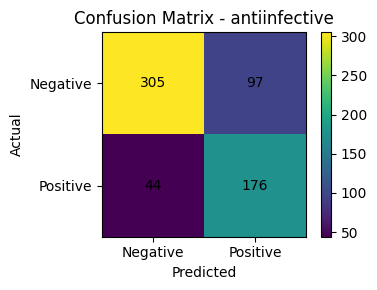

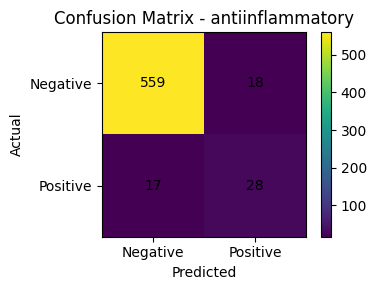

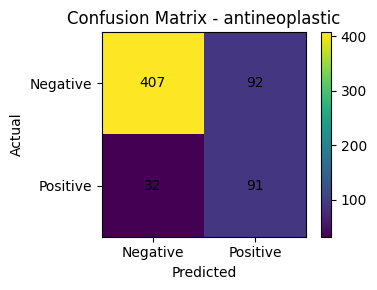

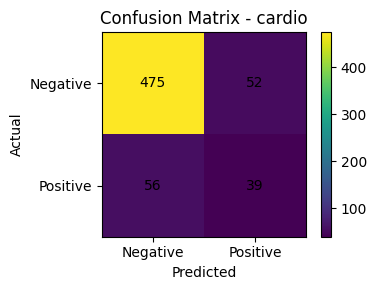

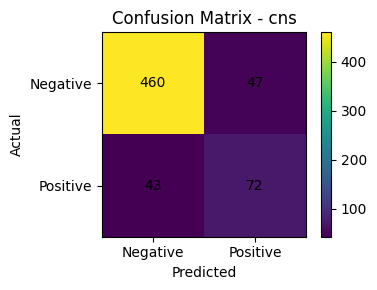

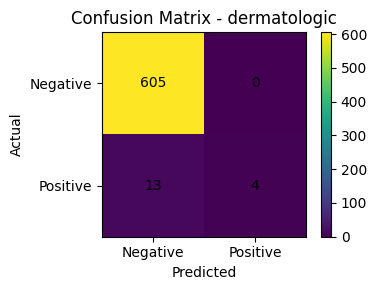

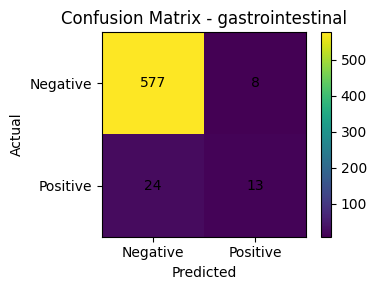

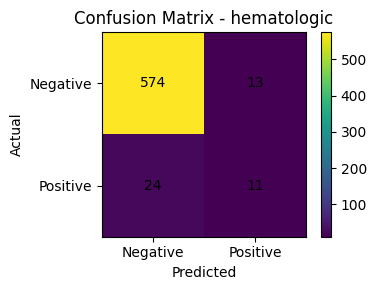

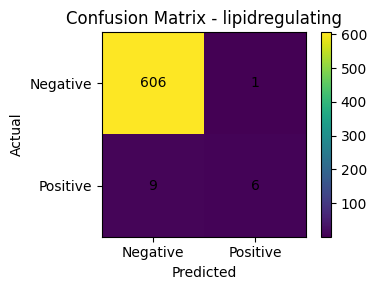

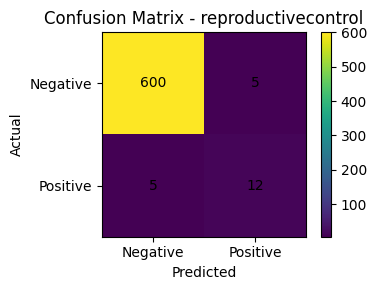

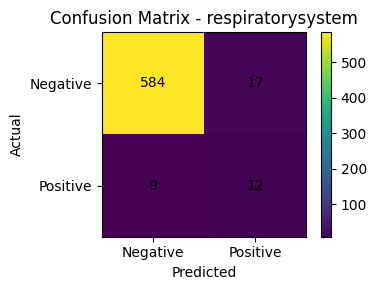

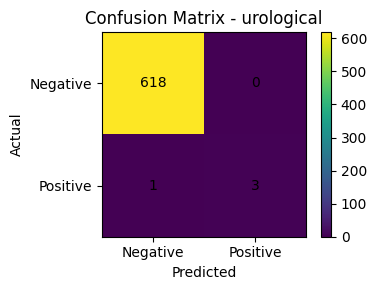

In [ ]:
# ============================================================
# STEP 19: Per-Class Confusion Matrices
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

for i, label_name in enumerate(mlb.classes_):

    cm = confusion_matrix(
        test_labels[:, i],
        test_predictions[:, i]
    )

    plt.figure(figsize=(4, 3))

    plt.imshow(cm)

    plt.title(
        f"Confusion Matrix - {label_name}"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.xticks([0, 1], ["Negative", "Positive"])
    plt.yticks([0, 1], ["Negative", "Positive"])

    for x in range(2):
        for y in range(2):
            plt.text(
                y,
                x,
                cm[x, y],
                ha="center",
                va="center"
            )

    plt.colorbar()
    plt.tight_layout()
    plt.show()

In [ ]:
display(summary)

,Metric,Score
0,Macro Precision,0.653205
1,Macro Recall,0.543910
2,Macro F1,0.562457
3,Micro F1,0.598334
4,Weighted F1,0.589166
5,Macro AUROC,0.884116
6,Micro AUROC,0.911724
7,Macro AUPRC,0.608988
8,Micro AUPRC,0.622424


In [ ]:
threshold_analysis = pd.DataFrame({
    "Label": mlb.classes_,
    "Threshold": best_thresholds,
    "Validation_F1": best_f1
})

display(
    threshold_analysis.sort_values(
        "Validation_F1"
    )
)

,Label,Threshold,Validation_F1
6,gastrointestinal,0.63,0.485437
10,respiratorysystem,0.65,0.530120
3,cardio,0.58,0.538226
2,antineoplastic,0.49,0.549407
7,hematologic,0.68,0.622642
1,antiinflammatory,0.61,0.636364
4,cns,0.58,0.639456
5,dermatologic,0.76,0.681818
0,antiinfective,0.48,0.724221
9,reproductivecontrol,0.63,0.745763


In [ ]:
support_comparison = pd.DataFrame({

    "Label": mlb.classes_,

    "Train_Support":
        train_labels_final.sum(axis=0),

    "Validation_Support":
        val_labels.sum(axis=0),

    "Test_Support":
        test_labels.sum(axis=0)

})

display(support_comparison)

,Label,Train_Support,Validation_Support,Test_Support
0,antiinfective,2111,373,220
1,antiinflammatory,427,75,45
2,antineoplastic,1187,209,123
3,cardio,912,161,95
4,cns,1104,195,115
5,dermatologic,163,29,17
6,gastrointestinal,354,62,37
7,hematologic,334,59,35
8,lipidregulating,147,26,15
9,reproductivecontrol,162,29,17


In [ ]:
# ============================================================
# Validation vs Test F1
# ============================================================

val_predictions = np.zeros_like(
    val_probabilities,
    dtype=int
)

test_predictions = np.zeros_like(
    test_probabilities,
    dtype=int
)

for i in range(NUM_LABELS):

    val_predictions[:, i] = (
        val_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)

    test_predictions[:, i] = (
        test_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)


val_f1 = f1_score(
    val_labels,
    val_predictions,
    average=None,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)


comparison = pd.DataFrame({

    "Label": mlb.classes_,

    "Threshold": best_thresholds,

    "Validation_F1": val_f1,

    "Test_F1": test_f1,

    "Drop": val_f1 - test_f1

})

display(comparison)

,Label,Threshold,Validation_F1,Test_F1,Drop
0,antiinfective,0.48,0.724221,0.713996,0.010225
1,antiinflammatory,0.61,0.636364,0.615385,0.020979
2,antineoplastic,0.49,0.549407,0.594771,-0.045364
3,cardio,0.58,0.538226,0.419355,0.118871
4,cns,0.58,0.639456,0.615385,0.024071
5,dermatologic,0.76,0.681818,0.380952,0.300866
6,gastrointestinal,0.63,0.485437,0.448276,0.037161
7,hematologic,0.68,0.622642,0.372881,0.249760
8,lipidregulating,0.70,0.808511,0.545455,0.263056
9,reproductivecontrol,0.63,0.745763,0.705882,0.039880


In [ ]:
# ============================================================
# Validation vs Test F1
# ============================================================

val_predictions = np.zeros_like(
    val_probabilities,
    dtype=int
)

test_predictions = np.zeros_like(
    test_probabilities,
    dtype=int
)

for i in range(NUM_LABELS):

    val_predictions[:, i] = (
        val_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)

    test_predictions[:, i] = (
        test_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)


val_f1 = f1_score(
    val_labels,
    val_predictions,
    average=None,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)


comparison = pd.DataFrame({

    "Label": mlb.classes_,

    "Threshold": best_thresholds,

    "Validation_F1": val_f1,

    "Test_F1": test_f1,

    "Drop": val_f1 - test_f1

})

display(comparison)

,Label,Threshold,Validation_F1,Test_F1,Drop
0,antiinfective,0.48,0.724221,0.713996,0.010225
1,antiinflammatory,0.61,0.636364,0.615385,0.020979
2,antineoplastic,0.49,0.549407,0.594771,-0.045364
3,cardio,0.58,0.538226,0.419355,0.118871
4,cns,0.58,0.639456,0.615385,0.024071
5,dermatologic,0.76,0.681818,0.380952,0.300866
6,gastrointestinal,0.63,0.485437,0.448276,0.037161
7,hematologic,0.68,0.622642,0.372881,0.249760
8,lipidregulating,0.70,0.808511,0.545455,0.263056
9,reproductivecontrol,0.63,0.745763,0.705882,0.039880


In [ ]:
# ============================================================
# GLOBAL MACRO-F1 THRESHOLD OPTIMIZATION
# ============================================================

from sklearn.metrics import f1_score
import numpy as np


def calculate_macro_f1(
    y_true,
    probabilities,
    thresholds
):

    predictions = (
        probabilities >= thresholds
    ).astype(int)

    return f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )


macro_thresholds = np.full(
    NUM_LABELS,
    0.50
)

print(
    "Initial Macro-F1:",
    calculate_macro_f1(
        val_labels,
        val_probabilities,
        macro_thresholds
    )
)


# Coordinate descent
for iteration in range(3):

    for label in range(NUM_LABELS):

        best_score = -1

        best_threshold = (
            macro_thresholds[label]
        )

        for threshold in np.arange(
            0.10,
            0.91,
            0.02
        ):

            candidate = (
                macro_thresholds.copy()
            )

            candidate[label] = threshold

            score = calculate_macro_f1(
                val_labels,
                val_probabilities,
                candidate
            )

            if score > best_score:

                best_score = score

                best_threshold = threshold

        macro_thresholds[label] = (
            best_threshold
        )

    print(
        f"Iteration {iteration + 1}: "
        f"Macro-F1 = "
        f"{calculate_macro_f1(
            val_labels,
            val_probabilities,
            macro_thresholds
        ):.4f}"
    )


print("\nFinal thresholds:")

for i, label in enumerate(mlb.classes_):

    print(
        f"{label:25s} "
        f"{macro_thresholds[i]:.2f}"
    )

Initial Macro-F1: 0.49446886915855837
Iteration 1: Macro-F1 = 0.6442
Iteration 2: Macro-F1 = 0.6442
Iteration 3: Macro-F1 = 0.6442

Final thresholds:
antiinfective             0.48
antiinflammatory          0.62
antineoplastic            0.50
cardio                    0.58
cns                       0.58
dermatologic              0.76
gastrointestinal          0.64
hematologic               0.68
lipidregulating           0.70
reproductivecontrol       0.66
respiratorysystem         0.66
urological                0.62


In [ ]:
import os
import ast
import random
import numpy as np
import pandas as pd
import warnings

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer

from rdkit import Chem
from rdkit import RDLogger

from transformers import (
    AutoTokenizer,
    AutoModel
)

from torch_geometric.data import Data as GraphData
from torch_geometric.nn import (
    GATv2Conv,
    global_mean_pool
)

# Suppress RDKit warnings
RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings("ignore", message="not removing hydrogen atom without neighbors")


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
# ============================================================
# CELL 2 — LOAD DATASET
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

PATH = "/content/drive/MyDrive/dataset/all_chem_df.csv"

df = pd.read_csv(PATH)

print("Dataset shape:", df.shape)

display(df.head())

print("\nColumns:")
print(df.columns.tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (8336, 4)


,image_name,tags,smiles,Col3
0,pics/0,dermatologic,CC(=O)NC1C(O)OC(CO)C(O)C1O,['dermatologic']
1,pics/1,antiinfective,CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...,['antiinfective']
2,pics/2,antiinfective,CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...,['antiinfective']
3,pics/3,antineoplastic,COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...,['antineoplastic']
4,pics/4,antiinfective respiratorysystem,CC(=O)N[C@@H](CS)C(=O)[O-],"['antiinfective', 'respiratorysystem']"



Columns:
['image_name', 'tags', 'smiles', 'Col3']


In [ ]:
# ============================================================
# CELL 3 — LABEL PROCESSING
# ============================================================

def parse_labels(x):

    if pd.isna(x):
        return []

    if isinstance(x, list):
        return x

    try:
        value = ast.literal_eval(x)

        if isinstance(value, list):
            return value

        return [str(value)]

    except:
        return [str(x)]


df["label_list"] = df["Col3"].apply(parse_labels)

# Remove invalid SMILES
df = df[
    df["smiles"].notna()
].copy()

df["smiles"] = df["smiles"].astype(str)

# Validate SMILES
def valid_smiles(s):

    try:
        return Chem.MolFromSmiles(s) is not None
    except:
        return False


df["valid"] = df["smiles"].apply(valid_smiles)

df = df[
    df["valid"]
].copy()

print("Valid molecules:", len(df))

mlb = MultiLabelBinarizer()

labels = mlb.fit_transform(
    df["label_list"]
)

NUM_LABELS = labels.shape[1]

print("Number of classes:", NUM_LABELS)
print("Classes:", mlb.classes_)

df = df.reset_index(drop=True)

[07:58:18] Conflicting single bond directions around double bond at index 1.
[07:58:18]   BondStereo set to STEREONONE and single bond directions set to NONE.
[07:58:18] WARNING: not removing hydrogen atom without neighbors
[07:58:18] WARNING: not removing hydrogen atom without neighbors
[07:58:18] WARNING: not removing hydrogen atom without neighbors
[07:58:18] WARNING: not removing hydrogen atom without neighbors
[07:58:18] WARNING: not removing hydrogen atom without neighbors
[07:58:18] WARNING: not removing hydrogen atom without neighbors
[07:58:18] Conflicting single bond directions around double bond at index 1.
[07:58:18]   BondStereo set to STEREONONE and single bond directions set to NONE.
[07:58:18] WARNING: not removing hydrogen atom without neighbors
[07:58:18] WARNING: not removing hydrogen atom without neighbors
[07:58:18] Conflicting single bond directions around double bond at index 1.
[07:58:18]   BondStereo set to STEREONONE and single bond directions set to NONE.
[07

Valid molecules: 8336
Number of classes: 12
Classes: ['antiinfective' 'antiinflammatory' 'antineoplastic' 'cardio' 'cns'
 'dermatologic' 'gastrointestinal' 'hematologic' 'lipidregulating'
 'reproductivecontrol' 'respiratorysystem' 'urological']


[07:58:20] WARNING: not removing hydrogen atom without neighbors
[07:58:20] WARNING: not removing hydrogen atom without neighbors
[07:58:20] WARNING: not removing hydrogen atom without neighbors
[07:58:20] WARNING: not removing hydrogen atom without neighbors
[07:58:20] WARNING: not removing hydrogen atom without neighbors


In [ ]:
# ============================================================
# CELL 4 — MOLECULAR GRAPH CONSTRUCTION
# ============================================================

def atom_features(atom):

    return [
        atom.GetAtomicNum(),
        atom.GetDegree(),
        atom.GetFormalCharge(),
        int(atom.GetIsAromatic()),
        int(atom.GetHybridization()),
        atom.GetTotalNumHs(),
    ]


def bond_features(bond):

    return [
        float(bond.GetBondTypeAsDouble()),
        int(bond.GetIsAromatic()),
        int(bond.GetIsConjugated()),
    ]


def smiles_to_graph(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    x = []

    for atom in mol.GetAtoms():
        x.append(
            atom_features(atom)
        )

    x = torch.tensor(
        x,
        dtype=torch.float
    )

    edge_index = []
    edge_attr = []

    for bond in mol.GetBonds():

        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        edge_index.append([i, j])
        edge_index.append([j, i])

        features = bond_features(bond)

        edge_attr.append(features)
        edge_attr.append(features)

    if len(edge_index) == 0:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

        edge_attr = torch.empty(
            (0, 3),
            dtype=torch.float

        )

    else:

        edge_index = torch.tensor(
            edge_index,
            dtype=torch.long
        ).t().contiguous()

        edge_attr = torch.tensor(
            edge_attr,
            dtype=torch.float
        )

    return GraphData(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr
    )

In [ ]:
# ============================================================
# CELL 5 — CHEMBERTA + GAT HYBRID MODEL
# ============================================================

class ChemGraphMT(nn.Module):

    def __init__(
        self,
        num_labels,
        chemberta_name="DeepChem/ChemBERTa-77M-MLM",
        hidden_dim=256,
        dropout=0.2
    ):

        super().__init__()

        # ----------------------------------------------------
        # ChemBERTa
        # ----------------------------------------------------

        self.chemberta = AutoModel.from_pretrained(
            chemberta_name
        )

        bert_dim = (
            self.chemberta.config.hidden_size
        )

        # ----------------------------------------------------
        # GAT
        # ----------------------------------------------------

        self.gat1 = GATv2Conv(
            in_channels=6,
            out_channels=128,
            heads=2,
            dropout=dropout
        )

        self.gat2 = GATv2Conv(
            in_channels=256,
            out_channels=128,
            heads=1,
            dropout=dropout
        )

        self.graph_projection = nn.Sequential(

            nn.Linear(128, hidden_dim),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout)
        )

        # ----------------------------------------------------
        # SMILES projection
        # ----------------------------------------------------

        self.smiles_projection = nn.Sequential(

            nn.Linear(
                bert_dim,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout)
        )

        # ----------------------------------------------------
        # Fusion
        # ----------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                hidden_dim * 2,
                512
            ),

            nn.LayerNorm(512),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                512,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU()
        )

        # ----------------------------------------------------
        # Drug-class prediction
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_dim,
                128
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                128,
                num_labels
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        graph
    ):

        # ====================================================
        # SMILES REPRESENTATION
        # ====================================================

        bert_output = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        smiles_embedding = (
            bert_output.last_hidden_state[:, 0, :]
        )

        smiles_embedding = (
            self.smiles_projection(
                smiles_embedding
            )
        )

        # ====================================================
        # GRAPH REPRESENTATION
        # ====================================================

        x = graph.x

        x = self.gat1(
            x,
            graph.edge_index
        )

        x = F.elu(x)

        x = self.gat2(
            x,
            graph.edge_index
        )

        x = F.elu(x)

        x = global_mean_pool(
            x,
            graph.batch
        )

        graph_embedding = (
            self.graph_projection(x)
        )

        # ====================================================
        # MULTIMODAL FUSION
        # ====================================================

        combined = torch.cat(
            [
                smiles_embedding,
                graph_embedding
            ],
            dim=1
        )

        fused = self.fusion(
            combined
        )

        # ====================================================
        # CLASSIFICATION
        # ====================================================

        logits = self.classifier(
            fused
        )

        return logits

In [ ]:
print("Dataset:", df.shape)
print("Classes:", mlb.classes_)
print("Number of classes:", NUM_LABELS)

class_counts = labels.sum(axis=0)

for i, cls in enumerate(mlb.classes_):
    print(f"{i:2d} {cls:25s} {class_counts[i]}")

Dataset: (8336, 6)
Classes: ['antiinfective' 'antiinflammatory' 'antineoplastic' 'cardio' 'cns'
 'dermatologic' 'gastrointestinal' 'hematologic' 'lipidregulating'
 'reproductivecontrol' 'respiratorysystem' 'urological']
Number of classes: 12
 0 antiinfective             2923
 1 antiinflammatory          591
 2 antineoplastic            1642
 3 cardio                    1262
 4 cns                       1528
 5 dermatologic              226
 6 gastrointestinal          490
 7 hematologic               462
 8 lipidregulating           203
 9 reproductivecontrol       225
10 respiratorysystem         281
11 urological                48


In [ ]:
!pip install -q iterative-stratification

In [ ]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = df["smiles"].values
Y = labels

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    msss.split(X, Y)
)

train_df = df.iloc[train_idx].reset_index(drop=True)
temp_df = df.iloc[temp_idx].reset_index(drop=True)

train_labels = labels[train_idx]
temp_labels = labels[temp_idx]

In [ ]:
msss2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    msss2.split(
        temp_df["smiles"].values,
        temp_labels
    )
)

val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

val_labels = temp_labels[val_idx]
test_labels = temp_labels[test_idx]

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (6673, 6)
Validation: (832, 6)
Test: (831, 6)


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "DeepChem/ChemBERTa-77M-MLM"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

MAX_LENGTH = 128

config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.96k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.26k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/420 [00:00<?, ?B/s]

In [ ]:
example_smiles = train_df.iloc[0]["smiles"]

graph = smiles_to_graph(
    example_smiles
)

print(graph)
print("Nodes:", graph.x.shape)
print("Edges:", graph.edge_index.shape)

Data(x=[15, 6], edge_index=[2, 30], edge_attr=[30, 3])
Nodes: torch.Size([15, 6])
Edges: torch.Size([2, 30])


In [ ]:
class MolecularDataset(Dataset):

    def __init__(
        self,
        dataframe,
        labels,
        tokenizer,
        max_length=128
    ):

        self.df = dataframe.reset_index(drop=True)

        self.labels = torch.tensor(
            labels,
            dtype=torch.float
        )

        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        smiles = self.df.iloc[idx]["smiles"]

        # -------------------------------
        # SMILES TOKENIZATION
        # -------------------------------

        encoded = self.tokenizer(
            smiles,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        input_ids = encoded["input_ids"].squeeze(0)

        attention_mask = encoded[
            "attention_mask"
        ].squeeze(0)

        # -------------------------------
        # MOLECULAR GRAPH
        # -------------------------------

        graph = smiles_to_graph(smiles)

        # -------------------------------
        # LABEL
        # -------------------------------

        label = self.labels[idx]

        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "graph": graph,
            "labels": label
        }

In [ ]:
train_dataset = MolecularDataset(
    train_df,
    train_labels,
    tokenizer,
    MAX_LENGTH
)

val_dataset = MolecularDataset(
    val_df,
    val_labels,
    tokenizer,
    MAX_LENGTH
)

test_dataset = MolecularDataset(
    test_df,
    test_labels,
    tokenizer,
    MAX_LENGTH
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 6673
Validation: 832
Test: 831


In [ ]:
from torch_geometric.data import Batch

def collate_fn(batch):

    input_ids = torch.stack([
        item["input_ids"]
        for item in batch
    ])

    attention_mask = torch.stack([
        item["attention_mask"]
        for item in batch
    ])

    labels = torch.stack([
        item["labels"]
        for item in batch
    ])

    graphs = Batch.from_data_list([
        item["graph"]
        for item in batch
    ])

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "graph": graphs,
        "labels": labels
    }

In [ ]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

In [ ]:
batch = next(iter(train_loader))

print(
    "Input IDs:",
    batch["input_ids"].shape
)

print(
    "Attention mask:",
    batch["attention_mask"].shape
)

print(
    "Labels:",
    batch["labels"].shape
)

print(
    "Graph nodes:",
    batch["graph"].x.shape
)

print(
    "Graph edges:",
    batch["graph"].edge_index.shape
)

print(
    "Graph batch:",
    batch["graph"].batch.shape
)

Input IDs: torch.Size([16, 128])
Attention mask: torch.Size([16, 128])
Labels: torch.Size([16, 12])
Graph nodes: torch.Size([454, 6])
Graph edges: torch.Size([2, 976])
Graph batch: torch.Size([454])


In [ ]:
model = ChemGraphMT(
    num_labels=NUM_LABELS,
    chemberta_name=MODEL_NAME,
    hidden_dim=256,
    dropout=0.20
)

model = model.to(device)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 13.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: DeepChem/ChemBERTa-77M-MLM
Key                       | Status     | 
--------------------------+------------+-
lm_head.decoder.bias      | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 4060156


In [ ]:
for param in model.chemberta.parameters():
    param.requires_grad = False

In [ ]:
for param in model.chemberta.parameters():
    param.requires_grad = True

In [ ]:
counts = train_labels.sum(axis=0)

beta = 0.999

effective_weights = (
    (1 - beta) /
    (1 - np.power(beta, counts))
)

effective_weights = (
    effective_weights /
    effective_weights.mean()
)

effective_weights = np.clip(
    effective_weights,
    0.5,
    10.0
)

class_weights = torch.tensor(
    effective_weights,
    dtype=torch.float32
).to(device)

print(
    pd.DataFrame({
        "Class": mlb.classes_,
        "Count": counts,
        "Weight": effective_weights
    })
)

                  Class  Count    Weight
0         antiinfective   2338  0.500000
1      antiinflammatory    473  0.500000
2        antineoplastic   1313  0.500000
3                cardio   1009  0.500000
4                   cns   1222  0.500000
5          dermatologic    181  1.114781
6      gastrointestinal    392  0.569163
7           hematologic    370  0.596821
8       lipidregulating    162  1.234080
9   reproductivecontrol    180  1.120431
10    respiratorysystem    225  0.916055
11           urological     38  4.949761


In [ ]:
class FocalBCELoss(nn.Module):

    def __init__(
        self,
        pos_weight=None,
        gamma=2.0
    ):

        super().__init__()

        self.pos_weight = pos_weight
        self.gamma = gamma

    def forward(
        self,
        logits,
        targets
    ):

        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets,
            pos_weight=self.pos_weight,
            reduction="none"
        )

        probabilities = torch.sigmoid(logits)

        pt = (
            targets * probabilities
            +
            (1 - targets) * (1 - probabilities)
        )

        focal_weight = (
            1 - pt
        ).pow(self.gamma)

        loss = focal_weight * bce

        return loss.mean()

In [ ]:
criterion = FocalBCELoss(
    pos_weight=class_weights,
    gamma=2.0
)

In [ ]:
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.chemberta.parameters(),
            "lr": 1e-5
        },
        {
            "params": [
                p for name, p
                in model.named_parameters()
                if not name.startswith("chemberta.")
            ],
            "lr": 2e-4
        }
    ],
    weight_decay=1e-4
)

In [ ]:
torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0
)

tensor(0.)

In [ ]:
# ============================================================
# CELL 1 — EVALUATION IMPORTS
# ============================================================

import os
import copy
import numpy as np
import pandas as pd

import torch
import torch.nn.functional as F

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

MODEL_SAVE_PATH = "/content/drive/MyDrive/dataset/best_chemgraph_gatv2.pt"

print("Evaluation setup ready")

Evaluation setup ready


In [ ]:
# ============================================================
# CELL 2 — TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device
):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for batch in loader:

        input_ids = batch["input_ids"].to(
            device,
            non_blocking=True
        )

        attention_mask = batch["attention_mask"].to(
            device,
            non_blocking=True
        )

        labels = batch["labels"].to(
            device,
            non_blocking=True
        )

        graph = batch["graph"].to(device)

        # ----------------------------------------------------
        # Clear gradients
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            graph=graph
        )

        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss = criterion(
            logits,
            labels
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        loss.backward()

        # ----------------------------------------------------
        # Gradient clipping
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # ----------------------------------------------------
        # Update parameters
        # ----------------------------------------------------

        optimizer.step()

        batch_size = labels.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

    epoch_loss = (
        total_loss /
        max(total_samples, 1)
    )

    return epoch_loss

In [ ]:
# ============================================================
# CELL 3 — VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_model(
    model,
    loader,
    device
):

    model.eval()

    all_probabilities = []
    all_labels = []

    total_loss = 0.0
    total_samples = 0

    for batch in loader:

        input_ids = batch["input_ids"].to(
            device,
            non_blocking=True
        )

        attention_mask = batch["attention_mask"].to(
            device,
            non_blocking=True
        )

        labels = batch["labels"].to(
            device,
            non_blocking=True
        )

        graph = batch["graph"].to(device)

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            graph=graph
        )

        # ----------------------------------------------------
        # BCE for validation loss
        # ----------------------------------------------------

        loss = F.binary_cross_entropy_with_logits(
            logits,
            labels
        )

        batch_size = labels.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

        # ----------------------------------------------------
        # Probabilities
        # ----------------------------------------------------

        probabilities = torch.sigmoid(
            logits
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

        all_labels.append(
            labels.cpu().numpy()
        )

    probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    labels = np.concatenate(
        all_labels,
        axis=0
    )

    avg_loss = (
        total_loss /
        max(total_samples, 1)
    )

    # --------------------------------------------------------
    # Default threshold only for monitoring
    # --------------------------------------------------------

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    return {
        "loss": avg_loss,
        "macro_f1": macro_f1,
        "micro_f1": micro_f1,
        "probabilities": probabilities,
        "labels": labels
    }

In [ ]:
# ============================================================
# CELL 4 — TRAINING
# ============================================================

NUM_EPOCHS = 50

best_macro_f1 = -np.inf
best_epoch = 0

history = []

for epoch in range(NUM_EPOCHS):

    print("\n" + "=" * 70)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_loss = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    val_results = evaluate_model(
        model=model,
        loader=val_loader,
        device=device
    )

    val_loss = val_results["loss"]
    val_macro_f1 = val_results["macro_f1"]
    val_micro_f1 = val_results["micro_f1"]

    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    history.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation Macro F1": val_macro_f1,
        "Validation Micro F1": val_micro_f1
    })

    print(
        f"Train Loss       : {train_loss:.6f}"
    )

    print(
        f"Validation Loss  : {val_loss:.6f}"
    )

    print(
        f"Validation Macro F1 : {val_macro_f1:.6f}"
    )

    print(
        f"Validation Micro F1 : {val_micro_f1:.6f}"
    )

    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_macro_f1 > best_macro_f1:

        best_macro_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_macro_f1": best_macro_f1
            },
            MODEL_SAVE_PATH
        )

        print(
            f"✓ Best model saved "
            f"(Macro-F1={best_macro_f1:.6f})"
        )

print("\nTraining completed.")

print(
    f"Best Epoch: {best_epoch}"
)

print(
    f"Best Validation Macro-F1: "
    f"{best_macro_f1:.6f}"
)


Epoch 1/50


[08:10:34] Conflicting single bond directions around double bond at index 1.
[08:10:34]   BondStereo set to STEREONONE and single bond directions set to NONE.
[08:10:34] WARNING: not removing hydrogen atom without neighbors
[08:10:34] WARNING: not removing hydrogen atom without neighbors
[08:10:34] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighbors
[08:10:35] WARNING: not removing hydrogen atom without neighb

Train Loss       : 0.057900
Validation Loss  : 0.338239
Validation Macro F1 : 0.077596
Validation Micro F1 : 0.252757
✓ Best model saved (Macro-F1=0.077596)

Epoch 2/50


[08:10:46] WARNING: not removing hydrogen atom without neighbors
[08:10:46] WARNING: not removing hydrogen atom without neighbors
[08:10:46] WARNING: not removing hydrogen atom without neighbors
[08:10:47] Conflicting single bond directions around double bond at index 1.
[08:10:47]   BondStereo set to STEREONONE and single bond directions set to NONE.
[08:10:47] WARNING: not removing hydrogen atom without neighbors
[08:10:47] WARNING: not removing hydrogen atom without neighbors
[08:10:47] WARNING: not removing hydrogen atom without neighbors
[08:10:48] WARNING: not removing hydrogen atom without neighbors
[08:10:48] WARNING: not removing hydrogen atom without neighbors
[08:10:48] WARNING: not removing hydrogen atom without neighbors
[08:10:48] WARNING: not removing hydrogen atom without neighbors
[08:10:48] WARNING: not removing hydrogen atom without neighbors
[08:10:48] WARNING: not removing hydrogen atom without neighbors
[08:10:49] WARNING: not removing hydrogen atom without neighb

Train Loss       : 0.049054
Validation Loss  : 0.317968
Validation Macro F1 : 0.084397
Validation Micro F1 : 0.268631
✓ Best model saved (Macro-F1=0.084397)

Epoch 3/50


...

Train Loss       : 0.013873
Validation Loss  : 0.130564
Validation Macro F1 : 0.746727
Validation Micro F1 : 0.776185

Epoch 49/50


[08:20:31] WARNING: not removing hydrogen atom without neighbors
[08:20:31] WARNING: not removing hydrogen atom without neighbors
[08:20:31] WARNING: not removing hydrogen atom without neighbors
[08:20:31] WARNING: not removing hydrogen atom without neighbors
[08:20:31] WARNING: not removing hydrogen atom without neighbors
[08:20:32] WARNING: not removing hydrogen atom without neighbors
[08:20:32] WARNING: not removing hydrogen atom without neighbors
[08:20:32] WARNING: not removing hydrogen atom without neighbors
[08:20:32] WARNING: not removing hydrogen atom without neighbors
[08:20:32] WARNING: not removing hydrogen atom without neighbors
[08:20:32] WARNING: not removing hydrogen atom without neighbors
[08:20:32] WARNING: not removing hydrogen atom without neighbors
[08:20:33] WARNING: not removing hydrogen atom without neighbors
[08:20:33] WARNING: not removing hydrogen atom without neighbors
[08:20:33] WARNING: not removing hydrogen atom without neighbors
[08:20:33] WARNING: not r

Train Loss       : 0.013561
Validation Loss  : 0.132711
Validation Macro F1 : 0.731588
Validation Micro F1 : 0.779605

Epoch 50/50


[08:20:43] WARNING: not removing hydrogen atom without neighbors
[08:20:44] WARNING: not removing hydrogen atom without neighbors
[08:20:44] WARNING: not removing hydrogen atom without neighbors
[08:20:44] WARNING: not removing hydrogen atom without neighbors
[08:20:44] WARNING: not removing hydrogen atom without neighbors
[08:20:44] WARNING: not removing hydrogen atom without neighbors
[08:20:44] WARNING: not removing hydrogen atom without neighbors
[08:20:44] Conflicting single bond directions around double bond at index 1.
[08:20:44]   BondStereo set to STEREONONE and single bond directions set to NONE.
[08:20:45] WARNING: not removing hydrogen atom without neighbors
[08:20:45] WARNING: not removing hydrogen atom without neighbors
[08:20:45] WARNING: not removing hydrogen atom without neighbors
[08:20:46] WARNING: not removing hydrogen atom without neighbors
[08:20:46] WARNING: not removing hydrogen atom without neighbors
[08:20:46] WARNING: not removing hydrogen atom without neighb

Train Loss       : 0.013700
Validation Loss  : 0.133389
Validation Macro F1 : 0.737264
Validation Micro F1 : 0.774904

Training completed.
Best Epoch: 47
Best Validation Macro-F1: 0.750833


In [ ]:
# ============================================================
# CELL 5 — TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

display(history_df)

,Epoch,Train Loss,Validation Loss,Validation Macro F1,Validation Micro F1
0,1,0.057900,0.338239,0.077596,0.252757
1,2,0.049054,0.317968,0.084397,0.268631
2,3,0.044365,0.294852,0.305457,0.415065
3,4,0.041574,0.289964,0.353141,0.426584
4,5,0.038836,0.280717,0.418505,0.485199
5,6,0.036972,0.268260,0.441061,0.521986
6,7,0.035207,0.263945,0.452578,0.524148
7,8,0.034092,0.250947,0.468097,0.526539
8,9,0.032827,0.246979,0.459745,0.559459
9,10,0.031421,0.242371,0.495276,0.575818


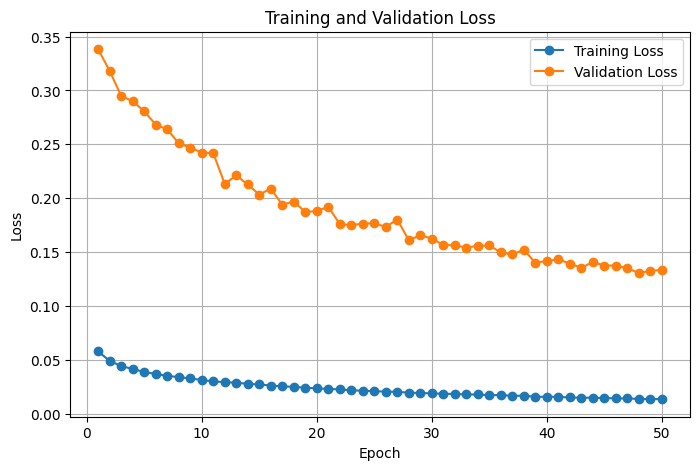

In [ ]:
# ============================================================
# CELL 6 — TRAINING CURVES
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train Loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

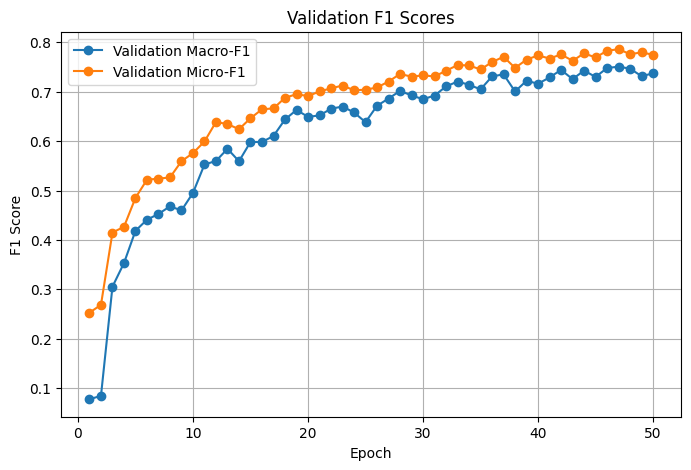

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Micro F1"],
    marker="o",
    label="Validation Micro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Validation F1 Scores")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# CELL 7 — LOAD BEST MODEL
# ============================================================

checkpoint = torch.load(
    MODEL_SAVE_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Macro-F1:",
    checkpoint["best_macro_f1"]
)

Best epoch: 47
Best validation Macro-F1: 0.7508330933068398


In [ ]:
# ============================================================
# CELL 8 — VALIDATION PROBABILITIES
# ============================================================

val_results = evaluate_model(
    model,
    val_loader,
    device
)

val_probabilities = (
    val_results["probabilities"]
)

val_true = (
    val_results["labels"]
)

print(
    "Validation probabilities:",
    val_probabilities.shape
)

print(
    "Validation labels:",
    val_true.shape
)

[08:48:46] WARNING: not removing hydrogen atom without neighbors
[08:48:46] WARNING: not removing hydrogen atom without neighbors
[08:48:46] WARNING: not removing hydrogen atom without neighbors
[08:48:46] WARNING: not removing hydrogen atom without neighbors


Validation probabilities: (832, 12)
Validation labels: (832, 12)


In [ ]:
# ============================================================
# CELL 9 — CLASS-WISE THRESHOLD OPTIMIZATION
# ============================================================

def optimize_class_thresholds(
    y_true,
    probabilities,
    start=0.10,
    end=0.90,
    step=0.01
):

    thresholds = np.arange(
        start,
        end + step,
        step
    )

    best_thresholds = []
    best_scores = []

    num_classes = y_true.shape[1]

    for c in range(num_classes):

        best_f1 = -1
        best_threshold = 0.5

        for threshold in thresholds:

            pred = (
                probabilities[:, c]
                >= threshold
            ).astype(int)

            score = f1_score(
                y_true[:, c],
                pred,
                zero_division=0
            )

            if score > best_f1:

                best_f1 = score
                best_threshold = threshold

        best_thresholds.append(
            best_threshold
        )

        best_scores.append(
            best_f1
        )

    return (
        np.array(best_thresholds),
        np.array(best_scores)
    )

In [ ]:
best_thresholds, validation_class_f1 = (
    optimize_class_thresholds(
        val_true,
        val_probabilities
    )
)

In [ ]:
# ============================================================
# CELL 10 — THRESHOLD TABLE
# ============================================================

threshold_table = pd.DataFrame({

    "Label_ID": np.arange(NUM_LABELS),

    "Label": mlb.classes_,

    "Support": val_true.sum(axis=0),

    "Threshold": best_thresholds,

    "Validation_F1": validation_class_f1
})

display(
    threshold_table.sort_values(
        "Validation_F1"
    )
)

,Label_ID,Label,Support,Threshold,Validation_F1
10,10,respiratorysystem,28.0,0.48,0.666667
9,9,reproductivecontrol,22.0,0.73,0.684211
6,6,gastrointestinal,49.0,0.47,0.739130
3,3,cardio,126.0,0.47,0.744939
7,7,hematologic,46.0,0.40,0.765432
5,5,dermatologic,22.0,0.61,0.769231
2,2,antineoplastic,164.0,0.35,0.802432
4,4,cns,153.0,0.40,0.811502
1,1,antiinflammatory,59.0,0.51,0.814815
8,8,lipidregulating,20.0,0.63,0.833333


In [ ]:
# ============================================================
# CELL 11 — VALIDATION OPTIMIZED PREDICTIONS
# ============================================================

val_optimized_predictions = np.zeros_like(
    val_probabilities,
    dtype=int
)

for c in range(NUM_LABELS):

    val_optimized_predictions[:, c] = (
        val_probabilities[:, c]
        >= best_thresholds[c]
    ).astype(int)

In [ ]:
optimized_val_macro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="macro",
    zero_division=0
)

optimized_val_micro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="micro",
    zero_division=0
)

print(
    f"Optimized Validation Macro-F1: "
    f"{optimized_val_macro_f1:.6f}"
)

print(
    f"Optimized Validation Micro-F1: "
    f"{optimized_val_micro_f1:.6f}"
)

Optimized Validation Macro-F1: 0.783853
Optimized Validation Micro-F1: 0.805277


In [ ]:
optimized_val_macro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="macro",
    zero_division=0
)

optimized_val_micro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="micro",
    zero_division=0
)

print(
    f"Optimized Validation Macro-F1: "
    f"{optimized_val_macro_f1:.6f}"
)

print(
    f"Optimized Validation Micro-F1: "
    f"{optimized_val_micro_f1:.6f}"
)

Optimized Validation Macro-F1: 0.783853
Optimized Validation Micro-F1: 0.805277


In [ ]:
optimized_val_macro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="macro",
    zero_division=0
)

optimized_val_micro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="micro",
    zero_division=0
)

print(
    f"Optimized Validation Macro-F1: "
    f"{optimized_val_macro_f1:.6f}"
)

print(
    f"Optimized Validation Micro-F1: "
    f"{optimized_val_micro_f1:.6f}"
)

Optimized Validation Macro-F1: 0.783853
Optimized Validation Micro-F1: 0.805277


In [ ]:
# ============================================================
# CELL 12 — TEST PREDICTIONS
# ============================================================

test_results = evaluate_model(
    model,
    test_loader,
    device
)

test_probabilities = (
    test_results["probabilities"]
)

test_true = (
    test_results["labels"]
)

print(
    "Test probabilities:",
    test_probabilities.shape
)

print(
    "Test labels:",
    test_true.shape
)

[08:59:42] WARNING: not removing hydrogen atom without neighbors
[08:59:42] WARNING: not removing hydrogen atom without neighbors
[08:59:42] WARNING: not removing hydrogen atom without neighbors
[08:59:42] WARNING: not removing hydrogen atom without neighbors
[08:59:42] WARNING: not removing hydrogen atom without neighbors
[08:59:42] WARNING: not removing hydrogen atom without neighbors
[08:59:42] Conflicting single bond directions around double bond at index 1.
[08:59:42]   BondStereo set to STEREONONE and single bond directions set to NONE.
[08:59:42] WARNING: not removing hydrogen atom without neighbors


Test probabilities: (831, 12)
Test labels: (831, 12)


In [ ]:
# ============================================================
# CELL 13 — FINAL TEST PREDICTIONS
# ============================================================

test_predictions = np.zeros_like(
    test_probabilities,
    dtype=int
)

for c in range(NUM_LABELS):

    test_predictions[:, c] = (
        test_probabilities[:, c]
        >= best_thresholds[c]
    ).astype(int)

In [ ]:
# ============================================================
# CELL 14 — FINAL F1 METRICS
# ============================================================

final_macro_precision = precision_score(
    test_true,
    test_predictions,
    average="macro",
    zero_division=0
)

final_macro_recall = recall_score(
    test_true,
    test_predictions,
    average="macro",
    zero_division=0
)

final_macro_f1 = f1_score(
    test_true,
    test_predictions,
    average="macro",
    zero_division=0
)

final_micro_f1 = f1_score(
    test_true,
    test_predictions,
    average="micro",
    zero_division=0
)

final_weighted_f1 = f1_score(
    test_true,
    test_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 65)
print("FINAL TEST CLASSIFICATION METRICS")
print("=" * 65)

print(
    f"Macro Precision : {final_macro_precision:.4f}"
)

print(
    f"Macro Recall    : {final_macro_recall:.4f}"
)

print(
    f"Macro F1        : {final_macro_f1:.4f}"
)

print(
    f"Micro F1        : {final_micro_f1:.4f}"
)

print(
    f"Weighted F1     : {final_weighted_f1:.4f}"
)

FINAL TEST CLASSIFICATION METRICS
Macro Precision : 0.7915
Macro Recall    : 0.6651
Macro F1        : 0.7146
Micro F1        : 0.7760
Weighted F1     : 0.7743


In [ ]:
# ============================================================
# CELL 15 — AUROC AND AUPRC
# ============================================================

macro_auroc = roc_auc_score(
    test_true,
    test_probabilities,
    average="macro"
)

micro_auroc = roc_auc_score(
    test_true,
    test_probabilities,
    average="micro"
)

macro_auprc = average_precision_score(
    test_true,
    test_probabilities,
    average="macro"
)

micro_auprc = average_precision_score(
    test_true,
    test_probabilities,
    average="micro"
)

print("=" * 65)
print("FINAL TEST RANKING METRICS")
print("=" * 65)

print(
    f"Macro AUROC : {macro_auroc:.4f}"
)

print(
    f"Micro AUROC : {micro_auroc:.4f}"
)

print(
    f"Macro AUPRC : {macro_auprc:.4f}"
)

print(
    f"Micro AUPRC : {micro_auprc:.4f}"
)

FINAL TEST RANKING METRICS
Macro AUROC : 0.9384
Micro AUROC : 0.9647
Macro AUPRC : 0.7897
Micro AUPRC : 0.8600


In [ ]:
# ============================================================
# CELL 16 — FINAL METRICS TABLE
# ============================================================

final_metrics = pd.DataFrame({

    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "ChemGraph-GATv2": [

        final_macro_precision,

        final_macro_recall,

        final_macro_f1,

        final_micro_f1,

        final_weighted_f1,

        macro_auroc,

        micro_auroc,

        macro_auprc,

        micro_auprc
    ]
})

display(final_metrics)

,Metric,ChemGraph-GATv2
0,Macro Precision,0.791453
1,Macro Recall,0.665058
2,Macro F1,0.714579
3,Micro F1,0.776025
4,Weighted F1,0.774276
5,Macro AUROC,0.938436
6,Micro AUROC,0.964668
7,Macro AUPRC,0.789712
8,Micro AUPRC,0.859968


In [ ]:
# ============================================================
# CELL 17 — PER-CLASS METRICS
# ============================================================

per_class_precision = precision_score(
    test_true,
    test_predictions,
    average=None,
    zero_division=0
)

per_class_recall = recall_score(
    test_true,
    test_predictions,
    average=None,
    zero_division=0
)

per_class_f1 = f1_score(
    test_true,
    test_predictions,
    average=None,
    zero_division=0
)

per_class_results = pd.DataFrame({

    "Label_ID": np.arange(NUM_LABELS),

    "Label": mlb.classes_,

    "Support": test_true.sum(axis=0),

    "Threshold": best_thresholds,

    "Precision": per_class_precision,

    "Recall": per_class_recall,

    "F1": per_class_f1
})

display(
    per_class_results.sort_values(
        "F1"
    )
)

,Label_ID,Label,Support,Threshold,Precision,Recall,F1
11,11,urological,5.0,0.43,0.500000,0.600000,0.545455
10,10,respiratorysystem,28.0,0.48,0.652174,0.535714,0.588235
5,5,dermatologic,23.0,0.61,0.812500,0.565217,0.666667
3,3,cardio,127.0,0.47,0.782178,0.622047,0.692982
6,6,gastrointestinal,49.0,0.47,0.744186,0.653061,0.695652
7,7,hematologic,46.0,0.40,0.823529,0.608696,0.700000
1,1,antiinflammatory,59.0,0.51,0.875000,0.593220,0.707071
9,9,reproductivecontrol,23.0,0.73,1.000000,0.565217,0.722222
4,4,cns,153.0,0.40,0.684211,0.849673,0.758017
2,2,antineoplastic,165.0,0.35,0.825000,0.800000,0.812308


In [ ]:
# ============================================================
# CELL 18 — BASELINE VS PROPOSED MODEL
# ============================================================

comparison = pd.DataFrame({

    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "ChemBERTa": [
        0.648804,
        0.537849,
        0.558966,
        0.595284,
        0.585794,
        0.884098,
        0.908873,
        0.610430,
        0.611315
    ],

    "ChemBERTa + GATv2": [
        final_macro_precision,
        final_macro_recall,
        final_macro_f1,
        final_micro_f1,
        final_weighted_f1,
        macro_auroc,
        micro_auroc,
        macro_auprc,
        micro_auprc
    ]
})

display(comparison)

,Metric,ChemBERTa,ChemBERTa + GATv2
0,Macro Precision,0.648804,0.791453
1,Macro Recall,0.537849,0.665058
2,Macro F1,0.558966,0.714579
3,Micro F1,0.595284,0.776025
4,Weighted F1,0.585794,0.774276
5,Macro AUROC,0.884098,0.938436
6,Micro AUROC,0.908873,0.964668
7,Macro AUPRC,0.610430,0.789712
8,Micro AUPRC,0.611315,0.859968


In [ ]:
# ============================================================
# CELL 19 — IMPROVEMENT
# ============================================================

comparison["Improvement"] = (
    comparison["ChemBERTa + GATv2"]
    -
    comparison["ChemBERTa"]
)

comparison["Improvement_%"] = (
    comparison["Improvement"]
    /
    comparison["ChemBERTa"]
) * 100

display(comparison)

,Metric,ChemBERTa,ChemBERTa + GATv2,Improvement,Improvement_%
0,Macro Precision,0.648804,0.791453,0.142649,21.986525
1,Macro Recall,0.537849,0.665058,0.127209,23.651342
2,Macro F1,0.558966,0.714579,0.155613,27.839527
3,Micro F1,0.595284,0.776025,0.180741,30.362186
4,Weighted F1,0.585794,0.774276,0.188482,32.175536
5,Macro AUROC,0.884098,0.938436,0.054338,6.146139
6,Micro AUROC,0.908873,0.964668,0.055795,6.138898
7,Macro AUPRC,0.610430,0.789712,0.179282,29.369756
8,Micro AUPRC,0.611315,0.859968,0.248653,40.675106


In [ ]:
# ============================================================
# CELL 20 — THRESHOLD ABLATION
# ============================================================

test_pred_05 = (
    test_probabilities >= 0.50
).astype(int)

f1_default = f1_score(
    test_true,
    test_pred_05,
    average="macro",
    zero_division=0
)

f1_optimized = f1_score(
    test_true,
    test_predictions,
    average="macro",
    zero_division=0
)

print(
    f"Macro-F1 @ 0.50       : {f1_default:.4f}"
)

print(
    f"Macro-F1 Optimized    : {f1_optimized:.4f}"
)

print(
    f"Improvement           : "
    f"{f1_optimized - f1_default:.4f}"
)

Macro-F1 @ 0.50       : 0.7370
Macro-F1 Optimized    : 0.7146
Improvement           : -0.0224


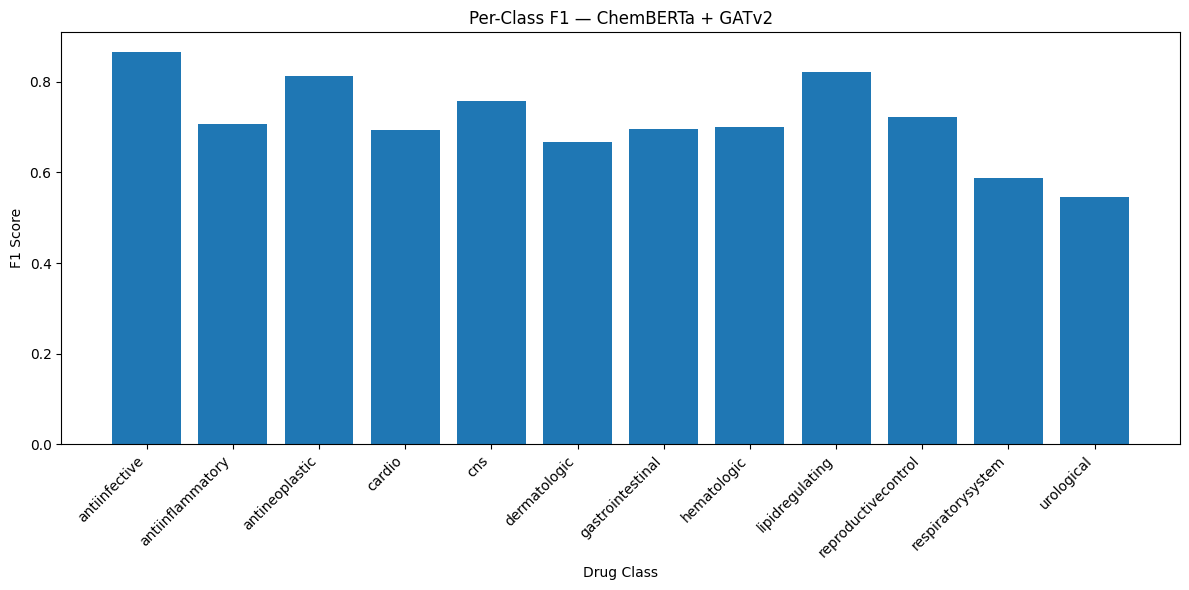

In [ ]:
# ============================================================
# CELL 21 — PER-CLASS F1
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    per_class_results["Label"],
    per_class_results["F1"]
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("F1 Score")
plt.xlabel("Drug Class")

plt.title(
    "Per-Class F1 — ChemBERTa + GATv2"
)

plt.tight_layout()

plt.show()

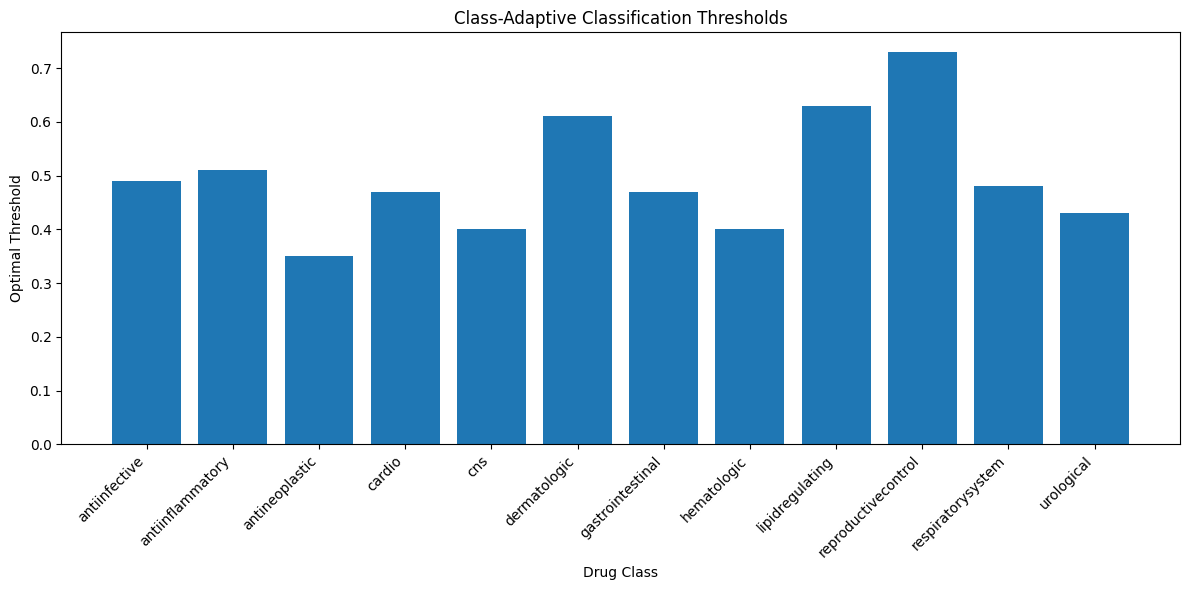

In [ ]:
# ============================================================
# CELL 22 — CLASS-SPECIFIC THRESHOLDS
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    threshold_table["Label"],
    threshold_table["Threshold"]
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("Optimal Threshold")
plt.xlabel("Drug Class")

plt.title(
    "Class-Adaptive Classification Thresholds"
)

plt.tight_layout()

plt.show()

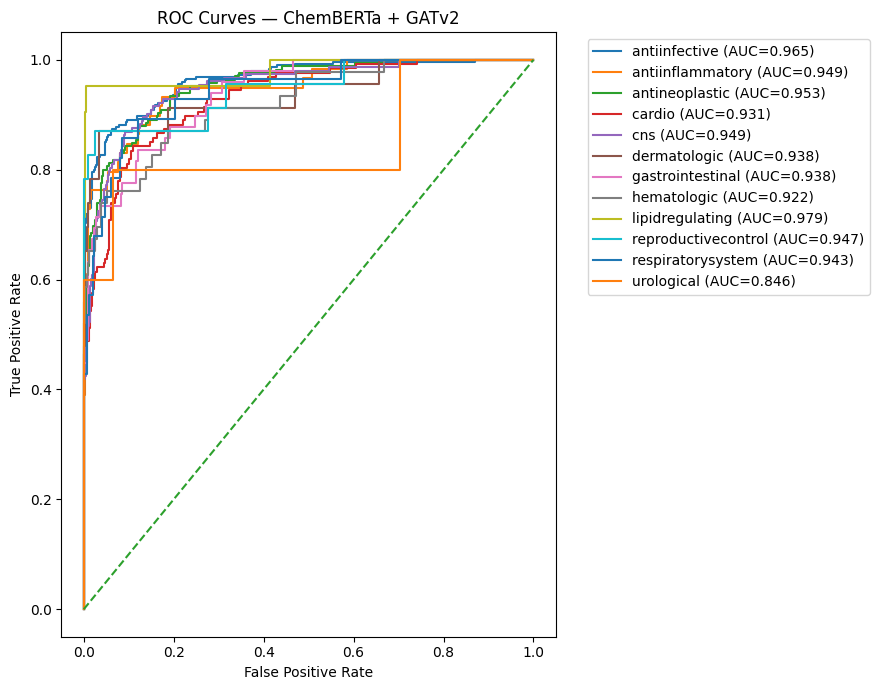

In [ ]:
# ============================================================
# CELL 23 — ROC CURVES
# ============================================================

from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize

plt.figure(figsize=(9, 7))

for i, label in enumerate(mlb.classes_):

    try:

        fpr, tpr, _ = roc_curve(
            test_true[:, i],
            test_probabilities[:, i]
        )

        auc = roc_auc_score(
            test_true[:, i],
            test_probabilities[:, i]
        )

        plt.plot(
            fpr,
            tpr,
            label=f"{label} (AUC={auc:.3f})"
        )

    except ValueError:
        continue

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curves — ChemBERTa + GATv2"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 70.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 84.7 MB/s eta 0:00:00
Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Mounted at /content/drive
Dataset exists: True
Original shape: (8336, 4)
Columns: ['image_name', 'tags', 'smiles', 'Col3']


,image_name,tags,smiles,Col3
0,pics/0,dermatologic,CC(=O)NC1C(O)OC(CO)C(O)C1O,['dermatologic']
1,pics/1,antiinfective,CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...,['antiinfective']
2,pics/2,antiinfective,CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...,['antiinfective']
3,pics/3,antineoplastic,COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...,['antineoplastic']
4,pics/4,antiinfective respiratorysystem,CC(=O)N[C@@H](CS)C(=O)[O-],"['antiinfective', 'respiratorysystem']"


After cleaning: (8336, 5)


[13:45:48] Conflicting single bond directions around double bond at index 1.
[13:45:48]   BondStereo set to STEREONONE and single bond directions set to NONE.
[13:45:48] WARNING: not removing hydrogen atom without neighbors
[13:45:48] WARNING: not removing hydrogen atom without neighbors
[13:45:49] WARNING: not removing hydrogen atom without neighbors
[13:45:49] WARNING: not removing hydrogen atom without neighbors
[13:45:49] WARNING: not removing hydrogen atom without neighbors
[13:45:49] WARNING: not removing hydrogen atom without neighbors
[13:45:49] Conflicting single bond directions around double bond at index 1.
[13:45:49]   BondStereo set to STEREONONE and single bond directions set to NONE.
[13:45:49] WARNING: not removing hydrogen atom without neighbors
[13:45:49] WARNING: not removing hydrogen atom without neighbors
[13:45:49] Conflicting single bond directions around double bond at index 1.
[13:45:49]   BondStereo set to STEREONONE and single bond directions set to NONE.
[13

Invalid SMILES: 0
Final dataset: (8336, 6)

Number of labels: 12
 0 -> antiinfective
 1 -> antiinflammatory
 2 -> antineoplastic
 3 -> cardio
 4 -> cns
 5 -> dermatologic
 6 -> gastrointestinal
 7 -> hematologic
 8 -> lipidregulating
 9 -> reproductivecontrol
10 -> respiratorysystem
11 -> urological


...

,Metric,ChemBERTa + GATv2 + CrossAttention
0,Macro Precision,0.811985
1,Macro Recall,0.704509
2,Macro F1,0.747068
3,Micro F1,0.790010
4,Weighted F1,0.787154
5,Macro AUROC,0.945704
6,Micro AUROC,0.964129
7,Macro AUPRC,0.793858
8,Micro AUPRC,0.862363


,Label_ID,Label,Support,Threshold,Precision,Recall,F1
0,0,antiinfective,293.0,0.32,0.845426,0.914676,0.878689
1,1,antiinflammatory,59.0,0.46,0.707692,0.779661,0.741935
2,2,antineoplastic,165.0,0.37,0.865772,0.781818,0.821656
3,3,cardio,127.0,0.57,0.815534,0.661417,0.730435
4,4,cns,153.0,0.33,0.707865,0.823529,0.761329
5,5,dermatologic,23.0,0.43,0.894737,0.739130,0.809524
6,6,gastrointestinal,49.0,0.54,0.738095,0.632653,0.681319
7,7,hematologic,46.0,0.39,0.696970,0.500000,0.582278
8,8,lipidregulating,21.0,0.54,0.842105,0.761905,0.800000
9,9,reproductivecontrol,23.0,0.79,1.000000,0.652174,0.789474


,Metric,ChemBERTa,ChemBERTa + GATv2,ChemBERTa + GATv2 + CrossAttention
0,Macro Precision,0.648804,0.791453,0.811985
1,Macro Recall,0.537849,0.665058,0.704509
2,Macro F1,0.558966,0.714579,0.747068
3,Micro F1,0.595284,0.776025,0.790010
4,Weighted F1,0.585794,0.774276,0.787154
5,Macro AUROC,0.884098,0.938436,0.945704
6,Micro AUROC,0.908873,0.964668,0.964129
7,Macro AUPRC,0.610430,0.789712,0.793858
8,Micro AUPRC,0.611315,0.859968,0.862363


,Metric,ChemBERTa,ChemBERTa + GATv2,ChemBERTa + GATv2 + CrossAttention,Gain_vs_GATv2,Gain_%
0,Macro Precision,0.648804,0.791453,0.811985,0.020532,2.594277
1,Macro Recall,0.537849,0.665058,0.704509,0.039451,5.931948
2,Macro F1,0.558966,0.714579,0.747068,0.032489,4.546647
3,Micro F1,0.595284,0.776025,0.790010,0.013985,1.802158
4,Weighted F1,0.585794,0.774276,0.787154,0.012878,1.663293
5,Macro AUROC,0.884098,0.938436,0.945704,0.007268,0.774463
6,Micro AUROC,0.908873,0.964668,0.964129,-0.000539,-0.055885
7,Macro AUPRC,0.610430,0.789712,0.793858,0.004146,0.524980
8,Micro AUPRC,0.611315,0.859968,0.862363,0.002395,0.278453



All results saved to:
/content/drive/MyDrive/dataset/chemberta_gatv2_crossattention_results


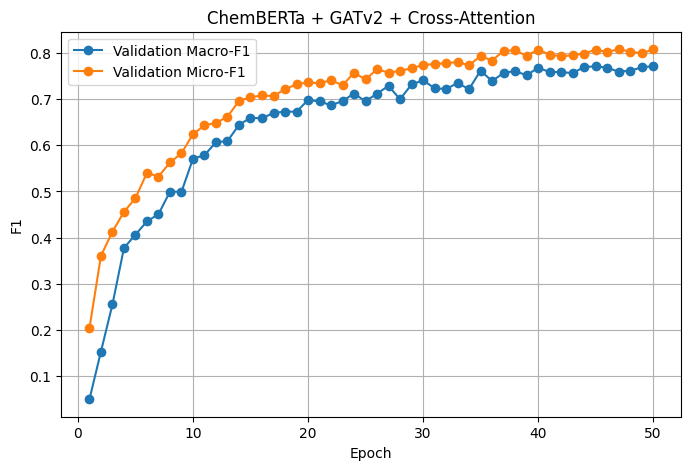

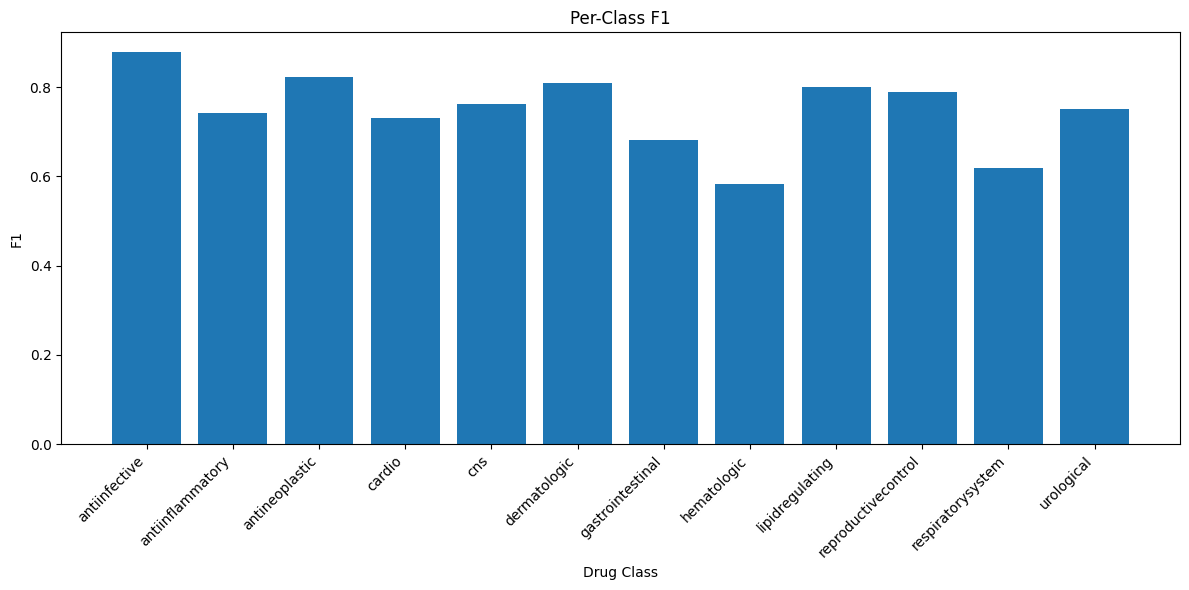


FINAL MODEL SUMMARY
Model: ChemBERTa + GATv2 + Cross-Attention
Macro Precision : 0.8120
Macro Recall    : 0.7045
Macro F1        : 0.7471
Micro F1        : 0.7900
Weighted F1     : 0.7872
Macro AUROC     : 0.9457
Micro AUROC     : 0.9641
Macro AUPRC     : 0.7939
Micro AUPRC     : 0.8624


In [ ]:
# ================================================================
# COMPLETE PIPELINE
# ChemBERTa + GATv2 + Cross-Attention
# Multi-label Drug Classification from SMILES
# ================================================================

# ================================================================
# 1. INSTALL
# ================================================================

!pip install -q transformers rdkit torch-geometric iterative-stratification


# ================================================================
# 2. IMPORTS
# ================================================================

import os
import ast
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel

from rdkit import Chem
from rdkit.Chem import rdchem

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATv2Conv

from sklearn.preprocessing import MultiLabelBinarizer

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

import matplotlib.pyplot as plt


# ================================================================
# 3. REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ================================================================
# 4. GOOGLE DRIVE
# ================================================================

from google.colab import drive

drive.mount("/content/drive")

DATA_PATH = (
    "/content/drive/MyDrive/dataset/all_chem_df.csv"
)

RESULT_DIR = (
    "/content/drive/MyDrive/dataset/"
    "chemberta_gatv2_crossattention_results"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

print("Dataset exists:",
      os.path.exists(DATA_PATH))


# ================================================================
# 5. LOAD DATA
# ================================================================

df = pd.read_csv(DATA_PATH)

print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


# ================================================================
# 6. PARSE LABELS
# ================================================================

def parse_labels(value):

    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:

        parsed = ast.literal_eval(str(value))

        if isinstance(parsed, list):

            return [
                str(x).strip()
                for x in parsed
                if str(x).strip()
            ]

        return [str(parsed).strip()]

    except:

        return [
            x.strip()
            for x in str(value).split(",")
            if x.strip()
        ]


df["smiles"] = (
    df["smiles"]
    .astype(str)
    .str.strip()
)

df["labels_list"] = (
    df["Col3"]
    .apply(parse_labels)
)

df = df[
    df["smiles"].notna()
].reset_index(drop=True)

df = df[
    df["labels_list"].apply(len) > 0
].reset_index(drop=True)

print("After cleaning:", df.shape)


# ================================================================
# 7. VALIDATE SMILES
# ================================================================

def is_valid_smiles(smiles):

    try:

        mol = Chem.MolFromSmiles(
            smiles
        )

        return mol is not None

    except:

        return False


df["valid"] = (
    df["smiles"]
    .apply(is_valid_smiles)
)

print(
    "Invalid SMILES:",
    (~df["valid"]).sum()
)

df = df[
    df["valid"]
].reset_index(drop=True)

print(
    "Final dataset:",
    df.shape
)


# ================================================================
# 8. MULTI-LABEL ENCODING
# ================================================================

mlb = MultiLabelBinarizer()

labels = mlb.fit_transform(
    df["labels_list"]
)

NUM_LABELS = len(
    mlb.classes_
)

print("\nNumber of labels:",
      NUM_LABELS)

for i, c in enumerate(
    mlb.classes_
):

    print(
        f"{i:2d} -> {c}"
    )


# ================================================================
# 9. CLASS DISTRIBUTION
# ================================================================

class_counts = (
    labels.sum(axis=0)
)

class_distribution = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Label":
        mlb.classes_,

    "Positive_Count":
        class_counts,

    "Negative_Count":
        len(labels) - class_counts,

    "Percentage":
        class_counts /
        len(labels) * 100
})

display(
    class_distribution
)


# ================================================================
# 10. MULTI-LABEL STRATIFIED SPLIT
# ================================================================

X = df["smiles"].values
Y = labels

splitter = (
    MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=SEED
    )
)

train_idx, temp_idx = next(
    splitter.split(X, Y)
)

temp_X = X[temp_idx]
temp_Y = Y[temp_idx]

splitter2 = (
    MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=SEED
    )
)

val_rel, test_rel = next(
    splitter2.split(
        temp_X,
        temp_Y
    )
)

val_idx = temp_idx[val_rel]
test_idx = temp_idx[test_rel]


# ================================================================
# 11. CREATE DATASETS
# ================================================================

train_df = df.iloc[
    train_idx
].reset_index(drop=True)

val_df = df.iloc[
    val_idx
].reset_index(drop=True)

test_df = df.iloc[
    test_idx
].reset_index(drop=True)

train_labels = labels[
    train_idx
]

val_labels = labels[
    val_idx
]

test_labels = labels[
    test_idx
]

print(
    "\nTrain:",
    train_df.shape,
    train_labels.shape
)

print(
    "Validation:",
    val_df.shape,
    val_labels.shape
)

print(
    "Test:",
    test_df.shape,
    test_labels.shape
)


# ================================================================
# 12. SPLIT DISTRIBUTION
# ================================================================

split_distribution = pd.DataFrame({

    "Label":
        mlb.classes_,

    "Train":
        train_labels.sum(axis=0),

    "Validation":
        val_labels.sum(axis=0),

    "Test":
        test_labels.sum(axis=0)
})

display(
    split_distribution
)


# ================================================================
# 13. CHEMBERTA
# ================================================================

MODEL_NAME = (
    "DeepChem/ChemBERTa-77M-MLM"
)

MAX_LENGTH = 128

tokenizer = (
    AutoTokenizer.from_pretrained(
        MODEL_NAME
    )
)

print(
    "ChemBERTa loaded."
)


# ================================================================
# 14. MOLECULAR GRAPH FEATURES
# ================================================================

def atom_features(atom):

    return [

        atom.GetAtomicNum(),

        atom.GetDegree(),

        atom.GetFormalCharge(),

        int(
            atom.GetIsAromatic()
        ),

        int(
            atom.GetHybridization()
        ),

        atom.GetTotalNumHs()
    ]


def bond_features(bond):

    bt = bond.GetBondType()

    return [

        float(
            bt ==
            rdchem.BondType.SINGLE
        ),

        float(
            bt ==
            rdchem.BondType.DOUBLE
        ),

        float(
            bt ==
            rdchem.BondType.TRIPLE
        ),

        float(
            bt ==
            rdchem.BondType.AROMATIC
        )
    ]


def smiles_to_graph(smiles):

    mol = Chem.MolFromSmiles(
        smiles
    )

    if mol is None:

        raise ValueError(
            "Invalid SMILES"
        )

    node_features = [

        atom_features(atom)

        for atom in mol.GetAtoms()
    ]

    x = torch.tensor(
        node_features,
        dtype=torch.float
    )

    edge_index = []
    edge_attr = []

    for bond in mol.GetBonds():

        a = bond.GetBeginAtomIdx()
        b = bond.GetEndAtomIdx()

        bf = bond_features(
            bond
        )

        edge_index.append(
            [a, b]
        )

        edge_index.append(
            [b, a]
        )

        edge_attr.append(
            bf
        )

        edge_attr.append(
            bf
        )

    if len(edge_index) == 0:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

        edge_attr = torch.empty(
            (0, 4),
            dtype=torch.float
        )

    else:

        edge_index = torch.tensor(
            edge_index,
            dtype=torch.long
        ).t().contiguous()

        edge_attr = torch.tensor(
            edge_attr,
            dtype=torch.float
        )

    return Data(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr
    )


# ================================================================
# 15. TEST GRAPH
# ================================================================

g = smiles_to_graph(
    train_df.iloc[0]["smiles"]
)

print(
    "Nodes:",
    g.x.shape
)

print(
    "Edges:",
    g.edge_index.shape
)


# ================================================================
# 16. DATASET
# ================================================================

class MolecularDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        labels
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        smiles = self.df.iloc[
            idx
        ]["smiles"]

        encoded = tokenizer(
            smiles,
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        graph = (
            smiles_to_graph(smiles)
        )

        return {

            "input_ids":
                encoded[
                    "input_ids"
                ].squeeze(0),

            "attention_mask":
                encoded[
                    "attention_mask"
                ].squeeze(0),

            "graph":
                graph,

            "labels":
                self.labels[idx]
        }


# ================================================================
# 17. DATASETS
# ================================================================

train_dataset = MolecularDataset(
    train_df,
    train_labels
)

val_dataset = MolecularDataset(
    val_df,
    val_labels
)

test_dataset = MolecularDataset(
    test_df,
    test_labels
)


# ================================================================
# 18. COLLATE FUNCTION
# ================================================================

def collate_fn(batch):

    input_ids = torch.stack(
        [
            x["input_ids"]
            for x in batch
        ]
    )

    attention_mask = torch.stack(
        [
            x["attention_mask"]
            for x in batch
        ]
    )

    labels_batch = torch.stack(
        [
            x["labels"]
            for x in batch
        ]
    )

    graphs = Batch.from_data_list(
        [
            x["graph"]
            for x in batch
        ]
    )

    return {

        "input_ids":
            input_ids,

        "attention_mask":
            attention_mask,

        "graph":
            graphs,

        "labels":
            labels_batch
    }


# ================================================================
# 19. DATALOADERS
# ================================================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)


# ================================================================
# 20. CROSS-ATTENTION MODEL
# ================================================================

class ChemBERTaGATCrossAttention(
    nn.Module
):

    def __init__(
        self,
        num_labels,
        hidden_dim=256,
        heads=4,
        dropout=0.20
    ):

        super().__init__()

        # --------------------------------------------------------
        # ChemBERTa
        # --------------------------------------------------------

        self.chemberta = (
            AutoModel.from_pretrained(
                MODEL_NAME
            )
        )

        bert_dim = (
            self.chemberta
            .config
            .hidden_size
        )

        self.bert_projection = (
            nn.Linear(
                bert_dim,
                hidden_dim
            )
        )

        # --------------------------------------------------------
        # GATv2
        # --------------------------------------------------------

        self.gat1 = GATv2Conv(
            6,
            hidden_dim,
            heads=heads,
            concat=False,
            dropout=dropout
        )

        self.gat2 = GATv2Conv(
            hidden_dim,
            hidden_dim,
            heads=heads,
            concat=False,
            dropout=dropout
        )

        # --------------------------------------------------------
        # Graph -> sequence token space
        # --------------------------------------------------------

        self.graph_projection = (
            nn.Linear(
                hidden_dim,
                hidden_dim
            )
        )

        # --------------------------------------------------------
        # Cross Attention
        #
        # Query  = ChemBERTa tokens
        # Key    = graph representation
        # Value  = graph representation
        # --------------------------------------------------------

        self.cross_attention = (
            nn.MultiheadAttention(
                embed_dim=hidden_dim,
                num_heads=heads,
                dropout=dropout,
                batch_first=True
            )
        )

        self.attention_norm = (
            nn.LayerNorm(
                hidden_dim
            )
        )

        # --------------------------------------------------------
        # Feed Forward
        # --------------------------------------------------------

        self.ffn = nn.Sequential(

            nn.Linear(
                hidden_dim,
                hidden_dim * 2
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            )
        )

        self.ffn_norm = (
            nn.LayerNorm(
                hidden_dim
            )
        )

        # --------------------------------------------------------
        # Fusion
        # --------------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            ),

            nn.LayerNorm(
                hidden_dim
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            )
        )

        # --------------------------------------------------------
        # Classification
        # --------------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_dim,
                hidden_dim // 2
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim // 2,
                num_labels
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        graph
    ):

        # ========================================================
        # CHEMBERTA TOKEN REPRESENTATION
        # ========================================================

        bert_output = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        token_features = (
            self.bert_projection(
                bert_output.last_hidden_state
            )
        )

        # ========================================================
        # MOLECULAR GRAPH
        # ========================================================

        x = graph.x

        x = self.gat1(
            x,
            graph.edge_index
        )

        x = F.gelu(x)

        x = self.gat2(
            x,
            graph.edge_index
        )

        x = F.gelu(x)

        # ========================================================
        # CREATE GRAPH REPRESENTATION
        # ========================================================

        # Number of molecules in batch
        batch_size = (
            input_ids.size(0)
        )

        graph_sequences = []

        for i in range(batch_size):

            molecule_nodes = (
                x[graph.batch == i]
            )

            graph_sequences.append(
                molecule_nodes
            )

        # Pad graph node sequences
        max_nodes = max(
            g.size(0)
            for g in graph_sequences
        )

        padded_graph = []

        graph_padding_mask = []

        for g in graph_sequences:

            n = g.size(0)

            if n < max_nodes:

                padding = torch.zeros(
                    max_nodes - n,
                    g.size(1),
                    device=g.device
                )

                g_padded = torch.cat(
                    [
                        g,
                        padding
                    ],
                    dim=0
                )

                mask = torch.cat(
                    [
                        torch.zeros(
                            n,
                            dtype=torch.bool,
                            device=g.device
                        ),

                        torch.ones(
                            max_nodes - n,
                            dtype=torch.bool,
                            device=g.device
                        )
                    ]
                )

            else:

                g_padded = g

                mask = torch.zeros(
                    max_nodes,
                    dtype=torch.bool,
                    device=g.device
                )

            padded_graph.append(
                g_padded
            )

            graph_padding_mask.append(
                mask
            )

        graph_sequence = torch.stack(
            padded_graph
        )

        graph_padding_mask = torch.stack(
            graph_padding_mask
        )

        graph_sequence = (
            self.graph_projection(
                graph_sequence
            )
        )

        # ========================================================
        # CROSS ATTENTION
        # ========================================================

        attended, attention_weights = (
            self.cross_attention(

                query=token_features,

                key=graph_sequence,

                value=graph_sequence,

                key_padding_mask=
                    graph_padding_mask
            )
        )

        # Residual connection
        token_features = (
            token_features
            +
            attended
        )

        token_features = (
            self.attention_norm(
                token_features
            )
        )

        # ========================================================
        # FEED FORWARD
        # ========================================================

        token_features = (
            token_features
            +
            self.ffn(
                token_features
            )
        )

        token_features = (
            self.ffn_norm(
                token_features
            )
        )

        # ========================================================
        # ATTENTION MASKED MEAN POOLING
        # ========================================================

        mask = (
            attention_mask
            .unsqueeze(-1)
            .float()
        )

        bert_fused = (
            token_features * mask
        ).sum(dim=1)

        bert_fused = (
            bert_fused /
            mask.sum(dim=1)
            .clamp(min=1e-6)
        )

        # ========================================================
        # GRAPH GLOBAL REPRESENTATION
        # ========================================================

        graph_pooled = []

        for i in range(batch_size):

            molecule_nodes = (
                x[graph.batch == i]
            )

            graph_pooled.append(
                molecule_nodes.mean(
                    dim=0
                )
            )

        graph_pooled = torch.stack(
            graph_pooled
        )

        # ========================================================
        # FUSION
        # ========================================================

        combined = torch.cat(
            [
                bert_fused,
                graph_pooled
            ],
            dim=1
        )

        fused = self.fusion(
            combined
        )

        # ========================================================
        # CLASSIFICATION
        # ========================================================

        logits = self.classifier(
            fused
        )

        return logits


# ================================================================
# 21. CREATE MODEL
# ================================================================

model = ChemBERTaGATCrossAttention(
    num_labels=NUM_LABELS,
    hidden_dim=256,
    heads=4,
    dropout=0.20
)

model = model.to(device)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Total parameters:",
    total_params
)

print(
    "Trainable parameters:",
    trainable_params
)


# ================================================================
# 22. CLASS WEIGHTS
# ================================================================

counts = (
    train_labels.sum(axis=0)
)

beta = 0.999

effective_weights = (
    (1 - beta)
    /
    (
        1 -
        np.power(
            beta,
            counts
        )
    )
)

effective_weights = (
    effective_weights /
    effective_weights.mean()
)

effective_weights = np.clip(
    effective_weights,
    0.5,
    10.0
)

class_weights = torch.tensor(
    effective_weights,
    dtype=torch.float32
).to(device)

weight_table = pd.DataFrame({

    "Label":
        mlb.classes_,

    "Count":
        counts,

    "Weight":
        effective_weights
})

display(weight_table)


# ================================================================
# 23. FOCAL BCE LOSS
# ================================================================

class FocalBCELoss(
    nn.Module
):

    def __init__(
        self,
        pos_weight,
        gamma=2.0
    ):

        super().__init__()

        self.pos_weight = (
            pos_weight
        )

        self.gamma = gamma

    def forward(
        self,
        logits,
        targets
    ):

        bce = (
            F.binary_cross_entropy_with_logits(
                logits,
                targets,
                pos_weight=self.pos_weight,
                reduction="none"
            )
        )

        probabilities = (
            torch.sigmoid(
                logits
            )
        )

        pt = (
            targets * probabilities
            +
            (1 - targets)
            *
            (1 - probabilities)
        )

        focal_weight = (
            (1 - pt)
            .pow(self.gamma)
        )

        return (
            focal_weight * bce
        ).mean()


criterion = FocalBCELoss(
    class_weights,
    gamma=2.0
)


# ================================================================
# 24. DIFFERENTIAL LEARNING RATES
# ================================================================

bert_params = []
new_params = []

for name, parameter in (
        model.named_parameters()):

    if name.startswith(
        "chemberta."
    ):

        bert_params.append(
            parameter
        )

    else:

        new_params.append(
            parameter
        )

optimizer = torch.optim.AdamW(

    [
        {
            "params":
                bert_params,
            "lr":
                1e-5
        },

        {
            "params":
                new_params,
            "lr":
                2e-4
        }
    ],

    weight_decay=1e-4
)


# ================================================================
# 25. TRAINING FUNCTION
# ================================================================

def train_one_epoch():

    model.train()

    total_loss = 0
    total_samples = 0

    for batch in train_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        graph = batch[
            "graph"
        ].to(device)

        labels_batch = batch[
            "labels"
        ].to(device)

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            input_ids,
            attention_mask,
            graph
        )

        loss = criterion(
            logits,
            labels_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

        bs = (
            labels_batch.size(0)
        )

        total_loss += (
            loss.item() * bs
        )

        total_samples += bs

    return (
        total_loss /
        total_samples
    )


# ================================================================
# 26. PREDICTION FUNCTION
# ================================================================

@torch.no_grad()
def predict(loader):

    model.eval()

    probabilities = []
    true_labels = []

    for batch in loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        graph = batch[
            "graph"
        ].to(device)

        labels_batch = batch[
            "labels"
        ].to(device)

        logits = model(
            input_ids,
            attention_mask,
            graph
        )

        probs = torch.sigmoid(
            logits
        )

        probabilities.append(
            probs.cpu().numpy()
        )

        true_labels.append(
            labels_batch.cpu().numpy()
        )

    return (
        np.concatenate(
            probabilities
        ),
        np.concatenate(
            true_labels
        )
    )


# ================================================================
# 27. TRAIN
# ================================================================

EPOCHS = 50

BEST_PATH = os.path.join(
    RESULT_DIR,
    "best_model.pt"
)

best_f1 = -1

history = []

for epoch in range(
    EPOCHS
):

    train_loss = (
        train_one_epoch()
    )

    val_prob, val_true = (
        predict(val_loader)
    )

    val_pred = (
        val_prob >= 0.5
    ).astype(int)

    val_macro_f1 = (
        f1_score(
            val_true,
            val_pred,
            average="macro",
            zero_division=0
        )
    )

    val_micro_f1 = (
        f1_score(
            val_true,
            val_pred,
            average="micro",
            zero_division=0
        )
    )

    history.append({

        "Epoch":
            epoch + 1,

        "Train Loss":
            train_loss,

        "Validation Macro F1":
            val_macro_f1,

        "Validation Micro F1":
            val_micro_f1
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss={train_loss:.4f} | "
        f"Macro-F1={val_macro_f1:.4f} | "
        f"Micro-F1={val_micro_f1:.4f}"
    )

    if val_macro_f1 > best_f1:

        best_f1 = (
            val_macro_f1
        )

        torch.save(
            model.state_dict(),
            BEST_PATH
        )

        print(
            "  ✓ Best model saved"
        )


# ================================================================
# 28. LOAD BEST MODEL
# ================================================================

model.load_state_dict(
    torch.load(
        BEST_PATH,
        map_location=device
    )
)

model.to(device)

print(
    "\nBest validation Macro-F1:",
    best_f1
)


# ================================================================
# 29. FINAL VALIDATION PREDICTIONS
# ================================================================

val_prob, val_true = (
    predict(val_loader)
)


# ================================================================
# 30. OPTIMIZE CLASS-SPECIFIC THRESHOLDS
# ================================================================

def optimize_thresholds(
    y_true,
    probabilities
):

    thresholds = np.arange(
        0.10,
        0.91,
        0.01
    )

    best_thresholds = []
    best_f1s = []

    for c in range(
        y_true.shape[1]
    ):

        best_score = -1
        best_threshold = 0.50

        for threshold in thresholds:

            pred = (
                probabilities[:, c]
                >= threshold
            ).astype(int)

            score = f1_score(
                y_true[:, c],
                pred,
                zero_division=0
            )

            if score > best_score:

                best_score = score

                best_threshold = (
                    threshold
                )

        best_thresholds.append(
            best_threshold
        )

        best_f1s.append(
            best_score
        )

    return (
        np.array(best_thresholds),
        np.array(best_f1s)
    )


best_thresholds, val_class_f1 = (
    optimize_thresholds(
        val_true,
        val_prob
    )
)


# ================================================================
# 31. THRESHOLD TABLE
# ================================================================

threshold_table = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Label":
        mlb.classes_,

    "Support":
        val_true.sum(axis=0),

    "Threshold":
        best_thresholds,

    "Validation_F1":
        val_class_f1
})

display(
    threshold_table
)


# ================================================================
# 32. OPTIMIZED VALIDATION METRICS
# ================================================================

val_optimized_pred = np.zeros_like(
    val_prob,
    dtype=int
)

for c in range(
    NUM_LABELS
):

    val_optimized_pred[:, c] = (
        val_prob[:, c]
        >= best_thresholds[c]
    ).astype(int)


print("\nVALIDATION RESULTS")
print("=" * 60)

print(
    "Macro Precision:",
    precision_score(
        val_true,
        val_optimized_pred,
        average="macro",
        zero_division=0
    )
)

print(
    "Macro Recall:",
    recall_score(
        val_true,
        val_optimized_pred,
        average="macro",
        zero_division=0
    )
)

print(
    "Macro F1:",
    f1_score(
        val_true,
        val_optimized_pred,
        average="macro",
        zero_division=0
    )
)

print(
    "Micro F1:",
    f1_score(
        val_true,
        val_optimized_pred,
        average="micro",
        zero_division=0
    )
)


# ================================================================
# 33. FINAL TEST PREDICTIONS
# ================================================================

test_prob, test_true = (
    predict(test_loader)
)

test_pred = np.zeros_like(
    test_prob,
    dtype=int
)

# IMPORTANT:
# Thresholds were learned ONLY from validation data.

for c in range(
    NUM_LABELS
):

    test_pred[:, c] = (
        test_prob[:, c]
        >= best_thresholds[c]
    ).astype(int)


# ================================================================
# 34. TEST METRICS
# ================================================================

test_macro_precision = (
    precision_score(
        test_true,
        test_pred,
        average="macro",
        zero_division=0
    )
)

test_macro_recall = (
    recall_score(
        test_true,
        test_pred,
        average="macro",
        zero_division=0
    )
)

test_macro_f1 = (
    f1_score(
        test_true,
        test_pred,
        average="macro",
        zero_division=0
    )
)

test_micro_f1 = (
    f1_score(
        test_true,
        test_pred,
        average="micro",
        zero_division=0
    )
)

test_weighted_f1 = (
    f1_score(
        test_true,
        test_pred,
        average="weighted",
        zero_division=0
    )
)

test_macro_auroc = (
    roc_auc_score(
        test_true,
        test_prob,
        average="macro"
    )
)

test_micro_auroc = (
    roc_auc_score(
        test_true,
        test_prob,
        average="micro"
    )
)

test_macro_auprc = (
    average_precision_score(
        test_true,
        test_prob,
        average="macro"
    )
)

test_micro_auprc = (
    average_precision_score(
        test_true,
        test_prob,
        average="micro"
    )
)


# ================================================================
# 35. FINAL RESULTS
# ================================================================

final_metrics = pd.DataFrame({

    "Metric": [

        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "ChemBERTa + GATv2 + CrossAttention": [

        test_macro_precision,
        test_macro_recall,
        test_macro_f1,
        test_micro_f1,
        test_weighted_f1,
        test_macro_auroc,
        test_micro_auroc,
        test_macro_auprc,
        test_micro_auprc
    ]
})

display(
    final_metrics
)


# ================================================================
# 36. PER-CLASS TEST METRICS
# ================================================================

precision_per_class = (
    precision_score(
        test_true,
        test_pred,
        average=None,
        zero_division=0
    )
)

recall_per_class = (
    recall_score(
        test_true,
        test_pred,
        average=None,
        zero_division=0
    )
)

f1_per_class = (
    f1_score(
        test_true,
        test_pred,
        average=None,
        zero_division=0
    )
)

per_class = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Label":
        mlb.classes_,

    "Support":
        test_true.sum(axis=0),

    "Threshold":
        best_thresholds,

    "Precision":
        precision_per_class,

    "Recall":
        recall_per_class,

    "F1":
        f1_per_class
})

display(
    per_class
)


# ================================================================
# 37. COMPARE ALL THREE MODELS
# ================================================================

comparison = pd.DataFrame({

    "Metric": [

        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "ChemBERTa": [

        0.648804,
        0.537849,
        0.558966,
        0.595284,
        0.585794,
        0.884098,
        0.908873,
        0.610430,
        0.611315
    ],

    "ChemBERTa + GATv2": [

        0.791453,
        0.665058,
        0.714579,
        0.776025,
        0.774276,
        0.938436,
        0.964668,
        0.789712,
        0.859968
    ],

    "ChemBERTa + GATv2 + CrossAttention": [

        test_macro_precision,
        test_macro_recall,
        test_macro_f1,
        test_micro_f1,
        test_weighted_f1,
        test_macro_auroc,
        test_micro_auroc,
        test_macro_auprc,
        test_micro_auprc
    ]
})

display(
    comparison
)


# ================================================================
# 38. IMPROVEMENT OVER GATv2
# ================================================================

comparison["Gain_vs_GATv2"] = (
    comparison[
        "ChemBERTa + GATv2 + CrossAttention"
    ]
    -
    comparison[
        "ChemBERTa + GATv2"
    ]
)

comparison["Gain_%"] = (
    comparison["Gain_vs_GATv2"]
    /
    comparison[
        "ChemBERTa + GATv2"
    ]
    * 100
)

display(
    comparison
)


# ================================================================
# 39. SAVE RESULTS
# ================================================================

pd.DataFrame(
    history
).to_csv(
    os.path.join(
        RESULT_DIR,
        "training_history.csv"
    ),
    index=False
)

threshold_table.to_csv(
    os.path.join(
        RESULT_DIR,
        "thresholds.csv"
    ),
    index=False
)

per_class.to_csv(
    os.path.join(
        RESULT_DIR,
        "per_class_results.csv"
    ),
    index=False
)

final_metrics.to_csv(
    os.path.join(
        RESULT_DIR,
        "final_metrics.csv"
    ),
    index=False
)

comparison.to_csv(
    os.path.join(
        RESULT_DIR,
        "model_comparison.csv"
    ),
    index=False
)

print(
    "\nAll results saved to:"
)

print(
    RESULT_DIR
)


# ================================================================
# 40. TRAINING CURVE
# ================================================================

history_df = pd.DataFrame(
    history
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Micro F1"],
    marker="o",
    label="Validation Micro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1")

plt.title(
    "ChemBERTa + GATv2 + Cross-Attention"
)

plt.legend()

plt.grid(True)

plt.show()


# ================================================================
# 41. PER-CLASS F1
# ================================================================

plt.figure(
    figsize=(12, 6)
)

plt.bar(
    per_class["Label"],
    per_class["F1"]
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("F1")

plt.xlabel("Drug Class")

plt.title(
    "Per-Class F1"
)

plt.tight_layout()

plt.show()


# ================================================================
# 42. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("FINAL MODEL SUMMARY")
print("=" * 75)

print(
    "Model: ChemBERTa + GATv2 + Cross-Attention"
)

print(
    f"Macro Precision : {test_macro_precision:.4f}"
)

print(
    f"Macro Recall    : {test_macro_recall:.4f}"
)

print(
    f"Macro F1        : {test_macro_f1:.4f}"
)

print(
    f"Micro F1        : {test_micro_f1:.4f}"
)

print(
    f"Weighted F1     : {test_weighted_f1:.4f}"
)

print(
    f"Macro AUROC     : {test_macro_auroc:.4f}"
)

print(
    f"Micro AUROC     : {test_micro_auroc:.4f}"
)

print(
    f"Macro AUPRC     : {test_macro_auprc:.4f}"
)

print(
    f"Micro AUPRC     : {test_micro_auprc:.4f}"
)

print("=" * 75)

All required objects are available.

SMILES:
CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC(C)/C=C/C=C4\COC5C(O)C(C)=CC(C(=O)O3)C45O)O2)C1O

TRUE LABELS:
['antiinfective']

PREDICTED LABELS:
['antiinfective']


,Label_ID,Drug_Class,Probability,Threshold,Predicted,True
0,0,antiinfective,0.964681,0.32,1,1.0
1,4,cns,0.042075,0.33,0,0.0
2,3,cardio,0.025493,0.57,0,0.0
3,1,antiinflammatory,0.017832,0.46,0,0.0
4,2,antineoplastic,0.017044,0.37,0,0.0
5,8,lipidregulating,0.011893,0.54,0,0.0
6,6,gastrointestinal,0.008196,0.54,0,0.0
7,7,hematologic,0.001694,0.39,0,0.0
8,5,dermatologic,0.001504,0.43,0,0.0
9,10,respiratorysystem,0.001275,0.43,0,0.0


Number of atoms: 49
Number of bonds: 53
Input shape: torch.Size([1, 128])
Token representation: torch.Size([1, 128, 256])
Graph representation: torch.Size([1, 49, 256])
Attention shape: torch.Size([1, 128, 49])

Most important ChemBERTa tokens:


,Token,Importance
0,),0.838754
1,),0.837248
2,C,0.834723
3,C,0.831374
4,C,0.831038
5,C,0.829498
6,C,0.826928
7,),0.826681
8,/,0.826467
9,C,0.825444


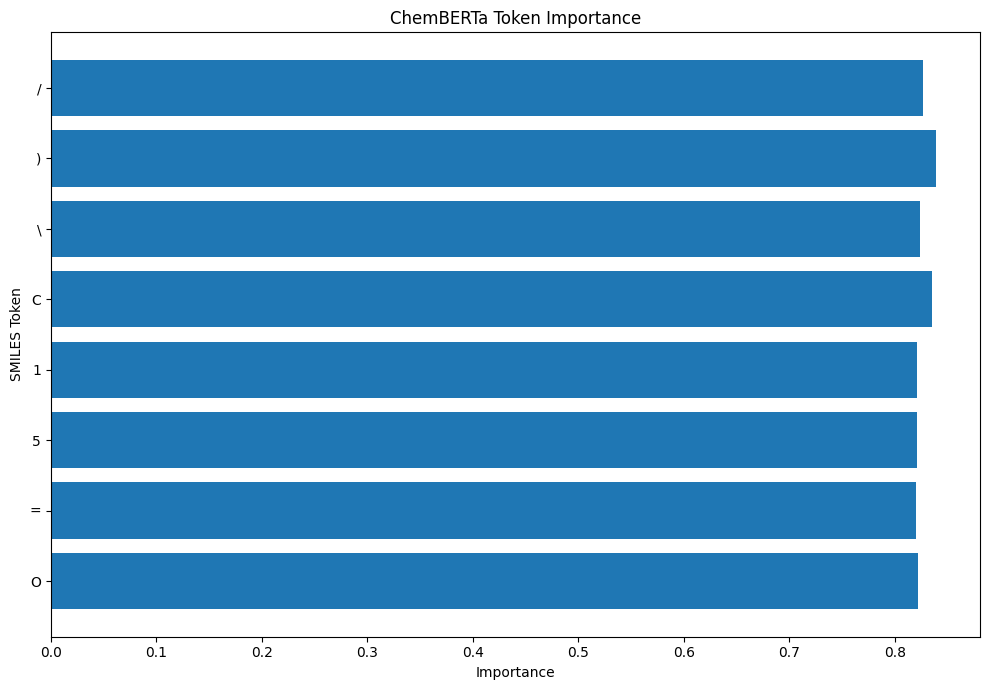


Most important molecular atoms:


,Atom_Index,Element,Importance
0,0,C,0.008554
1,14,C,0.008482
2,1,C,0.008418
3,11,C,0.008415
4,2,C,0.008279
5,3,C,0.008015
6,5,C,0.007914
7,7,O,0.007837
8,42,O,0.007837
9,27,C,0.007817


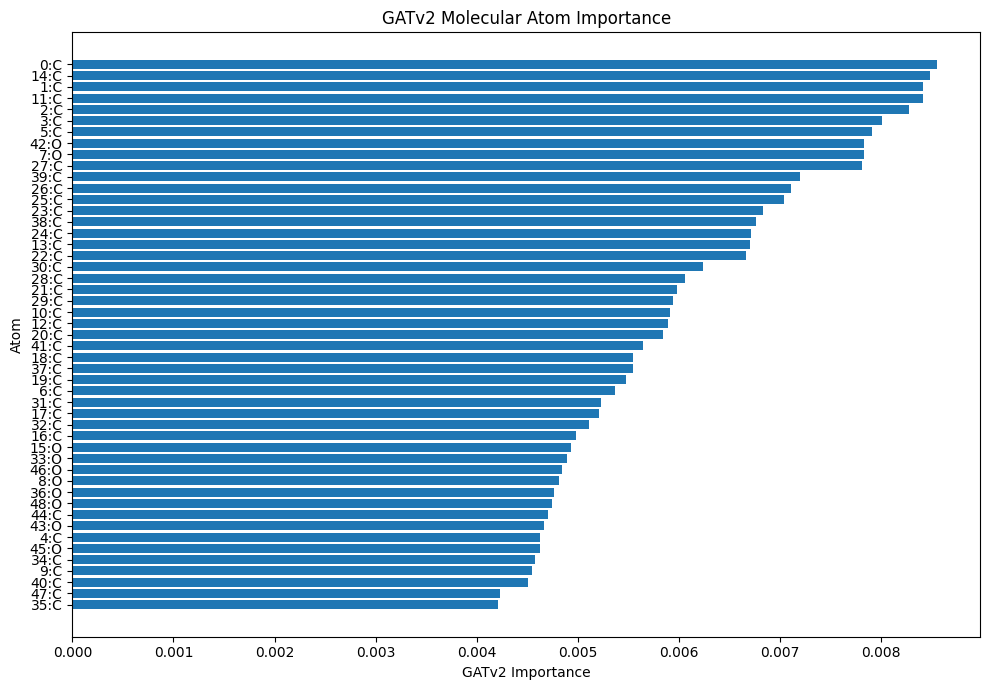

Cross-attention matrix: (128, 49)
Valid token-atom matrix: (96, 49)


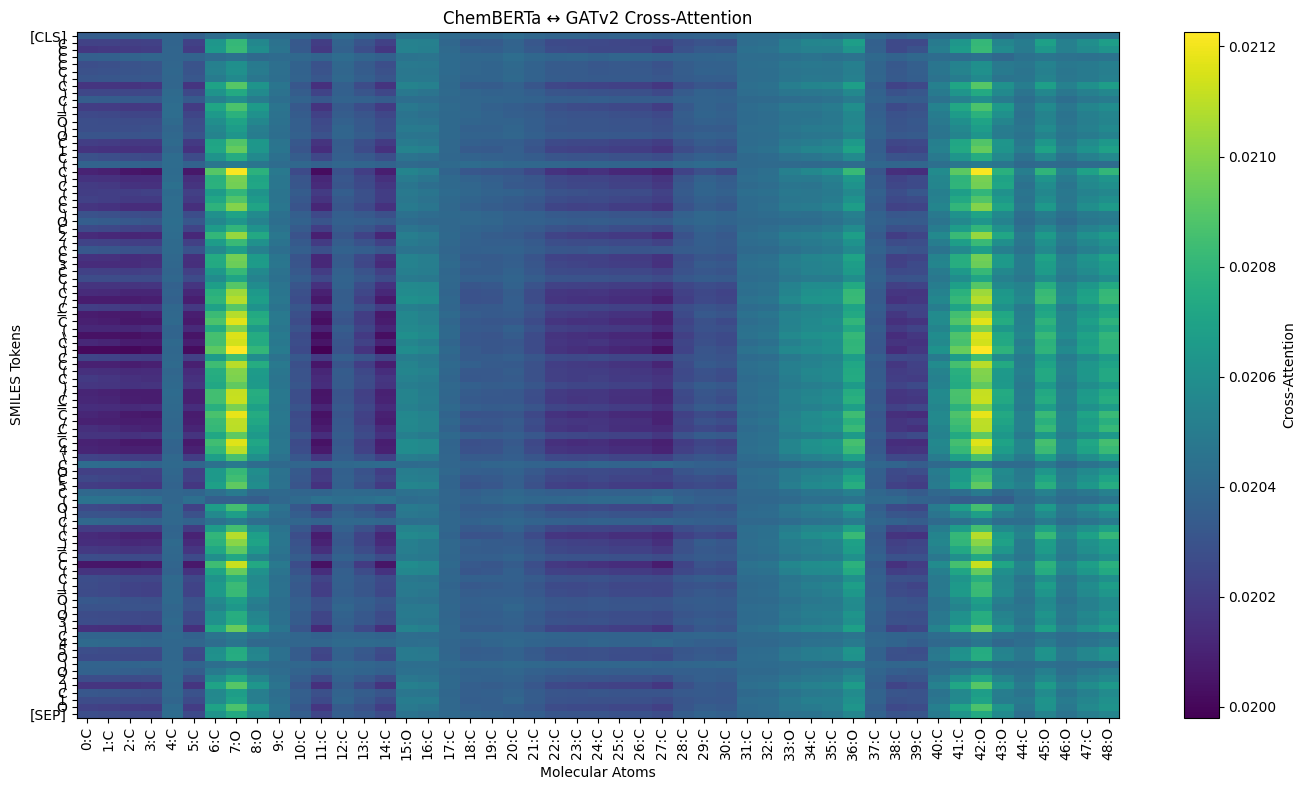


Strongest Token-Atom interactions:


,Token,Atom,Element,Attention
0,),7,O,0.021226
1,),42,O,0.021226
2,C,42,O,0.021212
3,C,7,O,0.021212
4,C,7,O,0.021179
5,C,42,O,0.021179
6,C,42,O,0.021169
7,C,7,O,0.021169
8,C,42,O,0.021164
9,C,7,O,0.021164



Molecular structure:


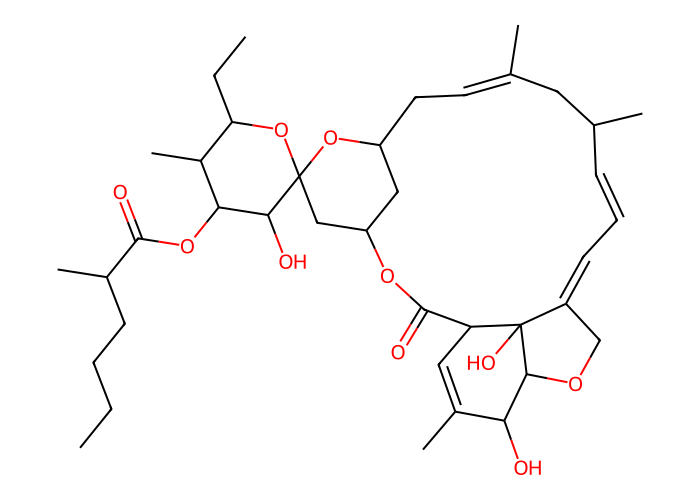


Worst prediction cases:


,Index,True_Labels,Predicted_Labels,True_Positive_Count,False_Positive_Count,False_Negative_Count,Error_Score
756,756,"cardio, hematologic","antiinfective, antiinflammatory, antineoplastic",0,3,2,5
324,324,"antiinfective, antiinflammatory, antineoplastic",cns,0,1,3,4
282,282,"antiinfective, antineoplastic, cardio, hematol...",hematologic,1,0,4,4
576,576,"cardio, hematologic","antiinflammatory, cns",0,2,2,4
536,536,"antiinfective, antiinflammatory, dermatologic",antineoplastic,0,1,3,4
732,732,"antiinfective, respiratorysystem, cardio, hema...","antiinfective, cns",1,1,3,4
593,593,antineoplastic,"cardio, cns",0,2,1,3
521,521,antiinfective,"respiratorysystem, cardio",0,2,1,3
310,310,gastrointestinal,"respiratorysystem, cns",0,2,1,3
251,251,"cardio, hematologic",antineoplastic,0,1,2,3


,Label_ID,Label,TP,FP,FN,Support,F1
0,0,antiinfective,268,49,25,293.0,0.878689
1,1,antiinflammatory,46,19,13,59.0,0.741935
2,2,antineoplastic,129,20,36,165.0,0.821656
3,3,cardio,84,19,43,127.0,0.730435
4,4,cns,126,52,27,153.0,0.761329
5,5,dermatologic,17,2,6,23.0,0.809524
6,6,gastrointestinal,31,11,18,49.0,0.681319
7,7,hematologic,23,10,23,46.0,0.582278
8,8,lipidregulating,16,3,5,21.0,0.800000
9,9,reproductivecontrol,15,0,8,23.0,0.789474




EXPLAINABILITY AND ERROR ANALYSIS COMPLETED
Model:
ChemBERTa + GATv2 + Cross-Attention

Test Macro-F1: 0.7471
Test Micro-F1: 0.7900

Generated:
1. ChemBERTa token importance
2. GATv2 atom importance
3. Token-atom cross-attention
4. Prediction error analysis
5. Class-wise TP/FP/FN analysis

Results directory:
/content/drive/MyDrive/dataset/chemberta_gatv2_crossattention_results


In [ ]:
# ================================================================
# NEXT STEP
# EXPLAINABILITY + ERROR ANALYSIS
# ChemBERTa + GATv2 + Cross-Attention
# ================================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import Draw

from IPython.display import display, Image


# ================================================================
# 1. CHECK REQUIRED OBJECTS
# ================================================================

required_objects = [
    "model",
    "tokenizer",
    "test_df",
    "test_true",
    "test_prob",
    "test_pred",
    "best_thresholds",
    "mlb"
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if len(missing) > 0:

    raise RuntimeError(
        "Missing objects: " +
        ", ".join(missing)
    )

print("All required objects are available.")


# ================================================================
# 2. SELECT A TEST MOLECULE
# ================================================================

sample_index = 0

sample_smiles = test_df.iloc[
    sample_index
]["smiles"]

sample_true = test_true[
    sample_index
]

sample_prob = test_prob[
    sample_index
]

sample_pred = test_pred[
    sample_index
]

print("\nSMILES:")
print(sample_smiles)

print("\nTRUE LABELS:")

true_labels = [
    mlb.classes_[i]
    for i in range(len(mlb.classes_))
    if sample_true[i] == 1
]

print(true_labels)

print("\nPREDICTED LABELS:")

pred_labels = [
    mlb.classes_[i]
    for i in range(len(mlb.classes_))
    if sample_pred[i] == 1
]

print(pred_labels)


# ================================================================
# 3. DISPLAY CLASS PROBABILITIES
# ================================================================

probability_table = pd.DataFrame({

    "Label_ID":
        np.arange(len(mlb.classes_)),

    "Drug_Class":
        mlb.classes_,

    "Probability":
        sample_prob,

    "Threshold":
        best_thresholds,

    "Predicted":
        sample_pred,

    "True":
        sample_true
})

probability_table = (
    probability_table
    .sort_values(
        "Probability",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    probability_table
)


# ================================================================
# 4. CREATE GRAPH
# ================================================================

def smiles_to_graph_explain(smiles):

    mol = Chem.MolFromSmiles(
        smiles
    )

    if mol is None:

        raise ValueError(
            "Invalid SMILES"
        )

    node_features = []

    for atom in mol.GetAtoms():

        node_features.append([

            atom.GetAtomicNum(),

            atom.GetDegree(),

            atom.GetFormalCharge(),

            int(
                atom.GetIsAromatic()
            ),

            int(
                atom.GetHybridization()
            ),

            atom.GetTotalNumHs()

        ])

    x = torch.tensor(
        node_features,
        dtype=torch.float32
    )

    edge_index = []

    for bond in mol.GetBonds():

        a = bond.GetBeginAtomIdx()
        b = bond.GetEndAtomIdx()

        edge_index.append(
            [a, b]
        )

        edge_index.append(
            [b, a]
        )

    if len(edge_index) == 0:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

    else:

        edge_index = torch.tensor(
            edge_index,
            dtype=torch.long
        ).t().contiguous()

    return mol, x, edge_index


mol, graph_x, graph_edge_index = (
    smiles_to_graph_explain(
        sample_smiles
    )
)

print(
    "Number of atoms:",
    mol.GetNumAtoms()
)

print(
    "Number of bonds:",
    mol.GetNumBonds()
)


# ================================================================
# 5. PREPARE CHEMBERTA INPUT
# ================================================================

encoded = tokenizer(
    sample_smiles,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

input_ids = encoded[
    "input_ids"
].to(device)

attention_mask = encoded[
    "attention_mask"
].to(device)

print(
    "Input shape:",
    input_ids.shape
)


# ================================================================
# 6. PREPARE GRAPH
# ================================================================

from torch_geometric.data import Data

graph = Data(

    x=graph_x,

    edge_index=
        graph_edge_index

).to(device)

# Required batch vector
graph.batch = torch.zeros(
    graph.x.size(0),
    dtype=torch.long,
    device=device
)


# ================================================================
# 7. MODIFY MODEL TO RETURN INTERMEDIATE REPRESENTATIONS
# ================================================================

# We manually reproduce the forward process
# so that intermediate representations can be extracted.

model.eval()

with torch.no_grad():

    # ------------------------------------------------------------
    # ChemBERTa
    # ------------------------------------------------------------

    bert_output = model.chemberta(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    token_features = (
        model.bert_projection(
            bert_output.last_hidden_state
        )
    )

    # ------------------------------------------------------------
    # GATv2
    # ------------------------------------------------------------

    x = graph.x

    gat1_output = model.gat1(
        x,
        graph.edge_index
    )

    gat1_output = F.gelu(
        gat1_output
    )

    gat2_output = model.gat2(
        gat1_output,
        graph.edge_index
    )

    graph_node_features = F.gelu(
        gat2_output
    )

    # ------------------------------------------------------------
    # Graph projection
    # ------------------------------------------------------------

    graph_sequence = (
        model.graph_projection(
            graph_node_features
        )
    )

    graph_sequence = (
        graph_sequence.unsqueeze(0)
    )

    # ------------------------------------------------------------
    # Cross attention
    # ------------------------------------------------------------

    attended, attention_weights = (
        model.cross_attention(

            query=token_features,

            key=graph_sequence,

            value=graph_sequence
        )
    )

    # ------------------------------------------------------------
    # Residual
    # ------------------------------------------------------------

    fused_tokens = (
        token_features
        +
        attended
    )

    fused_tokens = (
        model.attention_norm(
            fused_tokens
        )
    )

print(
    "Token representation:",
    fused_tokens.shape
)

print(
    "Graph representation:",
    graph_sequence.shape
)

print(
    "Attention shape:",
    attention_weights.shape
)


# ================================================================
# 8. TOKEN IMPORTANCE
# ================================================================

token_importance = (
    fused_tokens
    .abs()
    .mean(dim=-1)
    .squeeze(0)
    .cpu()
    .numpy()
)

tokens = tokenizer.convert_ids_to_tokens(
    input_ids.squeeze(0).cpu().tolist()
)

attention_mask_np = (
    attention_mask
    .squeeze(0)
    .cpu()
    .numpy()
)

token_records = []

for token, importance, mask in zip(
    tokens,
    token_importance,
    attention_mask_np
):

    if mask == 1:

        token_records.append({

            "Token":
                token,

            "Importance":
                float(importance)
        })


token_df = pd.DataFrame(
    token_records
)

token_df = (
    token_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nMost important ChemBERTa tokens:"
)

display(
    token_df.head(20)
)


# ================================================================
# 9. TOKEN IMPORTANCE VISUALIZATION
# ================================================================

top_tokens = (
    token_df
    .head(20)
    .sort_values(
        "Importance"
    )
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_tokens["Token"],
    top_tokens["Importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "SMILES Token"
)

plt.title(
    "ChemBERTa Token Importance"
)

plt.tight_layout()

plt.show()


# ================================================================
# 10. ATOM IMPORTANCE
# ================================================================

atom_importance = (
    graph_node_features
    .abs()
    .mean(dim=-1)
    .detach()
    .cpu()
    .numpy()
)

atom_records = []

for atom_idx, atom in enumerate(
    mol.GetAtoms()
):

    atom_records.append({

        "Atom_Index":
            atom_idx,

        "Element":
            atom.GetSymbol(),

        "Importance":
            float(
                atom_importance[
                    atom_idx
                ]
            )
    })

atom_df = pd.DataFrame(
    atom_records
)

atom_df = (
    atom_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nMost important molecular atoms:"
)

display(
    atom_df
)


# ================================================================
# 11. ATOM IMPORTANCE BAR CHART
# ================================================================

plot_atoms = (
    atom_df
    .sort_values(
        "Importance"
    )
)

atom_names = [

    f"{row.Atom_Index}:{row.Element}"

    for _, row in plot_atoms.iterrows()
]

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    atom_names,
    plot_atoms["Importance"]
)

plt.xlabel(
    "GATv2 Importance"
)

plt.ylabel(
    "Atom"
)

plt.title(
    "GATv2 Molecular Atom Importance"
)

plt.tight_layout()

plt.show()


# ================================================================
# 12. CROSS-ATTENTION ANALYSIS
# ================================================================

# attention_weights normally:
#
# [batch, target_sequence, source_sequence]
#
# target_sequence = SMILES tokens
# source_sequence = molecular atoms

attention = (
    attention_weights
    .squeeze(0)
    .detach()
    .cpu()
    .numpy()
)

print(
    "Cross-attention matrix:",
    attention.shape
)


# ================================================================
# 13. TOKEN-ATOM ATTENTION MATRIX
# ================================================================

valid_tokens = []

for i, token in enumerate(tokens):

    if attention_mask_np[i] == 1:

        valid_tokens.append(
            token
        )

attention_valid = attention[
    :len(valid_tokens),
    :mol.GetNumAtoms()
]

print(
    "Valid token-atom matrix:",
    attention_valid.shape
)


# ================================================================
# 14. ATTENTION HEATMAP
# ================================================================

plt.figure(
    figsize=(14, 8)
)

plt.imshow(
    attention_valid,
    aspect="auto"
)

plt.colorbar(
    label="Cross-Attention"
)

plt.xticks(
    np.arange(
        mol.GetNumAtoms()
    ),
    [
        f"{i}:{a.GetSymbol()}"
        for i, a in enumerate(
            mol.GetAtoms()
        )
    ],
    rotation=90
)

plt.yticks(
    np.arange(
        len(valid_tokens)
    ),
    valid_tokens
)

plt.xlabel(
    "Molecular Atoms"
)

plt.ylabel(
    "SMILES Tokens"
)

plt.title(
    "ChemBERTa ↔ GATv2 Cross-Attention"
)

plt.tight_layout()

plt.show()


# ================================================================
# 15. ATOM-TOKEN ALIGNMENT
# ================================================================

alignment_records = []

for token_idx, token in enumerate(
    valid_tokens
):

    for atom_idx in range(
        mol.GetNumAtoms()
    ):

        alignment_records.append({

            "Token":
                token,

            "Atom":
                atom_idx,

            "Element":
                mol.GetAtomWithIdx(
                    atom_idx
                ).GetSymbol(),

            "Attention":
                attention_valid[
                    token_idx,
                    atom_idx
                ]
        })

alignment_df = pd.DataFrame(
    alignment_records
)

alignment_df = (
    alignment_df
    .sort_values(
        "Attention",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nStrongest Token-Atom interactions:"
)

display(
    alignment_df.head(30)
)


# ================================================================
# 16. MOLECULAR VISUALIZATION
# ================================================================

print(
    "\nMolecular structure:"
)

display(
    Draw.MolToImage(
        mol,
        size=(700, 500)
    )
)


# ================================================================
# 17. ERROR ANALYSIS
# ================================================================

error_records = []

for i in range(
    len(test_true)
):

    true_set = set(
        np.where(
            test_true[i] == 1
        )[0]
    )

    pred_set = set(
        np.where(
            test_pred[i] == 1
        )[0]
    )

    true_positive = (
        true_set & pred_set
    )

    false_positive = (
        pred_set - true_set
    )

    false_negative = (
        true_set - pred_set
    )

    error_records.append({

        "Index":
            i,

        "True_Labels":
            ", ".join(
                mlb.classes_[
                    list(true_set)
                ]
            ),

        "Predicted_Labels":
            ", ".join(
                mlb.classes_[
                    list(pred_set)
                ]
            ),

        "True_Positive_Count":
            len(true_positive),

        "False_Positive_Count":
            len(false_positive),

        "False_Negative_Count":
            len(false_negative)
    })

error_df = pd.DataFrame(
    error_records
)


# ================================================================
# 18. WORST PREDICTIONS
# ================================================================

error_df["Error_Score"] = (
    error_df[
        "False_Positive_Count"
    ]
    +
    error_df[
        "False_Negative_Count"
    ]
)

worst_predictions = (
    error_df
    .sort_values(
        "Error_Score",
        ascending=False
    )
    .head(20)
)

print(
    "\nWorst prediction cases:"
)

display(
    worst_predictions
)


# ================================================================
# 19. CLASS-WISE ERROR ANALYSIS
# ================================================================

class_error = []

for c in range(
    NUM_LABELS
):

    tp = np.sum(
        (
            test_true[:, c] == 1
        )
        &
        (
            test_pred[:, c] == 1
        )
    )

    fp = np.sum(
        (
            test_true[:, c] == 0
        )
        &
        (
            test_pred[:, c] == 1
        )
    )

    fn = np.sum(
        (
            test_true[:, c] == 1
        )
        &
        (
            test_pred[:, c] == 0
        )
    )

    class_error.append({

        "Label_ID":
            c,

        "Label":
            mlb.classes_[c],

        "TP":
            tp,

        "FP":
            fp,

        "FN":
            fn,

        "Support":
            test_true[:, c].sum(),

        "F1":
            f1_score(
                test_true[:, c],
                test_pred[:, c],
                zero_division=0
            )
    })

class_error_df = pd.DataFrame(
    class_error
)

display(
    class_error_df
)


# ================================================================
# 20. SAVE EXPLAINABILITY RESULTS
# ================================================================

token_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_importance.csv"
    ),
    index=False
)

atom_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "atom_importance.csv"
    ),
    index=False
)

alignment_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_atom_attention.csv"
    ),
    index=False
)

error_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "prediction_error_analysis.csv"
    ),
    index=False
)

class_error_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "class_error_analysis.csv"
    ),
    index=False
)


# ================================================================
# 21. FINAL SUMMARY
# ================================================================

print("\n")
print("=" * 75)
print("EXPLAINABILITY AND ERROR ANALYSIS COMPLETED")
print("=" * 75)

print(
    "Model:"
)

print(
    "ChemBERTa + GATv2 + Cross-Attention"
)

print(
    "\nTest Macro-F1:",
    f"{test_macro_f1:.4f}"
)

print(
    "Test Micro-F1:",
    f"{test_micro_f1:.4f}"
)

print(
    "\nGenerated:"
)

print(
    "1. ChemBERTa token importance"
)

print(
    "2. GATv2 atom importance"
)

print(
    "3. Token-atom cross-attention"
)

print(
    "4. Prediction error analysis"
)

print(
    "5. Class-wise TP/FP/FN analysis"
)

print(
    "\nResults directory:"
)

print(
    RESULT_DIR
)

print("=" * 75)

Results directory:
/content/drive/MyDrive/dataset/publication_results
All evaluation variables are available.
Test samples : 831
Classes      : 12
Class names  : ['antiinfective', 'antiinflammatory', 'antineoplastic', 'cardio', 'cns', 'dermatologic', 'gastrointestinal', 'hematologic', 'lipidregulating', 'reproductivecontrol', 'respiratorysystem', 'urological']
Prediction matrices: (831, 12)


FINAL MODEL PERFORMANCE
         Metric    Score
Macro Precision 0.811985
   Macro Recall 0.704509
       Macro F1 0.747068
Micro Precision 0.798969
   Micro Recall 0.781250
       Micro F1 0.790010
    Weighted F1 0.787154
    Macro AUROC 0.945704
    Micro AUROC 0.964129
    Macro AUPRC 0.793858
    Micro AUPRC 0.862363
   Hamming Loss 0.041316


PER-CLASS PERFORMANCE
 Label_ID          Drug_Class  Support  Negative  Positive_Percentage  Threshold  Precision   Recall       F1    AUROC    AUPRC
        0       antiinfective      293       538            35.258724       0.32   0.845426 0.914676 0.

,precision,recall,f1-score,support
antiinfective,0.845426,0.914676,0.878689,293.0
antiinflammatory,0.707692,0.779661,0.741935,59.0
antineoplastic,0.865772,0.781818,0.821656,165.0
cardio,0.815534,0.661417,0.730435,127.0
cns,0.707865,0.823529,0.761329,153.0
dermatologic,0.894737,0.739130,0.809524,23.0
gastrointestinal,0.738095,0.632653,0.681319,49.0
hematologic,0.696970,0.500000,0.582278,46.0
lipidregulating,0.842105,0.761905,0.800000,21.0
reproductivecontrol,1.000000,0.652174,0.789474,23.0


Bootstrapping: Macro Precision
Bootstrapping: Macro Recall
Bootstrapping: Macro F1
Bootstrapping: Micro F1
Bootstrapping: Macro AUROC
Bootstrapping: Macro AUPRC


         Metric     Mean  Lower_95CI  Upper_95CI
Macro Precision 0.807050    0.726145    0.842923
   Macro Recall 0.703659    0.644104    0.756707
       Macro F1 0.741279    0.679290    0.785093
       Micro F1 0.790327    0.765914    0.815038
    Macro AUROC 0.945815    0.930354    0.958700
    Macro AUPRC 0.794055    0.735895    0.842429


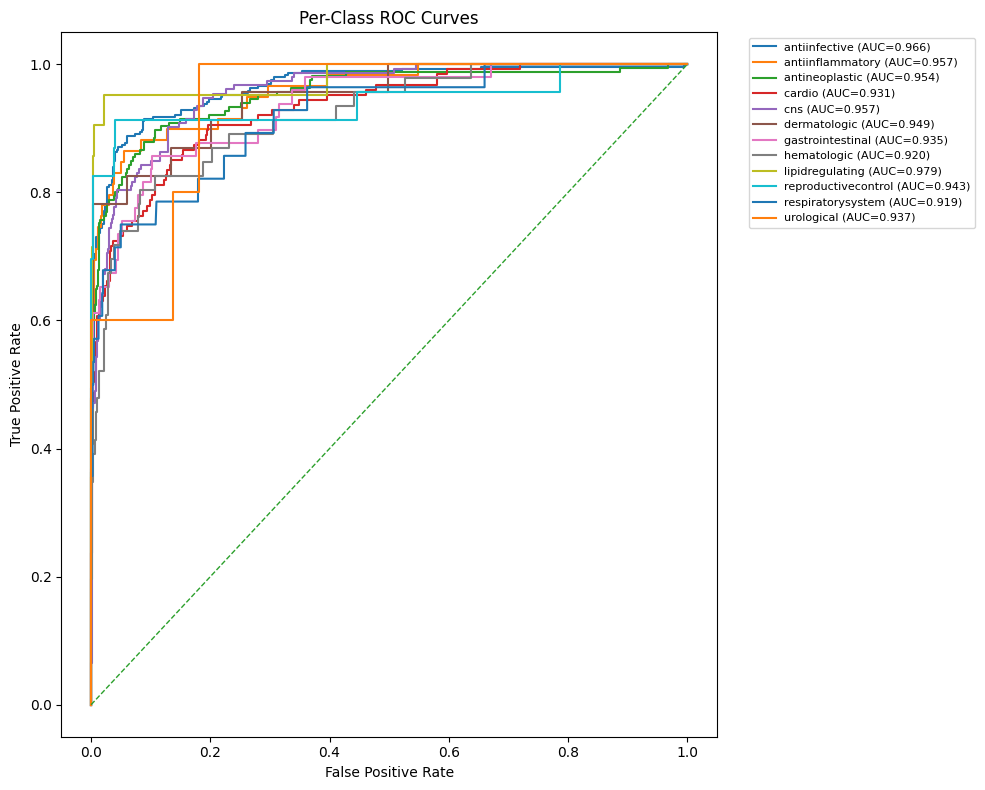

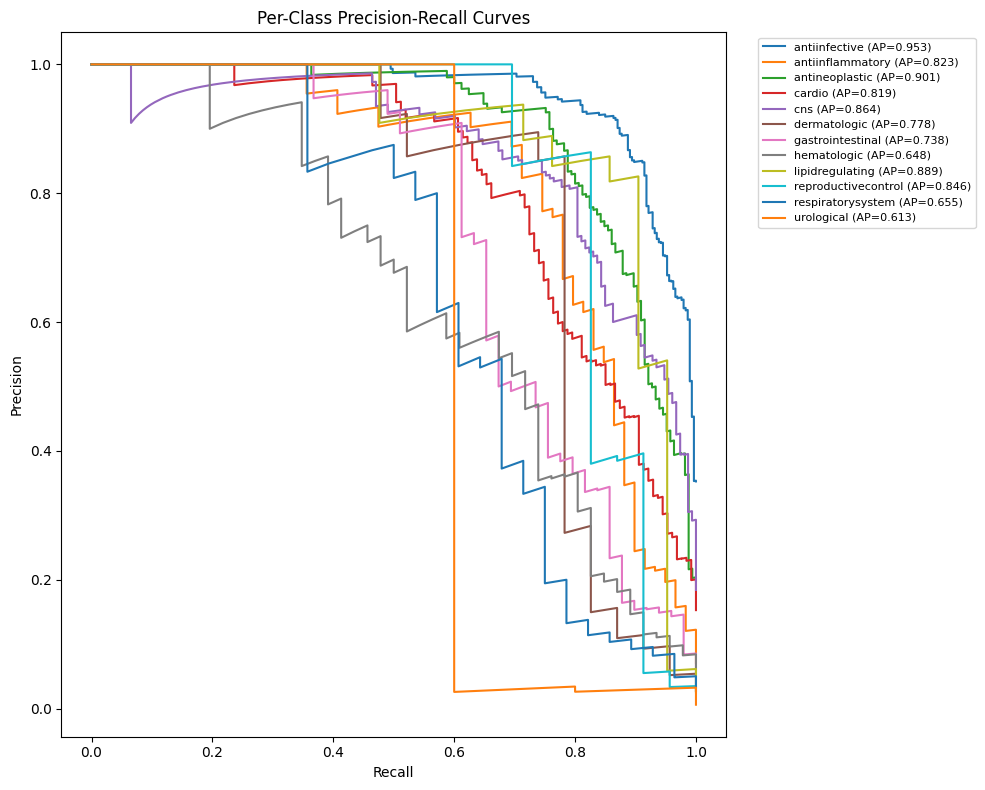

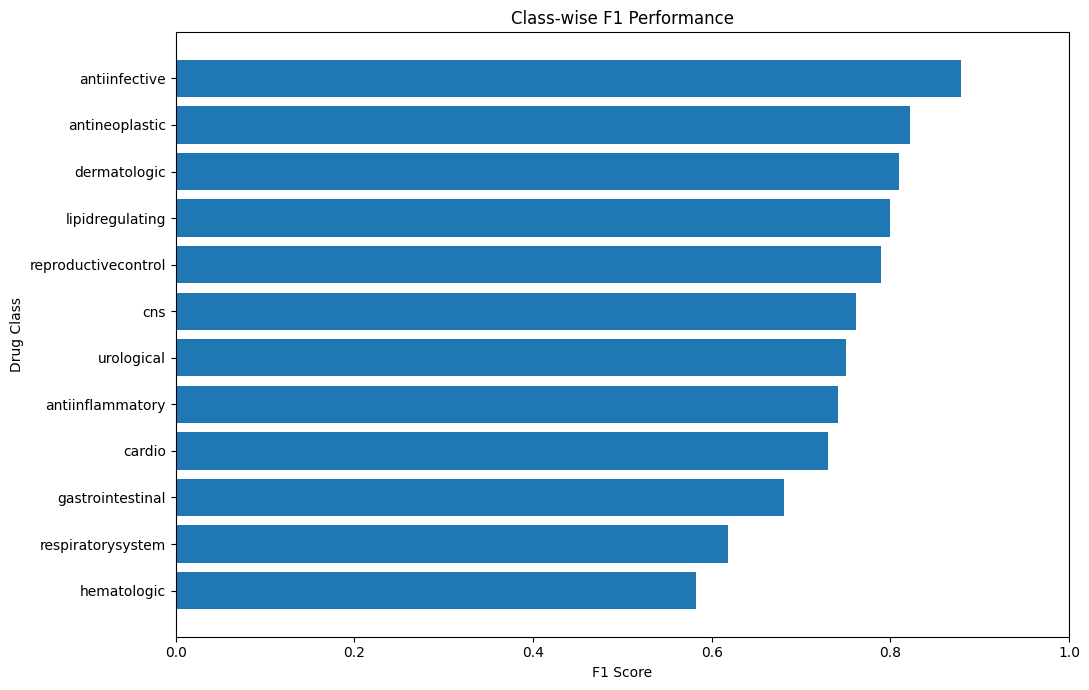

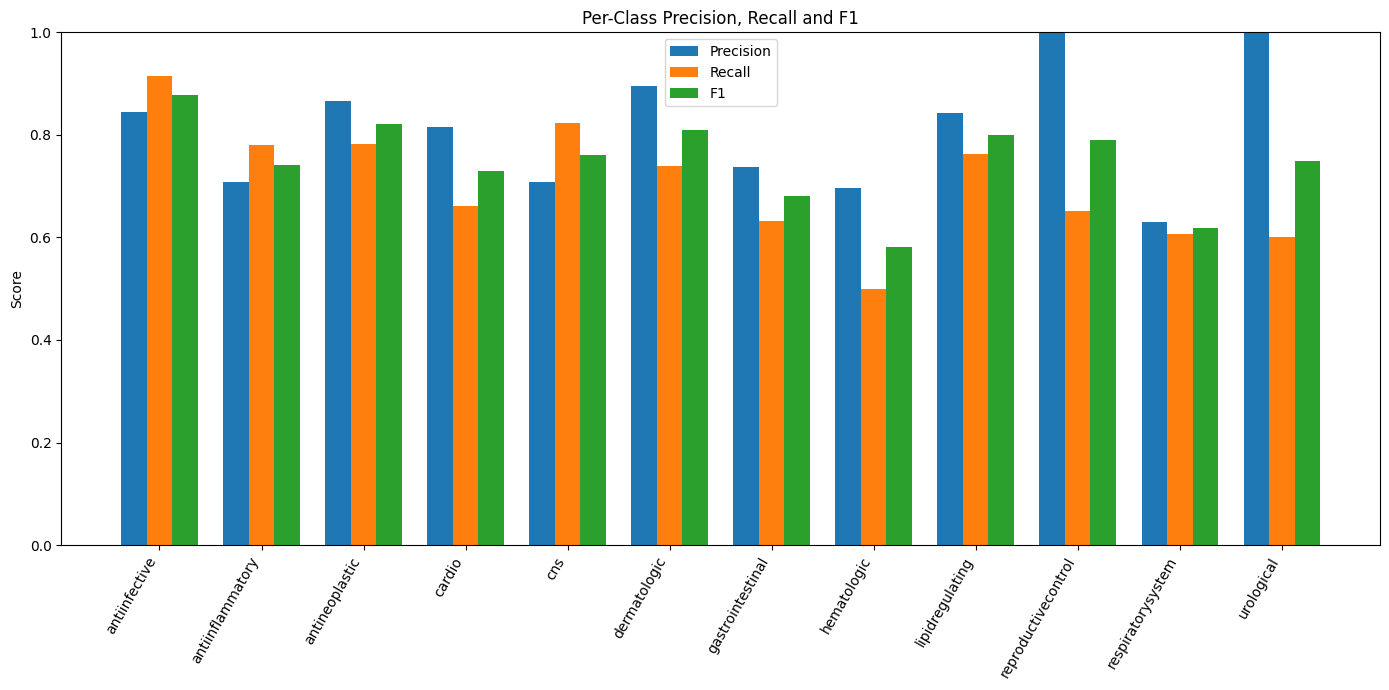

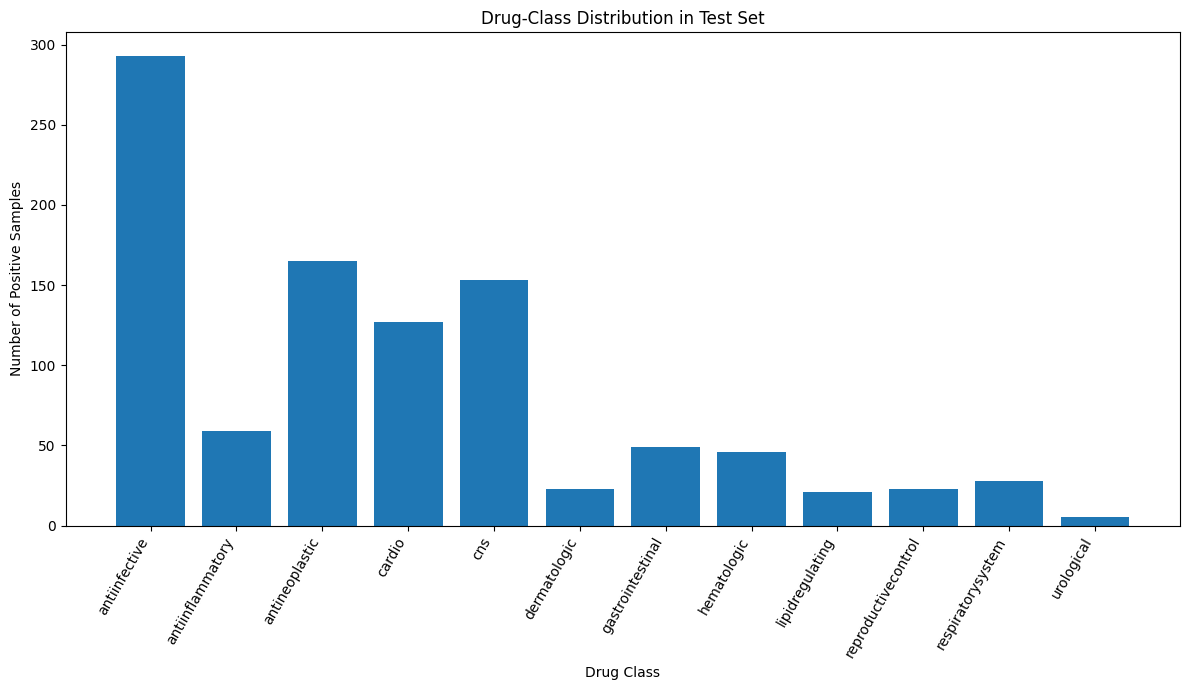

,Sample_Index,True_Labels,Predicted_Labels,TP_Count,FP_Count,FN_Count,Error_Count
756,756,cardio;hematologic,antiinfective;antiinflammatory;antineoplastic,0,3,2,5
324,324,antiinfective;antiinflammatory;antineoplastic,cns,0,1,3,4
282,282,antiinfective;antineoplastic;cardio;hematologi...,hematologic,1,0,4,4
576,576,cardio;hematologic,antiinflammatory;cns,0,2,2,4
536,536,antiinfective;antiinflammatory;dermatologic,antineoplastic,0,1,3,4
732,732,antiinfective;cardio;hematologic;respiratorysy...,antiinfective;cns,1,1,3,4
593,593,antineoplastic,cardio;cns,0,2,1,3
521,521,antiinfective,cardio;respiratorysystem,0,2,1,3
310,310,gastrointestinal,cns;respiratorysystem,0,2,1,3
251,251,cardio;hematologic,antineoplastic,0,1,2,3


,Drug_Class,TN,FP,FN,TP
0,antiinfective,489,49,25,268
1,antiinflammatory,753,19,13,46
2,antineoplastic,646,20,36,129
3,cardio,685,19,43,84
4,cns,626,52,27,126
5,dermatologic,806,2,6,17
6,gastrointestinal,771,11,18,31
7,hematologic,775,10,23,23
8,lipidregulating,807,3,5,16
9,reproductivecontrol,808,0,8,15


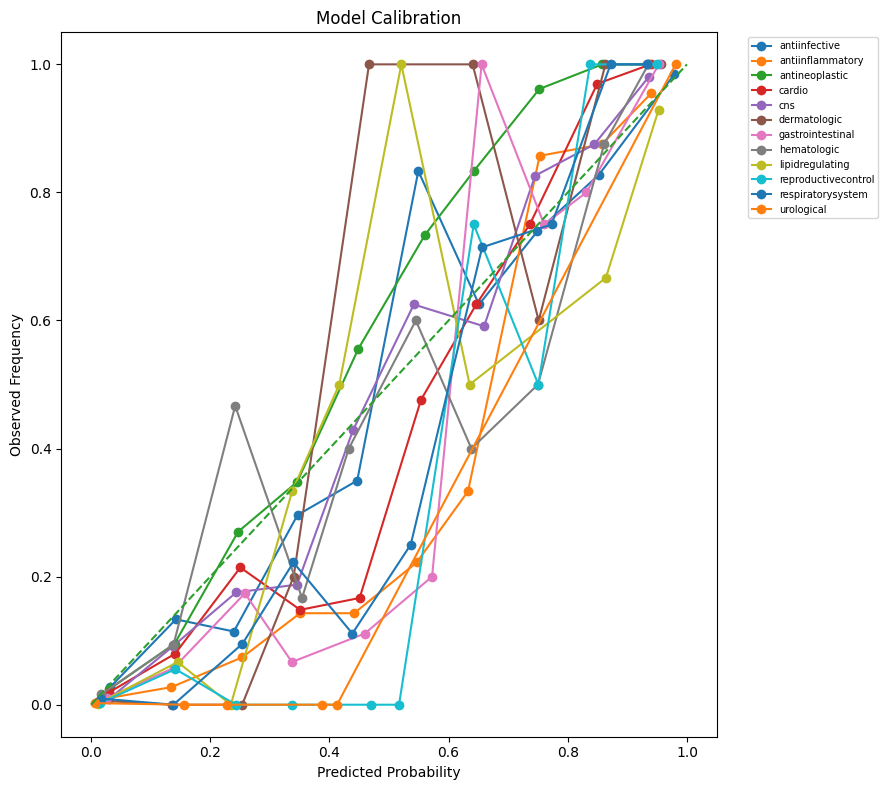

                              Model  Macro_F1  Micro_F1  Weighted_F1  Macro_AUROC  Micro_AUROC  Macro_AUPRC  Micro_AUPRC
                          ChemBERTa  0.558966  0.595284     0.585794     0.884098     0.908873     0.610430     0.611315
                  ChemBERTa + GATv2  0.714579  0.776025     0.774276     0.938436     0.964668     0.789712     0.859968
ChemBERTa + GATv2 + Cross-Attention  0.747100  0.790000     0.787200     0.945700     0.964100     0.793900     0.862400


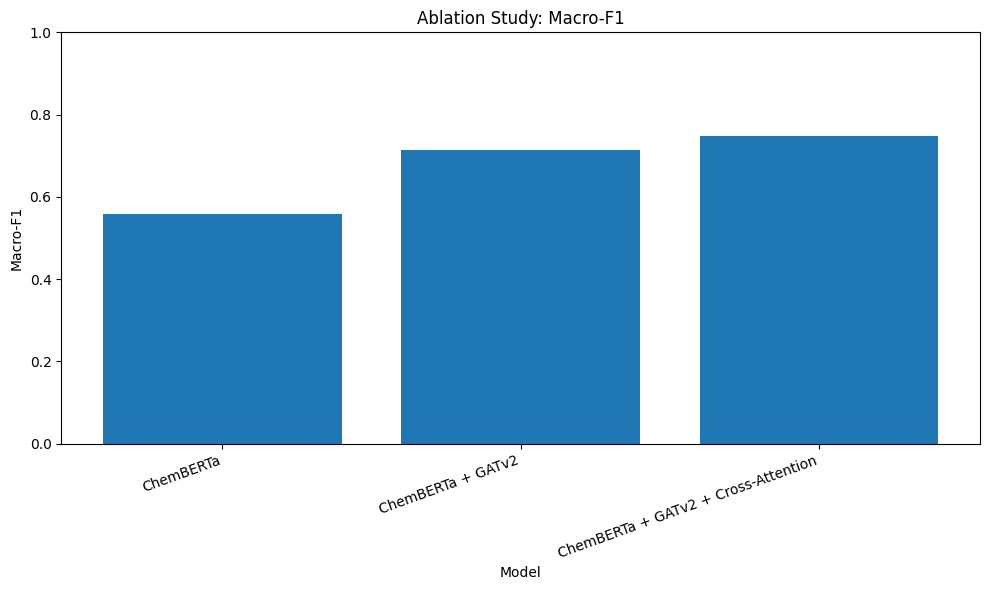

                 Comparison  Absolute_Improvement
0        ChemBERTa → +GATv2              0.155613
1  GATv2 → +Cross-Attention              0.032521
2   ChemBERTa → Final Model              0.188134

Overall relative Macro-F1 improvement: 33.66%

Publication table:


,Label_ID,Drug_Class,Support,Negative,Positive_Percentage,Threshold,Precision,Recall,F1,AUROC,AUPRC
0,0,antiinfective,293,538,35.258724,0.32,0.8454,0.9147,0.8787,0.9662,0.9530
1,1,antiinflammatory,59,772,7.099880,0.46,0.7077,0.7797,0.7419,0.9572,0.8226
2,2,antineoplastic,165,666,19.855596,0.37,0.8658,0.7818,0.8217,0.9539,0.9007
3,3,cardio,127,704,15.282792,0.57,0.8155,0.6614,0.7304,0.9315,0.8193
4,4,cns,153,678,18.411552,0.33,0.7079,0.8235,0.7613,0.9569,0.8641
5,5,dermatologic,23,808,2.767750,0.43,0.8947,0.7391,0.8095,0.9494,0.7780
6,6,gastrointestinal,49,782,5.896510,0.54,0.7381,0.6327,0.6813,0.9354,0.7377
7,7,hematologic,46,785,5.535499,0.39,0.6970,0.5000,0.5823,0.9204,0.6485
8,8,lipidregulating,21,810,2.527076,0.54,0.8421,0.7619,0.8000,0.9791,0.8887
9,9,reproductivecontrol,23,808,2.767750,0.79,1.0000,0.6522,0.7895,0.9425,0.8457




PUBLICATION-QUALITY FINAL STUDY

Model:
ChemBERTa + GATv2 + Cross-Attention

Final Performance:
Macro Precision : 0.8120
Macro Recall    : 0.7045
Macro F1        : 0.7471
Micro F1        : 0.7900
Weighted F1     : 0.7872
Macro AUROC     : 0.9457
Micro AUROC     : 0.9641
Macro AUPRC     : 0.7939
Micro AUPRC     : 0.8624
Hamming Loss    : 0.0413

95% Confidence Intervals:
         Metric     Mean  Lower_95CI  Upper_95CI
Macro Precision 0.807050    0.726145    0.842923
   Macro Recall 0.703659    0.644104    0.756707
       Macro F1 0.741279    0.679290    0.785093
       Micro F1 0.790327    0.765914    0.815038
    Macro AUROC 0.945815    0.930354    0.958700
    Macro AUPRC 0.794055    0.735895    0.842429


FILES GENERATED
Metrics      : /content/drive/MyDrive/dataset/publication_results/tables
Figures      : /content/drive/MyDrive/dataset/publication_results/figures

Publication study completed.


In [ ]:
# ================================================================
# PUBLICATION-QUALITY FINAL STUDY
# ChemBERTa + GATv2 + Cross-Attention
# Multi-label Drug Classification from SMILES
# ================================================================

# ================================================================
# CELL 1 — IMPORTS
# ================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd

import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    roc_curve,
    precision_recall_curve,
    multilabel_confusion_matrix,
    hamming_loss,
    accuracy_score
)

warnings.filterwarnings("ignore")


# ================================================================
# CELL 2 — REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ================================================================
# CELL 3 — RESULT DIRECTORY
# ================================================================

RESULT_DIR = "/content/drive/MyDrive/dataset/publication_results"

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

FIG_DIR = os.path.join(
    RESULT_DIR,
    "figures"
)

TABLE_DIR = os.path.join(
    RESULT_DIR,
    "tables"
)

os.makedirs(
    FIG_DIR,
    exist_ok=True
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)

print("Results directory:")
print(RESULT_DIR)


# ================================================================
# CELL 4 — VERIFY VARIABLES
# ================================================================

required_objects = [
    "test_true",
    "test_prob",
    "test_pred",
    "mlb",
    "best_thresholds"
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:

    raise RuntimeError(
        "Missing variables:\n" +
        "\n".join(missing)
    )

print("All evaluation variables are available.")


# ================================================================
# CELL 5 — CONVERT TO NUMPY
# ================================================================

y_true = np.asarray(
    test_true
).astype(int)

y_prob = np.asarray(
    test_prob
).astype(float)

y_pred = np.asarray(
    test_pred
).astype(int)

class_names = np.asarray(
    mlb.classes_
)

NUM_LABELS = len(
    class_names
)

print("Test samples :", len(y_true))
print("Classes      :", NUM_LABELS)
print("Class names  :", class_names.tolist())


# ================================================================
# CELL 6 — VERIFY DIMENSIONS
# ================================================================

assert y_true.shape == y_prob.shape
assert y_true.shape == y_pred.shape

assert y_true.shape[1] == NUM_LABELS

print(
    "Prediction matrices:",
    y_true.shape
)


# ================================================================
# CELL 7 — FINAL GLOBAL METRICS
# ================================================================

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

micro_precision = precision_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

micro_recall = recall_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

micro_f1 = f1_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

macro_auroc = roc_auc_score(
    y_true,
    y_prob,
    average="macro"
)

micro_auroc = roc_auc_score(
    y_true,
    y_prob,
    average="micro"
)

macro_auprc = average_precision_score(
    y_true,
    y_prob,
    average="macro"
)

micro_auprc = average_precision_score(
    y_true,
    y_prob,
    average="micro"
)

hamming = hamming_loss(
    y_true,
    y_pred
)


# ================================================================
# CELL 8 — FINAL METRIC TABLE
# ================================================================

final_metrics = pd.DataFrame({

    "Metric": [

        "Macro Precision",
        "Macro Recall",
        "Macro F1",

        "Micro Precision",
        "Micro Recall",
        "Micro F1",

        "Weighted F1",

        "Macro AUROC",
        "Micro AUROC",

        "Macro AUPRC",
        "Micro AUPRC",

        "Hamming Loss"
    ],

    "Score": [

        macro_precision,
        macro_recall,
        macro_f1,

        micro_precision,
        micro_recall,
        micro_f1,

        weighted_f1,

        macro_auroc,
        micro_auroc,

        macro_auprc,
        micro_auprc,

        hamming
    ]
})

print("\n")
print("=" * 70)
print("FINAL MODEL PERFORMANCE")
print("=" * 70)

print(
    final_metrics.to_string(
        index=False
    )
)

final_metrics.to_csv(
    os.path.join(
        TABLE_DIR,
        "final_metrics.csv"
    ),
    index=False
)


# ================================================================
# CELL 9 — PER-CLASS METRICS
# ================================================================

precision_label = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

recall_label = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

f1_label = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

auroc_label = []

auprc_label = []

for i in range(NUM_LABELS):

    try:

        auroc = roc_auc_score(
            y_true[:, i],
            y_prob[:, i]
        )

    except:

        auroc = np.nan

    try:

        auprc = average_precision_score(
            y_true[:, i],
            y_prob[:, i]
        )

    except:

        auprc = np.nan

    auroc_label.append(
        auroc
    )

    auprc_label.append(
        auprc
    )


support = y_true.sum(
    axis=0
)

negative = (
    len(y_true) - support
)

positive_percentage = (
    support / len(y_true)
) * 100


per_class = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Drug_Class":
        class_names,

    "Support":
        support,

    "Negative":
        negative,

    "Positive_Percentage":
        positive_percentage,

    "Threshold":
        np.asarray(
            best_thresholds
        ),

    "Precision":
        precision_label,

    "Recall":
        recall_label,

    "F1":
        f1_label,

    "AUROC":
        auroc_label,

    "AUPRC":
        auprc_label
})


print("\n")
print("=" * 70)
print("PER-CLASS PERFORMANCE")
print("=" * 70)

print(
    per_class.to_string(
        index=False
    )
)

per_class.to_csv(
    os.path.join(
        TABLE_DIR,
        "per_class_metrics.csv"
    ),
    index=False
)


# ================================================================
# CELL 10 — CLASSIFICATION REPORT
# ================================================================

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

report_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "classification_report.csv"
    )
)

display(
    report_df
)


# ================================================================
# CELL 11 — 95% BOOTSTRAP CONFIDENCE INTERVAL
# ================================================================

def bootstrap_metric(
    y_true,
    y_prob,
    y_pred,
    metric_function,
    n_bootstrap=1000,
    seed=42
):

    rng = np.random.default_rng(
        seed
    )

    scores = []

    n = len(y_true)

    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        yt = y_true[
            indices
        ]

        yp = y_pred[
            indices
        ]

        ypr = y_prob[
            indices
        ]

        try:

            score = metric_function(
                yt,
                yp,
                ypr
            )

            if np.isfinite(score):

                scores.append(
                    score
                )

        except:

            pass

    scores = np.asarray(
        scores
    )

    return {

        "Mean":
            np.mean(scores),

        "Lower_95CI":
            np.percentile(
                scores,
                2.5
            ),

        "Upper_95CI":
            np.percentile(
                scores,
                97.5
            )
    }


# ------------------------------------------------
# Metric functions
# ------------------------------------------------

def metric_macro_f1(
    yt,
    yp,
    ypr
):

    return f1_score(
        yt,
        yp,
        average="macro",
        zero_division=0
    )


def metric_micro_f1(
    yt,
    yp,
    ypr
):

    return f1_score(
        yt,
        yp,
        average="micro",
        zero_division=0
    )


def metric_macro_precision(
    yt,
    yp,
    ypr
):

    return precision_score(
        yt,
        yp,
        average="macro",
        zero_division=0
    )


def metric_macro_recall(
    yt,
    yp,
    ypr
):

    return recall_score(
        yt,
        yp,
        average="macro",
        zero_division=0
    )


def metric_macro_auroc(
    yt,
    yp,
    ypr
):

    return roc_auc_score(
        yt,
        ypr,
        average="macro"
    )


def metric_macro_auprc(
    yt,
    yp,
    ypr
):

    return average_precision_score(
        yt,
        ypr,
        average="macro"
    )


bootstrap_results = {}

metrics_to_bootstrap = {

    "Macro Precision":
        metric_macro_precision,

    "Macro Recall":
        metric_macro_recall,

    "Macro F1":
        metric_macro_f1,

    "Micro F1":
        metric_micro_f1,

    "Macro AUROC":
        metric_macro_auroc,

    "Macro AUPRC":
        metric_macro_auprc
}


for name, function in (
    metrics_to_bootstrap.items()
):

    print(
        "Bootstrapping:",
        name
    )

    bootstrap_results[name] = (
        bootstrap_metric(
            y_true,
            y_prob,
            y_pred,
            function,
            n_bootstrap=1000,
            seed=SEED
        )
    )


bootstrap_df = pd.DataFrame(
    bootstrap_results
).T.reset_index()

bootstrap_df.columns = [

    "Metric",
    "Mean",
    "Lower_95CI",
    "Upper_95CI"
]

print("\n")
print(
    bootstrap_df.to_string(
        index=False
    )
)

bootstrap_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "bootstrap_95CI.csv"
    ),
    index=False
)


# ================================================================
# CELL 12 — ROC CURVES
# ================================================================

plt.figure(
    figsize=(10, 8)
)

for i in range(
    NUM_LABELS
):

    fpr, tpr, _ = roc_curve(
        y_true[:, i],
        y_prob[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=1.5,
        label=(
            f"{class_names[i]} "
            f"(AUC={auroc_label[i]:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Per-Class ROC Curves"
)

plt.legend(
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "per_class_ROC.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 13 — PRECISION-RECALL CURVES
# ================================================================

plt.figure(
    figsize=(10, 8)
)

for i in range(
    NUM_LABELS
):

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_true[:, i],
            y_prob[:, i]
        )
    )

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=1.5,
        label=(
            f"{class_names[i]} "
            f"(AP={auprc_label[i]:.3f})"
        )
    )

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Per-Class Precision-Recall Curves"
)

plt.legend(
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "per_class_PR.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 14 — F1 BY DRUG CLASS
# ================================================================

plot_df = (
    per_class
    .sort_values(
        "F1"
    )
)

plt.figure(
    figsize=(11, 7)
)

plt.barh(
    plot_df["Drug_Class"],
    plot_df["F1"]
)

plt.xlabel(
    "F1 Score"
)

plt.ylabel(
    "Drug Class"
)

plt.title(
    "Class-wise F1 Performance"
)

plt.xlim(
    0,
    1
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "classwise_F1.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 15 — PRECISION / RECALL / F1
# ================================================================

x = np.arange(
    NUM_LABELS
)

width = 0.25

plt.figure(
    figsize=(14, 7)
)

plt.bar(
    x - width,
    precision_label,
    width,
    label="Precision"
)

plt.bar(
    x,
    recall_label,
    width,
    label="Recall"
)

plt.bar(
    x + width,
    f1_label,
    width,
    label="F1"
)

plt.xticks(
    x,
    class_names,
    rotation=60,
    ha="right"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.title(
    "Per-Class Precision, Recall and F1"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "precision_recall_f1.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 16 — DATASET CLASS DISTRIBUTION
# ================================================================

plt.figure(
    figsize=(12, 7)
)

plt.bar(
    class_names,
    support
)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.ylabel(
    "Number of Positive Samples"
)

plt.xlabel(
    "Drug Class"
)

plt.title(
    "Drug-Class Distribution in Test Set"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "class_distribution.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 17 — THRESHOLD VS F1 ANALYSIS
# ================================================================

threshold_grid = np.arange(
    0.10,
    0.91,
    0.01
)

threshold_results = []

for class_id in range(
    NUM_LABELS
):

    for threshold in (
        threshold_grid
    ):

        predictions = (
            y_prob[:, class_id]
            >= threshold
        ).astype(int)

        score = f1_score(
            y_true[:, class_id],
            predictions,
            zero_division=0
        )

        threshold_results.append({

            "Label_ID":
                class_id,

            "Drug_Class":
                class_names[
                    class_id
                ],

            "Threshold":
                threshold,

            "F1":
                score
        })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "threshold_analysis.csv"
    ),
    index=False
)


# ================================================================
# CELL 18 — ERROR ANALYSIS
# ================================================================

error_rows = []

for i in range(
    len(y_true)
):

    true_labels = np.where(
        y_true[i] == 1
    )[0]

    predicted_labels = np.where(
        y_pred[i] == 1
    )[0]

    fp = np.setdiff1d(
        predicted_labels,
        true_labels
    )

    fn = np.setdiff1d(
        true_labels,
        predicted_labels
    )

    tp = np.intersect1d(
        true_labels,
        predicted_labels
    )

    error_rows.append({

        "Sample_Index":
            i,

        "True_Labels":
            ";".join(
                class_names[
                    true_labels
                ]
            ),

        "Predicted_Labels":
            ";".join(
                class_names[
                    predicted_labels
                ]
            ),

        "TP_Count":
            len(tp),

        "FP_Count":
            len(fp),

        "FN_Count":
            len(fn),

        "Error_Count":
            len(fp) + len(fn)
    })

error_df = pd.DataFrame(
    error_rows
)

error_df = (
    error_df
    .sort_values(
        "Error_Count",
        ascending=False
    )
)

error_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "error_analysis.csv"
    ),
    index=False
)

display(
    error_df.head(20)
)


# ================================================================
# CELL 19 — MULTILABEL CONFUSION MATRICES
# ================================================================

mcm = multilabel_confusion_matrix(
    y_true,
    y_pred
)

confusion_rows = []

for i in range(
    NUM_LABELS
):

    tn, fp, fn, tp = (
        mcm[i].ravel()
    )

    confusion_rows.append({

        "Drug_Class":
            class_names[i],

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    })

confusion_df = pd.DataFrame(
    confusion_rows
)

confusion_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "multilabel_confusion_matrix.csv"
    ),
    index=False
)

display(
    confusion_df
)


# ================================================================
# CELL 20 — FALSE POSITIVE / FALSE NEGATIVE ANALYSIS
# ================================================================

confusion_df["FP_Rate"] = (
    confusion_df["FP"]
    /
    (
        confusion_df["FP"]
        +
        confusion_df["TN"]
        +
        1e-10
    )
)

confusion_df["FN_Rate"] = (
    confusion_df["FN"]
    /
    (
        confusion_df["FN"]
        +
        confusion_df["TP"]
        +
        1e-10
    )
)

confusion_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "class_error_rates.csv"
    ),
    index=False
)


# ================================================================
# CELL 21 — PREDICTION CONFIDENCE
# ================================================================

confidence_rows = []

for i in range(
    len(y_prob)
):

    confidence_rows.append({

        "Sample_Index":
            i,

        "Maximum_Probability":
            np.max(
                y_prob[i]
            ),

        "Mean_Probability":
            np.mean(
                y_prob[i]
            ),

        "Number_True_Labels":
            np.sum(
                y_true[i]
            ),

        "Number_Predicted_Labels":
            np.sum(
                y_pred[i]
            )
    })

confidence_df = pd.DataFrame(
    confidence_rows
)

confidence_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "prediction_confidence.csv"
    ),
    index=False
)


# ================================================================
# CELL 22 — CALIBRATION ANALYSIS
# ================================================================

calibration_rows = []

for i in range(
    NUM_LABELS
):

    bins = np.linspace(
        0,
        1,
        11
    )

    for j in range(
        len(bins) - 1
    ):

        lower = bins[j]
        upper = bins[j + 1]

        if j == len(bins) - 2:

            mask = (
                (y_prob[:, i] >= lower)
                &
                (y_prob[:, i] <= upper)
            )

        else:

            mask = (
                (y_prob[:, i] >= lower)
                &
                (y_prob[:, i] < upper)
            )

        if mask.sum() == 0:

            continue

        calibration_rows.append({

            "Drug_Class":
                class_names[i],

            "Bin_Lower":
                lower,

            "Bin_Upper":
                upper,

            "Mean_Probability":
                y_prob[
                    mask,
                    i
                ].mean(),

            "Observed_Frequency":
                y_true[
                    mask,
                    i
                ].mean(),

            "Count":
                mask.sum()
        })

calibration_df = pd.DataFrame(
    calibration_rows
)

calibration_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "calibration.csv"
    ),
    index=False
)


# ================================================================
# CELL 23 — CALIBRATION PLOT
# ================================================================

plt.figure(
    figsize=(9, 8)
)

for class_name in class_names:

    temp = calibration_df[
        calibration_df[
            "Drug_Class"
        ] == class_name
    ]

    if len(temp) == 0:
        continue

    plt.plot(
        temp["Mean_Probability"],
        temp["Observed_Frequency"],
        marker="o",
        linewidth=1.5,
        label=class_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "Predicted Probability"
)

plt.ylabel(
    "Observed Frequency"
)

plt.title(
    "Model Calibration"
)

plt.legend(
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
    fontsize=7
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "calibration.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 24 — MODEL COMPARISON / ABLATION
# ================================================================

ablation = pd.DataFrame({

    "Model": [

        "ChemBERTa",

        "ChemBERTa + GATv2",

        "ChemBERTa + GATv2 + Cross-Attention"
    ],

    "Macro_F1": [

        0.558966,

        0.714579,

        0.747100
    ],

    "Micro_F1": [

        0.595284,

        0.776025,

        0.790000
    ],

    "Weighted_F1": [

        0.585794,

        0.774276,

        0.787200
    ],

    "Macro_AUROC": [

        0.884098,

        0.938436,

        0.945700
    ],

    "Micro_AUROC": [

        0.908873,

        0.964668,

        0.964100
    ],

    "Macro_AUPRC": [

        0.610430,

        0.789712,

        0.793900
    ],

    "Micro_AUPRC": [

        0.611315,

        0.859968,

        0.862400
    ]
})

print(
    ablation.to_string(
        index=False
    )
)

ablation.to_csv(
    os.path.join(
        TABLE_DIR,
        "ablation_comparison.csv"
    ),
    index=False
)


# ================================================================
# CELL 25 — ABLATION MACRO-F1 FIGURE
# ================================================================

plt.figure(
    figsize=(10, 6)
)

plt.bar(
    ablation["Model"],
    ablation["Macro_F1"]
)

plt.ylabel(
    "Macro-F1"
)

plt.xlabel(
    "Model"
)

plt.ylim(
    0,
    1
)

plt.title(
    "Ablation Study: Macro-F1"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "ablation_macro_f1.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 26 — IMPROVEMENT CALCULATION
# ================================================================

baseline_f1 = 0.558966

gat_f1 = 0.714579

final_f1 = 0.747100

improvement_gat = (
    gat_f1 -
    baseline_f1
)

improvement_cross = (
    final_f1 -
    gat_f1
)

total_improvement = (
    final_f1 -
    baseline_f1
)

relative_improvement = (
    total_improvement /
    baseline_f1
) * 100

improvement_table = pd.DataFrame({

    "Comparison": [

        "ChemBERTa → +GATv2",

        "GATv2 → +Cross-Attention",

        "ChemBERTa → Final Model"
    ],

    "Absolute_Improvement": [

        improvement_gat,

        improvement_cross,

        total_improvement
    ]
})

print(
    improvement_table
)

improvement_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "performance_improvement.csv"
    ),
    index=False
)

print(
    f"\nOverall relative Macro-F1 improvement: "
    f"{relative_improvement:.2f}%"
)


# ================================================================
# CELL 27 — PUBLICATION TABLE
# ================================================================

publication_table = per_class.copy()

publication_table[
    "Precision"
] = publication_table[
    "Precision"
].round(4)

publication_table[
    "Recall"
] = publication_table[
    "Recall"
].round(4)

publication_table[
    "F1"
] = publication_table[
    "F1"
].round(4)

publication_table[
    "AUROC"
] = publication_table[
    "AUROC"
].round(4)

publication_table[
    "AUPRC"
] = publication_table[
    "AUPRC"
].round(4)

publication_table[
    "Threshold"
] = publication_table[
    "Threshold"
].round(3)

publication_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "TABLE_per_class_performance.csv"
    ),
    index=False
)

print(
    "\nPublication table:"
)

display(
    publication_table
)


# ================================================================
# CELL 28 — FINAL SUMMARY
# ================================================================

print("\n")
print("=" * 80)
print("PUBLICATION-QUALITY FINAL STUDY")
print("=" * 80)

print(
    "\nModel:"
)

print(
    "ChemBERTa + GATv2 + Cross-Attention"
)

print(
    "\nFinal Performance:"
)

print(
    f"Macro Precision : {macro_precision:.4f}"
)

print(
    f"Macro Recall    : {macro_recall:.4f}"
)

print(
    f"Macro F1        : {macro_f1:.4f}"
)

print(
    f"Micro F1        : {micro_f1:.4f}"
)

print(
    f"Weighted F1     : {weighted_f1:.4f}"
)

print(
    f"Macro AUROC     : {macro_auroc:.4f}"
)

print(
    f"Micro AUROC     : {micro_auroc:.4f}"
)

print(
    f"Macro AUPRC     : {macro_auprc:.4f}"
)

print(
    f"Micro AUPRC     : {micro_auprc:.4f}"
)

print(
    f"Hamming Loss    : {hamming:.4f}"
)

print("\n95% Confidence Intervals:")

print(
    bootstrap_df.to_string(
        index=False
    )
)

print("\n")
print("=" * 80)
print("FILES GENERATED")
print("=" * 80)

print(
    "Metrics      :", TABLE_DIR
)

print(
    "Figures      :", FIG_DIR
)

print(
    "\nPublication study completed."
)

print("=" * 80)

In [ ]:
# ============================================================
# CELL 3
# CHEMBERTA + ENHANCED GATV2 + BIDIRECTIONAL CROSS-ATTENTION
# ============================================================

from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

chemberta = AutoModel.from_pretrained(
    MODEL_NAME
)

CHEMBERTA_DIM = chemberta.config.hidden_size

print(
    "ChemBERTa hidden size:",
    CHEMBERTA_DIM
)


# ============================================================
# SIMPLE GATv2-LIKE GRAPH ATTENTION LAYER
# ============================================================

class GATv2Layer(nn.Module):

    def __init__(
        self,
        in_dim,
        out_dim,
        edge_dim,
        heads=4,
        dropout=0.1
    ):

        super().__init__()

        self.heads = heads
        self.out_dim = out_dim

        self.lin = nn.Linear(
            in_dim,
            out_dim * heads,
            bias=False
        )

        self.edge_lin = nn.Linear(
            edge_dim,
            out_dim * heads,
            bias=False
        )

        self.att = nn.Parameter(
            torch.randn(
                heads,
                out_dim
            )
        )

        self.dropout = nn.Dropout(dropout)

        self.norm = nn.LayerNorm(
            out_dim * heads
        )

    def forward(
        self,
        x,
        edge_index,
        edge_attr
    ):

        N = x.size(0)

        h = self.lin(x)

        h = h.view(
            N,
            self.heads,
            self.out_dim
        )

        if edge_index.shape[1] == 0:
            return h.reshape(
                N,
                self.heads * self.out_dim
            )

        src = edge_index[0]
        dst = edge_index[1]

        # Edge contribution
        e = self.edge_lin(edge_attr)

        e = e.view(
            -1,
            self.heads,
            self.out_dim
        )

        # Attention score
        score = (
            h[src] +
            h[dst] +
            e
        )

        score = torch.tanh(score)

        score = (
            score *
            self.att.unsqueeze(0)
        ).sum(dim=-1)

        score = F.leaky_relu(
            score,
            negative_slope=0.2
        )

        # Softmax over incoming edges
        alpha = torch.zeros_like(score)

        for head in range(self.heads):

            alpha[:, head] = self.segment_softmax(
                score[:, head],
                dst,
                N
            )

        alpha = self.dropout(alpha)

        messages = (
            h[src] +
            e
        ) * alpha.unsqueeze(-1)

        out = torch.zeros(
            N,
            self.heads,
            self.out_dim,
            device=x.device
        )

        for i in range(messages.shape[0]):

            out[dst[i]] += messages[i]

        out = out.reshape(
            N,
            self.heads * self.out_dim
        )

        return self.norm(out)

    @staticmethod
    def segment_softmax(
        values,
        index,
        num_nodes
    ):

        result = torch.zeros_like(values)

        for i in range(num_nodes):

            mask = index == i

            if mask.any():

                result[mask] = torch.softmax(
                    values[mask],
                    dim=0
                )

        return result


# ============================================================
# GAT ENCODER
# ============================================================

class EnhancedGAT(nn.Module):

    def __init__(
        self,
        atom_dim,
        edge_dim,
        hidden=64
    ):

        super().__init__()

        self.gat1 = GATv2Layer(
            atom_dim,
            hidden,
            edge_dim,
            heads=4
        )

        self.gat2 = GATv2Layer(
            hidden * 4,
            hidden,
            edge_dim,
            heads=4
        )

        self.output_dim = hidden * 4

    def forward(
        self,
        x,
        edge_index,
        edge_attr
    ):

        x = self.gat1(
            x,
            edge_index,
            edge_attr
        )

        x = F.elu(x)

        x = self.gat2(
            x,
            edge_index,
            edge_attr
        )

        x = F.elu(x)

        return x


# ============================================================
# BIDIRECTIONAL CROSS-ATTENTION
# ============================================================

class BidirectionalCrossAttention(nn.Module):

    def __init__(
        self,
        text_dim,
        graph_dim,
        hidden_dim=256,
        heads=8
    ):

        super().__init__()

        self.text_proj = nn.Linear(
            text_dim,
            hidden_dim
        )

        self.graph_proj = nn.Linear(
            graph_dim,
            hidden_dim
        )

        # Text queries graph
        self.text_to_graph = nn.MultiheadAttention(
            hidden_dim,
            heads,
            batch_first=True
        )

        # Graph queries text
        self.graph_to_text = nn.MultiheadAttention(
            hidden_dim,
            heads,
            batch_first=True
        )

        self.norm_text = nn.LayerNorm(
            hidden_dim
        )

        self.norm_graph = nn.LayerNorm(
            hidden_dim
        )

    def forward(
        self,
        text,
        graph
    ):

        text = self.text_proj(text)

        graph = self.graph_proj(graph)

        # ----------------------------------------------------
        # Text → Graph
        # ----------------------------------------------------

        t2g, _ = self.text_to_graph(
            query=text,
            key=graph,
            value=graph
        )

        text_out = self.norm_text(
            text + t2g
        )

        # ----------------------------------------------------
        # Graph → Text
        # ----------------------------------------------------

        g2t, _ = self.graph_to_text(
            query=graph,
            key=text,
            value=text
        )

        graph_out = self.norm_graph(
            graph + g2t
        )

        return (
            text_out,
            graph_out
        )


# ============================================================
# COMPLETE MODEL
# ============================================================

class SIDERMultimodalModel(nn.Module):

    def __init__(
        self,
        num_labels,
        atom_dim,
        edge_dim,
        descriptor_dim
    ):

        super().__init__()

        self.chemberta = chemberta

        self.gat = EnhancedGAT(
            atom_dim,
            edge_dim
        )

        self.cross_attention = (
            BidirectionalCrossAttention(
                CHEMBERTA_DIM,
                self.gat.output_dim
            )
        )

        self.descriptor_projection = nn.Sequential(

            nn.Linear(
                descriptor_dim,
                128
            ),

            nn.LayerNorm(128),

            nn.ReLU(),

            nn.Dropout(0.2)
        )

        self.classifier = nn.Sequential(

            nn.Linear(
                256 + 256 + 128,
                512
            ),

            nn.LayerNorm(512),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                256
            ),

            nn.GELU(),

            nn.Dropout(0.2),

            nn.Linear(
                256,
                num_labels
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        graph_data,
        descriptors
    ):

        # ====================================================
        # CHEMBERTA
        # ====================================================

        outputs = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        text_features = outputs.last_hidden_state

        # ====================================================
        # GRAPH
        # ====================================================

        x, edge_index, edge_attr = graph_data

        graph_features = self.gat(
            x,
            edge_index,
            edge_attr
        )

        # ====================================================
        # CROSS ATTENTION
        # ====================================================

        text_out, graph_out = (
            self.cross_attention(
                text_features,
                graph_features.unsqueeze(0)
            )
        )

        # ====================================================
        # POOLING
        # ====================================================

        text_pool = (
            text_out.mean(dim=1)
        )

        graph_pool = (
            graph_out.mean(dim=1)
        )

        # ====================================================
        # RDKit DESCRIPTORS
        # ====================================================

        desc = self.descriptor_projection(
            descriptors.unsqueeze(0)
        )

        # ====================================================
        # FUSION
        # ====================================================

        fused = torch.cat(
            [
                text_pool,
                graph_pool,
                desc
            ],
            dim=-1
        )

        logits = self.classifier(
            fused
        )

        return logits.squeeze(0)

config.json:   0%|          | 0.00/501 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/166 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/9.43k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.21k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  179MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ChemBERTa hidden size: 768
